
<div dir="rtl" align="right">

# سؤال ۱: تعیین واحد تحلیل (Unit of Analysis) و ساختار داده

## سؤال

با توجه به هدف پروژه Online Retail، واحد تحلیل مناسب برای آماده‌سازی داده چیست؟

مشخص کنید هر ردیف از دیتاست خام نشان‌دهنده‌ی چه چیزی است و برای مراحل بعدی پروژه به چه سطحی از داده نیاز داریم.

موارد زیر را بررسی کنید:

1. آیا هر ردیف نشان‌دهنده‌ی یک مشتری، یک فاکتور یا یک قلم کالای ثبت‌شده در فاکتور است؟
2. تفاوت سطح Transaction-Level و Customer-Level چیست؟
3. چرا برای محاسبه‌ی ویژگی‌های LRFM و انجام Customer Segmentation باید داده‌ها در سطح مشتری تجمیع شوند؟
4. چرا برای Classification مبتنی بر رفتار زمانی مشتری، باید امکان ساخت چند نمونه از یک مشتری در ReferenceDateهای متفاوت را داشته باشیم؟
5. ساختار داده‌ی موردنیاز برای هر یک از دو مسیر Clustering و Classification چیست؟

## چرایی و دلیل

دیتاست خام Online Retail در سطح ردیف‌های تراکنش محصول ثبت شده است؛ بنابراین هر ردیف الزاماً نماینده‌ی یک مشتری مستقل نیست.

یک مشتری می‌تواند در چندین فاکتور و هر فاکتور در چندین ردیف محصول حضور داشته باشد.

اگر بدون توجه به سطح تحلیل، مستقیماً روی ردیف‌های خام مدل‌سازی انجام دهیم، ممکن است یک مشتری چندین بار به‌عنوان مشاهدات مستقل در نظر گرفته شود و رفتار واقعی مشتری به‌درستی نمایش داده نشود.

## هدف

تعیین سطح صحیح تحلیل و طراحی ساختار داده‌ی متناسب با دو مسئله‌ی اصلی پروژه:

- Customer Segmentation با الگوریتم K-Means
- Churn Classification با الگوریتم XGBoost

## منطق تصمیم‌گیری

برای Clustering، هر مشتری در یک ReferenceDate مشخص باید یک مشاهده داشته باشد و ویژگی‌های LRFM و رفتاری او از تراکنش‌های معتبر استخراج شوند.

برای Classification، هر مشاهده نماینده‌ی رفتار یک مشتری تا یک ReferenceDate مشخص است و برچسب Churn با استفاده از رفتار آینده‌ی همان مشتری در Prediction Horizon ساخته می‌شود.

بنابراین ممکن است یک مشتری در تاریخ‌های مرجع متفاوت، چند نمونه‌ی تاریخی داشته باشد؛ اما این نمونه‌ها نباید به‌صورت تصادفی بین Train و Test تقسیم شوند.

## فایده

- جلوگیری از تحلیل اشتباه در سطح ردیف تراکنش
- فراهم‌کردن بستر صحیح محاسبه‌ی LRFM
- جلوگیری از تکرار غیرضروری مشتریان در Clustering
- امکان ساخت نمونه‌های زمانی برای Classification
- کاهش خطر Data Leakage
- ایجاد ساختار داده‌ی صحیح برای دو مسیر مستقل مدل‌سازی

</div>


---

In [94]:
import pandas as pd


df = pd.read_csv("../Online Retail.csv")

df.head(10)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/10 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/10 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/10 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/10 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/10 8:26,3.39,17850.0,United Kingdom
5,536365,22752,SET 7 BABUSHKA NESTING BOXES,2,12/1/10 8:26,7.65,17850.0,United Kingdom
6,536365,21730,GLASS STAR FROSTED T-LIGHT HOLDER,6,12/1/10 8:26,4.25,17850.0,United Kingdom
7,536366,22633,HAND WARMER UNION JACK,6,12/1/10 8:28,1.85,17850.0,United Kingdom
8,536366,22632,HAND WARMER RED POLKA DOT,6,12/1/10 8:28,1.85,17850.0,United Kingdom
9,536367,84879,ASSORTED COLOUR BIRD ORNAMENT,32,12/1/10 8:34,1.69,13047.0,United Kingdom


In [95]:
# Check dataset dimensions
print("Dataset Shape:", df.shape)

# Check column names
print("\nColumns:")
print(df.columns.tolist())

# Check data types
print("\nData Types:")
print(df.dtypes)

Dataset Shape: (541909, 8)

Columns:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']

Data Types:
InvoiceNo          str
StockCode          str
Description        str
Quantity         int64
InvoiceDate        str
UnitPrice      float64
CustomerID     float64
Country            str
dtype: object


In [96]:
# Count unique customers and invoices
print(
    "Unique Customers:",
    df["CustomerID"].nunique()
)

print(
    "Unique Invoices:",
    df["InvoiceNo"].nunique()
)

print(
    "Total Transaction Lines:",
    len(df)
)

Unique Customers: 4372
Unique Invoices: 25900
Total Transaction Lines: 541909



<div dir="rtl" align="right">

### نتایج اجرا و تحلیل سؤال اول: بررسی ساختار اولیه دیتاست

**تحلیل نتایج:**

دیتاست در سطح سطر تراکنش قرار دارد؛ یعنی هر ردیف نشان‌دهنده یک سطر ثبت‌شده از کالا در یک فاکتور است و الزاماً نماینده یک مشتری یا یک فاکتور کامل نیست.

همچنین نوع داده `CustomerID` به‌صورت `float64` ثبت شده است؛ درحالی‌که این ستون از نظر مفهومی یک شناسه است و نباید به‌عنوان متغیر عددی پیوسته تحلیل شود. وجود مقادیر گمشده می‌تواند یکی از دلایل انتخاب این نوع داده باشد.

ستون `InvoiceDate` نیز از نوع رشته است و برای انجام محاسبات زمانی باید در مراحل بعدی به نوع تاریخ و زمان تبدیل شود.

**تصمیم نهایی:**

در این مرحله هیچ ردیفی حذف یا تجمیع نمی‌شود و نوع داده‌ها نیز هنوز تغییر نمی‌کند.

ساختار داده برای ادامه پروژه به سه سطح تقسیم می‌شود:

1. داده خام در سطح سطر تراکنش.
2. داده مشتری‌محور برای الگوریتم K-Means و بخش‌بندی مشتریان.
3. داده مشتری در تاریخ مرجع (`Customer × ReferenceDate`) برای ساخت برچسب Churn و آموزش XGBoost.

**نتیجه:**

ساختار اولیه دیتاست شناسایی شد و مشخص گردید که برای اجرای دو مسئله Clustering و Classification به دو ساختار داده متفاوت در مراحل بعدی نیاز داریم.

</div>


---


<div dir="rtl" align="right">

### سؤال دوم: مقادیر گمشده و رکوردهای تکراری چه وضعیتی دارند؟

**چرایی و دلیل:**

وجود مقادیر گمشده و رکوردهای تکراری می‌تواند باعث ایجاد خطا در محاسبات و تحلیل‌های بعدی شود. برای مثال، نبودن `CustomerID` مانع انتساب یک تراکنش به مشتری مشخص می‌شود و رکوردهای تکراری ممکن است باعث شوند مقدار خرید یا تعداد تراکنش‌ها بیشتر از مقدار واقعی محاسبه شود.

بااین‌حال، هر مقدار گمشده یا هر سطر مشابهی الزاماً به معنی داده نامعتبر نیست. بنابراین قبل از تصمیم‌گیری درباره حذف، جایگزینی یا نگهداری داده‌ها، باید میزان و الگوی این مشکلات بررسی شود.

**هدف:**

شناسایی تعداد و درصد مقادیر گمشده در هر ستون، بررسی میزان تکرار کامل ردیف‌ها و مشخص‌کردن ستون‌هایی که بیشترین مشکل کیفیت داده را دارند.

**منطق تصمیم‌گیری:**

- مقادیر گمشده را به تفکیک ستون بررسی می‌کنیم.
- فقط درصد گمشدگی را ملاک تصمیم‌گیری قرار نمی‌دهیم؛ اهمیت هر ستون در تحلیل نیز مهم است.
- رکوردهای تکراری کامل را شناسایی می‌کنیم، اما هنوز حذفشان نمی‌کنیم.
- وضعیت `CustomerID` را جداگانه بررسی می‌کنیم، زیرا این ستون برای تحلیل رفتار مشتری و ساخت هر دو دیتاست ضروری است.

**فایده:**

نتایج این بررسی مبنای تصمیم‌گیری درباره نحوه برخورد با داده‌های ناقص و تکراری در مراحل بعدی Data Preparation خواهد بود.

</div>


In [97]:

import pandas as pd

# 1. تعداد و درصد مقادیر گمشده در هر ستون
missing_summary = pd.DataFrame({
    "Missing_Count": df.isna().sum(),
    "Missing_Percentage": (df.isna().mean() * 100).round(2)
})

missing_summary = missing_summary.sort_values(
    by="Missing_Percentage",
    ascending=False
)

print("Missing Values Summary:")
display(missing_summary)


# 2. بررسی تعداد و درصد رکوردهای تکراری کامل
duplicate_count = df.duplicated().sum()
duplicate_percentage = (duplicate_count / len(df)) * 100

print("\nDuplicate Records:")
print(f"Duplicate rows: {duplicate_count:,}")
print(f"Duplicate percentage: {duplicate_percentage:.2f}%")


# 3. بررسی وضعیت CustomerID
missing_customer_ids = df["CustomerID"].isna().sum()
known_customer_ids = df["CustomerID"].nunique()

print("\nCustomerID Analysis:")
print(f"Missing CustomerID rows: {missing_customer_ids:,}")
print(f"Known unique customers: {known_customer_ids:,}")
print(
    f"Missing CustomerID percentage: "
    f"{df['CustomerID'].isna().mean() * 100:.2f}%"
)


Missing Values Summary:


,Missing_Count,Missing_Percentage
CustomerID,135080,24.93
Description,1454,0.27
StockCode,0,0.00
InvoiceNo,0,0.00
Quantity,0,0.00
InvoiceDate,0,0.00
UnitPrice,0,0.00
Country,0,0.00



Duplicate Records:
Duplicate rows: 5,268
Duplicate percentage: 0.97%

CustomerID Analysis:
Missing CustomerID rows: 135,080
Known unique customers: 4,372
Missing CustomerID percentage: 24.93%



<div dir="rtl" align="right">

**تحلیل نتایج:**

بیشترین میزان مقادیر گمشده مربوط به `CustomerID` است. تعداد 135,080 ردیف فاقد شناسه مشتری هستند که معادل 24.93 درصد کل ردیف‌های دیتاست است.

این مسئله برای پروژه اهمیت زیادی دارد؛ زیرا هر دو مسیر اصلی مدل‌سازی در سطح مشتری انجام می‌شوند:

- در K-Means برای محاسبه ویژگی‌های رفتاری و LRFM باید تراکنش‌ها به مشتری مشخصی منتسب باشند.
- در XGBoost برای ساخت نمونه‌های آموزشی و تعیین وضعیت Churn باید سابقه خرید هر مشتری قابل شناسایی باشد.

بنابراین ردیف‌های فاقد `CustomerID` نمی‌توانند وارد تحلیل مشتری‌محور شوند؛ اما برای تحلیل عمومی تراکنش‌ها همچنان قابل استفاده‌اند.

ستون `Description` نیز دارای 1,454 مقدار گمشده، معادل 0.27 درصد است. از آنجا که `StockCode` در تمام ردیف‌ها موجود است، نبود توضیحات کالا به‌تنهایی دلیل کافی برای حذف تراکنش نیست.

**۲. نتایج بررسی رکوردهای تکراری**

- تعداد ردیف‌های کاملاً تکراری اضافه: 5,268
- درصد ردیف‌های تکراری اضافه: 0.97 درصد
- تعداد ردیف‌های دارای CustomerID گمشده: 135,080
- تعداد مشتریان یکتای شناسایی‌شده: 4,372

**تحلیل نتایج:**

بررسی اولیه نشان داد که 5,268 ردیف کاملاً تکراری در دیتاست وجود دارد. این ردیف‌ها ممکن است باعث محاسبه چندباره مقدار خرید و در نتیجه انحراف ویژگی‌های مشتری شوند.

همچنین باید توجه داشت که تعداد 135,080 مربوط به ردیف‌های فاقد شناسه مشتری است، نه تعداد مشتریان گمشده یا ناشناس.

**۳. تصمیم‌گیری درباره مقادیر گمشده**

- `CustomerID`: عدم جایگزینی با شناسه ساختگی؛ نگهداری در داده خام و کنارگذاری از تحلیل مشتری‌محور.
- `Description`: نگهداری ردیف‌های دارای مقدار گمشده؛ عدم حذف تراکنش صرفاً به دلیل نبود توضیحات کالا.
- سایر ستون‌ها: در این بررسی مقدار گمشده مشاهده نشد.

**۴. تصمیم‌گیری درباره رکوردهای تکراری**

رکوردهای کاملاً تکراری باید از نسخه تحلیلی حذف شوند، اما دیتاست خام بدون تغییر حفظ می‌شود.

این حذف فقط برای ردیف‌هایی انجام می‌شود که تمام ستون‌های آن‌ها با یکدیگر یکسان باشند.

**نتیجه:**

دو مشکل اصلی کیفیت داده شناسایی شد:

1. نبود شناسه مشتری در 24.93 درصد از ردیف‌های تراکنش.
2. وجود 5,268 ردیف تکراری اضافه.

تصمیم اولیه برای مدیریت این مشکلات مشخص شد؛ اما اجرای حذف رکوردهای تکراری و ساخت نسخه پاک‌سازی‌شده در مرحله اجرایی بعدی انجام می‌شود.

</div>


---


<div dir="rtl" align="right">

### سؤال سوم: آیا رکوردهای تکراری باید حذف شوند؟

**چرایی و دلیل:**

رکوردهای تکراری کامل ممکن است باعث محاسبه چندباره یک تراکنش شوند. این مسئله می‌تواند روی مجموع مقدار خرید، ارزش خرید مشتری، تعداد اقلام و در نهایت ویژگی‌های مورد استفاده در مدل‌های Clustering و Classification اثر بگذارد.

بااین‌حال، پیش از حذف باید ماهیت رکوردهای تکراری را بررسی کنیم. ممکن است یک کالا در یک فاکتور چند بار با اطلاعات یکسان ثبت شده باشد؛ بنابراین صرفاً مشاهده مقادیر یکسان، بدون بررسی زمینه داده، برای نتیجه‌گیری قطعی کافی نیست.

**هدف:**

شناسایی ردیف‌های تکراری، مشاهده نمونه‌های آن‌ها، بررسی محل وقوع تکرار و اندازه‌گیری اثر احتمالی حذف آن‌ها بر مقدار خام تراکنش‌ها.

**منطق تصمیم‌گیری:**

- ردیف‌های تکراری را با مقایسه تمام ستون‌ها شناسایی می‌کنیم.
- نمونه ردیف‌های تکراری را مشاهده می‌کنیم.
- تعداد فاکتورهای درگیر در تکرار را بررسی می‌کنیم.
- اثر ردیف‌های تکراری اضافه را بر مجموع Quantity و حاصل‌ضرب Quantity در UnitPrice محاسبه می‌کنیم.
- پس از بررسی، درباره حذف ردیف‌های کاملاً تکراری تصمیم می‌گیریم.

**فایده:**

جلوگیری از محاسبه چندباره تراکنش‌ها و کاهش احتمال انحراف ویژگی‌های مشتری در مراحل بعدی Data Preparation.

</div>


In [98]:

# 1. شناسایی تمام ردیف‌هایی که در گروه‌های تکراری قرار دارند
duplicate_groups = df[df.duplicated(keep=False)].copy()

# 2. شناسایی فقط نسخه‌های اضافه رکوردهای تکراری
# این همان 5268 ردیفی است که در بررسی قبلی شمارش کردیم.
extra_duplicates = df[df.duplicated(keep="first")].copy()

print("Duplicate Analysis:")
print(f"Rows involved in duplicate groups: {len(duplicate_groups):,}")
print(f"Extra duplicate rows: {len(extra_duplicates):,}")
print(f"Number of affected invoices: {extra_duplicates['InvoiceNo'].nunique():,}")


# 3. مشاهده نمونه‌ای از رکوردهای تکراری
print("\nDuplicate Samples:")
display(
    duplicate_groups.sort_values(
        by=["InvoiceNo", "StockCode"]
    ).head(20)
)


# 4. محاسبه اثر رکوردهای تکراری اضافه بر داده خام
extra_duplicates["RawLineValue"] = (
    extra_duplicates["Quantity"] * extra_duplicates["UnitPrice"]
)

print("\nPotential Impact of Extra Duplicate Rows:")
print(f"Extra duplicate Quantity: {extra_duplicates['Quantity'].sum():,}")
print(
    "Extra duplicate raw line value: "
    f"{extra_duplicates['RawLineValue'].sum():,.2f}"
)
print(
    "Absolute raw line value: "
    f"{extra_duplicates['RawLineValue'].abs().sum():,.2f}"
)


# 5. بررسی فاکتورهایی که بیشترین تعداد ردیف تکراری اضافه را دارند
print("\nInvoices with the Most Extra Duplicate Rows:")

display(
    extra_duplicates.groupby("InvoiceNo")
    .size()
    .sort_values(ascending=False)
    .head(10)
    .rename("Extra_Duplicate_Rows")
    .to_frame()
)


Duplicate Analysis:
Rows involved in duplicate groups: 10,147
Extra duplicate rows: 5,268
Number of affected invoices: 1,933

Duplicate Samples:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
494,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,12/1/10 11:45,1.25,17908.0,United Kingdom
517,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,12/1/10 11:45,1.25,17908.0,United Kingdom
485,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,12/1/10 11:45,4.95,17908.0,United Kingdom
539,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,12/1/10 11:45,4.95,17908.0,United Kingdom
489,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,12/1/10 11:45,2.10,17908.0,United Kingdom
527,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,12/1/10 11:45,2.10,17908.0,United Kingdom
521,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,12/1/10 11:45,2.95,17908.0,United Kingdom
537,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,12/1/10 11:45,2.95,17908.0,United Kingdom
565,536412,21448,12 DAISY PEGS IN WOOD BOX,2,12/1/10 11:49,1.65,17920.0,United Kingdom
578,536412,21448,12 DAISY PEGS IN WOOD BOX,1,12/1/10 11:49,1.65,17920.0,United Kingdom



Potential Impact of Extra Duplicate Rows:
Extra duplicate Quantity: 13,948
Extra duplicate raw line value: 21,740.98
Absolute raw line value: 27,406.50

Invoices with the Most Extra Duplicate Rows:


,Extra_Duplicate_Rows
InvoiceNo,
555524,34
547651,31
579458,28
574481,27
572103,27
577482,26
537781,25
552285,24
575117,21



<div dir="rtl" align="right">

### نتایج اجرا و تحلیل: بررسی ماهیت و اثر رکوردهای تکراری

در بررسی دقیق‌تر رکوردهای تکراری، دو شاخص متفاوت محاسبه شد:

- تعداد ردیف‌های عضو گروه‌های تکراری: 10,147
- تعداد نسخه‌های تکراری اضافه: 5,268

تفاوت این دو مقدار به دلیل وجود گروه‌هایی است که یک رکورد در آن‌ها بیش از دو بار تکرار شده است. در محاسبه نسخه‌های اضافه، اولین نمونه از هر گروه حفظ می‌شود.

**۱. گستردگی تکرارها**

تعداد فاکتورهای درگیر در تکرار: 1,933

بنابراین رکوردهای تکراری فقط به چند فاکتور محدود نیستند و در تعداد قابل‌توجهی از فاکتورها مشاهده شده‌اند.

**۳. تصمیم نهایی**

نسخه‌های کاملاً تکراری از داده تحلیلی حذف می‌شوند و اولین نمونه از هر گروه باقی می‌ماند.

ردیف‌هایی که فقط در بعضی ویژگی‌ها مانند `InvoiceNo` یا `StockCode` مشترک هستند، تکراری کامل محسوب نمی‌شوند و نباید با این روش حذف شوند.

**نتیجه:**

با توجه به وجود 5,268 نسخه تکراری اضافه و اثر بالقوه آن‌ها بر محاسبات، حذف تکرارهای کامل از نسخه تحلیلی تصمیم مناسبی است.

</div>


In [99]:

# ساخت نسخه جدید بدون رکوردهای کاملاً تکراری
df_dedup = df.drop_duplicates(keep="first").copy()

# بررسی نتیجه
print("Original Dataset Shape:", df.shape)
print("Dataset Shape After Deduplication:", df_dedup.shape)

print(
    "Removed Rows:",
    len(df) - len(df_dedup)
)

print(
    "Remaining Duplicate Rows:",
    df_dedup.duplicated().sum()
)


Original Dataset Shape: (541909, 8)
Dataset Shape After Deduplication: (536641, 8)
Removed Rows: 5268
Remaining Duplicate Rows: 0



<div dir="rtl" align="right">

### نتایج اجرا و تحلیل سؤال سوم: حذف رکوردهای کاملاً تکراری

پس از شناسایی و بررسی رکوردهای تکراری، تصمیم گرفته شد نسخه‌های کاملاً تکراری از داده تحلیلی حذف شوند و اولین نمونه از هر گروه حفظ شود.

برای اجرای این تصمیم، از متد `drop_duplicates()` با مقدار `keep="first"` استفاده شد. همچنین برای جلوگیری از تغییر دیتاست خام، یک کپی مستقل از داده‌ها ایجاد شد.

**تحلیل نتایج:**

تعداد ردیف‌های دیتاست از 541,909 به 536,641 کاهش یافت. این کاهش دقیقاً برابر با 5,268 ردیف تکراری اضافه شناسایی‌شده در مرحله بررسی بود.

پس از اجرای عملیات، مقدار `duplicated().sum()` برابر صفر شد. بنابراین هیچ ردیف کاملاً تکراری بر اساس تمام ستون‌ها در نسخه جدید باقی نمانده است.

تعداد ستون‌ها بدون تغییر باقی ماند؛ زیرا عملیات حذف تکرار فقط روی ردیف‌های دیتاست انجام شده است.

**تصمیم نهایی:**

نسخه تحلیلی بدون رکوردهای کاملاً تکراری با نام `df_dedup` ساخته شد. دیتاست خام با نام `df` نیز برای حفظ قابلیت بازبینی و مقایسه نگهداری شد.

**فایده برای پروژه:**

این عملیات از محاسبه چندباره ردیف‌های یکسان جلوگیری می‌کند و احتمال انحراف ویژگی‌هایی مانند مجموع خرید، تعداد کالاهای خریداری‌شده و ارزش تراکنش مشتری را کاهش می‌دهد.

این نسخه، مبنای ادامه مراحل پاک‌سازی داده خواهد بود.

</div>


---


<div dir="rtl" align="right">

### سؤال چهارم: فاکتورهای لغوشده و تراکنش‌های دارای مقادیر منفی یا صفر چه وضعیتی دارند؟

**چرایی و دلیل:**

در دیتاست Online Retail تمام ردیف‌ها الزاماً نشان‌دهنده خرید موفق مشتری نیستند. برخی فاکتورها لغو شده‌اند، برخی ردیف‌ها دارای تعداد کالای منفی هستند و در بعضی موارد قیمت واحد نیز منفی یا صفر است.

این مقادیر می‌توانند نشان‌دهنده رویدادهای متفاوتی مانند لغو سفارش، مرجوعی کالا، اصلاح اطلاعات یا ثبت‌های مالی خاص باشند. بنابراین حذف تمام ردیف‌های دارای مقادیر منفی بدون بررسی، ممکن است باعث از بین رفتن اطلاعات ارزشمند شود.

این موضوع برای پروژه اهمیت ویژه‌ای دارد؛ زیرا ویژگی‌های رفتاری مشتری مانند Monetary، Frequency، Recency و در نهایت برچسب Churn باید بر اساس تعریف مشخصی از خرید معتبر ساخته شوند.

**هدف:**

شناسایی و اندازه‌گیری موارد زیر:

1. فاکتورهای لغوشده بر اساس پیشوند `C` در `InvoiceNo`.
2. ردیف‌های دارای `Quantity` منفی یا صفر.
3. ردیف‌های دارای `UnitPrice` منفی یا صفر.
4. میزان هم‌پوشانی این شرایط با یکدیگر.
5. نمونه‌هایی از هر گروه برای بررسی ماهیت داده‌ها.

**منطق تصمیم‌گیری:**

- فاکتورهایی که شماره آن‌ها با `C` شروع می‌شود، به‌عنوان فاکتور لغوشده شناسایی می‌شوند.
- تعداد منفی می‌تواند نشان‌دهنده مرجوعی یا ثبت اصلاحی باشد؛ اما به‌تنهایی برای اثبات مرجوعی کافی نیست.
- قیمت منفی ممکن است مربوط به تعدیلات یا ثبت‌های خاص باشد و باید جداگانه بررسی شود.
- مقدار صفر در تعداد یا قیمت نیز باید از مقادیر منفی تفکیک شود.
- هم‌پوشانی شرایط بررسی می‌شود تا از شمارش چندباره یک ردیف جلوگیری شود.

**فایده:**

این بررسی به ما کمک می‌کند خریدهای معتبر را از لغو سفارش‌ها و سایر ثبت‌های غیرمعمول جدا کنیم و در مراحل بعدی، ویژگی‌های مشتری و برچسب Churn را بر اساس تعریف قابل دفاعی بسازیم.

</div>


In [100]:

# -----------------------------------------
# 1. ساخت ماسک‌های شناسایی وضعیت تراکنش‌ها
# -----------------------------------------

# فاکتورهایی که شماره آن‌ها با C شروع می‌شود
cancel_mask = (
    df_dedup["InvoiceNo"]
    .str.startswith("C", na=False)
)

# تعداد منفی و صفر
negative_quantity_mask = df_dedup["Quantity"] < 0
zero_quantity_mask = df_dedup["Quantity"] == 0

# قیمت واحد منفی و صفر
negative_price_mask = df_dedup["UnitPrice"] < 0
zero_price_mask = df_dedup["UnitPrice"] == 0


# -----------------------------------------
# 2. ساخت جدول خلاصه وضعیت‌ها
# -----------------------------------------

conditions = {
    "Cancelled Invoices": cancel_mask,
    "Negative Quantity": negative_quantity_mask,
    "Zero Quantity": zero_quantity_mask,
    "Negative UnitPrice": negative_price_mask,
    "Zero UnitPrice": zero_price_mask,
    "Non-positive Quantity": df_dedup["Quantity"] <= 0,
    "Non-positive UnitPrice": df_dedup["UnitPrice"] <= 0,
}

summary = []

for condition_name, mask in conditions.items():
    subset = df_dedup.loc[mask]

    summary.append({
        "Condition": condition_name,
        "Rows": len(subset),
        "Percentage": round(mask.mean() * 100, 2),
        "Unique Invoices": subset["InvoiceNo"].nunique(),
        "Unique Customers": subset["CustomerID"].nunique()
    })

condition_summary = pd.DataFrame(summary)

print("Transaction Quality Summary:")
display(condition_summary)


# -----------------------------------------
# 3. بررسی هم‌پوشانی شرایط
# -----------------------------------------

overlap_summary = pd.DataFrame({
    "Overlap": [
        "Cancelled Invoice & Negative Quantity",
        "Cancelled Invoice & Negative UnitPrice",
        "Negative Quantity & Negative UnitPrice",
        "Cancelled Invoice & Non-positive Quantity",
        "Cancelled Invoice & Non-positive UnitPrice",
    ],
    "Rows": [
        (cancel_mask & negative_quantity_mask).sum(),
        (cancel_mask & negative_price_mask).sum(),
        (negative_quantity_mask & negative_price_mask).sum(),
        (cancel_mask & (df_dedup["Quantity"] <= 0)).sum(),
        (cancel_mask & (df_dedup["UnitPrice"] <= 0)).sum(),
    ]
})

print("\nOverlap Analysis:")
display(overlap_summary)


# -----------------------------------------
# 4. مشاهده نمونه ردیف‌های هر گروه
# -----------------------------------------

sample_columns = [
    "InvoiceNo",
    "StockCode",
    "Description",
    "Quantity",
    "InvoiceDate",
    "UnitPrice",
    "CustomerID",
    "Country"
]

print("\nCancelled Invoice Samples:")
display(
    df_dedup.loc[cancel_mask, sample_columns].head(10)
)

print("\nNegative Quantity Samples:")
display(
    df_dedup.loc[negative_quantity_mask, sample_columns].head(10)
)

print("\nNegative UnitPrice Samples:")
display(
    df_dedup.loc[negative_price_mask, sample_columns].head(10)
)

print("\nZero Quantity Samples:")
display(
    df_dedup.loc[zero_quantity_mask, sample_columns].head(10)
)

print("\nZero UnitPrice Samples:")
display(
    df_dedup.loc[zero_price_mask, sample_columns].head(10)
)


Transaction Quality Summary:


,Condition,Rows,Percentage,Unique Invoices,Unique Customers
0,Cancelled Invoices,9251,1.72,3836,1589
1,Negative Quantity,10587,1.97,5172,1589
2,Zero Quantity,0,0.00,0,0
3,Negative UnitPrice,2,0.00,2,0
4,Zero UnitPrice,2510,0.47,2155,31
5,Non-positive Quantity,10587,1.97,5172,1589
6,Non-positive UnitPrice,2512,0.47,2157,31



Overlap Analysis:


,Overlap,Rows
0,Cancelled Invoice & Negative Quantity,9251
1,Cancelled Invoice & Negative UnitPrice,0
2,Negative Quantity & Negative UnitPrice,0
3,Cancelled Invoice & Non-positive Quantity,9251
4,Cancelled Invoice & Non-positive UnitPrice,0



Cancelled Invoice Samples:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,12/1/10 9:41,27.50,14527.0,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,12/1/10 9:49,4.65,15311.0,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,12/1/10 10:24,1.65,17548.0,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,12/1/10 10:24,0.29,17548.0,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,12/1/10 10:24,0.29,17548.0,United Kingdom
238,C536391,21980,PACK OF 12 RED RETROSPOT TISSUES,-24,12/1/10 10:24,0.29,17548.0,United Kingdom
239,C536391,21484,CHICK GREY HOT WATER BOTTLE,-12,12/1/10 10:24,3.45,17548.0,United Kingdom
240,C536391,22557,PLASTERS IN TIN VINTAGE PAISLEY,-12,12/1/10 10:24,1.65,17548.0,United Kingdom
241,C536391,22553,PLASTERS IN TIN SKULLS,-24,12/1/10 10:24,1.65,17548.0,United Kingdom
939,C536506,22960,JAM MAKING SET WITH JARS,-6,12/1/10 12:38,4.25,17897.0,United Kingdom


... (4 outputs left out)


Zero Quantity Samples:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country



Zero UnitPrice Samples:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
622,536414,22139,NaN,56,12/1/10 11:52,0.0,NaN,United Kingdom
1970,536545,21134,NaN,1,12/1/10 14:32,0.0,NaN,United Kingdom
1971,536546,22145,NaN,1,12/1/10 14:33,0.0,NaN,United Kingdom
1972,536547,37509,NaN,1,12/1/10 14:33,0.0,NaN,United Kingdom
1987,536549,85226A,NaN,1,12/1/10 14:34,0.0,NaN,United Kingdom
1988,536550,85044,NaN,1,12/1/10 14:34,0.0,NaN,United Kingdom
2024,536552,20950,NaN,1,12/1/10 14:34,0.0,NaN,United Kingdom
2025,536553,37461,NaN,3,12/1/10 14:35,0.0,NaN,United Kingdom
2026,536554,84670,NaN,23,12/1/10 14:35,0.0,NaN,United Kingdom
2406,536589,21777,NaN,-10,12/1/10 16:50,0.0,NaN,United Kingdom



<div dir="rtl" align="right">

### نتایج اجرا و تحلیل سؤال چهارم: بررسی فاکتورهای لغوشده و مقادیر منفی یا صفر

پس از اجرای بررسی روی دیتاست `df_dedup`، وضعیت فاکتورهای لغوشده، تعداد کالا و قیمت واحد مشخص شد.

**۲. تحلیل فاکتورهای لغوشده**

تعداد 9,251 ردیف متعلق به فاکتورهایی است که شماره آن‌ها با حرف `C` شروع می‌شود. این ردیف‌ها به 3,836 شماره فاکتور یکتا تعلق دارند.

بنابراین باید میان تعداد خطوط تراکنش لغوشده و تعداد فاکتورهای لغوشده تفاوت قائل شد.

**۳. تحلیل Quantity منفی**

تعداد 10,587 ردیف دارای مقدار منفی در ستون `Quantity` بودند.

بررسی هم‌پوشانی نشان داد که تمام 9,251 ردیف فاکتورهای لغوشده در این گروه قرار دارند.

در نتیجه، تعداد 1,336 ردیف دارای Quantity منفی خارج از فاکتورهای لغوشده قرار می‌گیرند.

این ردیف‌ها می‌توانند نشان‌دهنده مرجوعی کالا یا سایر اصلاحات تراکنشی باشند؛ بنابراین صرفاً بر اساس منفی بودن Quantity نمی‌توان ماهیت دقیق آن‌ها را تعیین کرد.

**۴. تحلیل UnitPrice منفی**

تنها دو ردیف دارای قیمت واحد منفی شناسایی شدند. در هر دو نمونه، مقدار Description برابر `Adjust bad debt` و مقدار StockCode برابر `B` بود.

همچنین CustomerID هر دو ردیف گمشده بود.

این الگو نشان می‌دهد که این دو ردیف به احتمال زیاد ثبت‌های تعدیلی حسابداری هستند و نباید به‌عنوان خرید یا مرجوعی معمول کالا در محاسبات مشتری‌محور استفاده شوند.

**۵. تحلیل UnitPrice صفر**

تعداد 2,510 ردیف دارای قیمت واحد صفر بودند که در 2,155 فاکتور مشاهده شدند.

از آنجا که این ردیف‌ها ممکن است مربوط به کالاهای رایگان، هدیه یا سایر ثبت‌های خاص باشند، نمی‌توان تمام آن‌ها را بدون بررسی بیشتر نامعتبر تلقی کرد.

**۶. تحلیل هم‌پوشانی**

بررسی هم‌پوشانی نشان داد:

- تعداد 9,251 ردیف به‌طور هم‌زمان دارای فاکتور لغوشده و Quantity منفی بودند.
- هیچ ردیفی به‌طور هم‌زمان دارای فاکتور لغوشده و UnitPrice منفی نبود.
- هیچ ردیفی به‌طور هم‌زمان دارای Quantity منفی و UnitPrice منفی نبود.

**تصمیم نهایی:**

1. فاکتورهای لغوشده از مجموعه خریدهای معتبر مشتریان کنار گذاشته خواهند شد.
2. ردیف‌های دارای Quantity منفی که فاکتور لغوشده ندارند، جداگانه برای شناسایی مرجوعی‌ها بررسی می‌شوند.
3. دو ردیف دارای UnitPrice منفی به‌عنوان ثبت‌های تعدیلی نگهداری می‌شوند، اما وارد محاسبات خرید مشتری نخواهند شد.
4. ردیف‌های دارای UnitPrice صفر پیش از هرگونه حذف یا کنارگذاری بیشتر بررسی می‌شوند.
5. هیچ‌یک از این دسته‌ها در این مرحله از دیتاست خام حذف نمی‌شوند.

**فایده برای پروژه:**

این تفکیک از وارد شدن فاکتورهای لغوشده، تعدیلات مالی و تراکنش‌های غیرمعمول به محاسبات خرید جلوگیری می‌کند و امکان بررسی جداگانه رفتار مرجوعی مشتریان را فراهم می‌سازد.

</div>


In [101]:

# شناسایی ردیف‌های دارای Quantity منفی
# که فاکتورشان با C شروع نمی‌شود

non_cancelled_negative_qty = df_dedup.loc[
    (df_dedup["Quantity"] < 0)
    & (~df_dedup["InvoiceNo"].str.startswith("C", na=False))
].copy()

print("Non-cancelled Negative Quantity Analysis:")

print("Rows:", len(non_cancelled_negative_qty))
print(
    "Unique Invoices:",
    non_cancelled_negative_qty["InvoiceNo"].nunique()
)
print(
    "Unique Customers:",
    non_cancelled_negative_qty["CustomerID"].nunique()
)
print(
    "Missing CustomerID:",
    non_cancelled_negative_qty["CustomerID"].isna().sum()
)

# مشاهده نمونه‌ها
display(
    non_cancelled_negative_qty[
        [
            "InvoiceNo",
            "StockCode",
            "Description",
            "Quantity",
            "InvoiceDate",
            "UnitPrice",
            "CustomerID",
            "Country"
        ]
    ].head(20)
)


# بررسی وضعیت قیمت در همین ردیف‌ها
print("\nUnitPrice Distribution:")

display(
    non_cancelled_negative_qty["UnitPrice"]
    .describe()
    .to_frame()
)

# بررسی تعداد خطوط بر اساس کد کالا
print("\nMost Frequent StockCodes:")

display(
    non_cancelled_negative_qty["StockCode"]
    .value_counts()
    .head(15)
    .to_frame("Rows")
)


Non-cancelled Negative Quantity Analysis:
Rows: 1336
Unique Invoices: 1336
Unique Customers: 0
Missing CustomerID: 1336


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
2406,536589,21777,NaN,-10,12/1/10 16:50,0.0,NaN,United Kingdom
4347,536764,84952C,NaN,-38,12/2/10 14:42,0.0,NaN,United Kingdom
7188,536996,22712,NaN,-20,12/3/10 15:30,0.0,NaN,United Kingdom
7189,536997,22028,NaN,-20,12/3/10 15:30,0.0,NaN,United Kingdom
7190,536998,85067,NaN,-6,12/3/10 15:30,0.0,NaN,United Kingdom
7192,537000,21414,NaN,-22,12/3/10 15:32,0.0,NaN,United Kingdom
7193,537001,21653,NaN,-6,12/3/10 15:33,0.0,NaN,United Kingdom
7195,537003,85126,NaN,-2,12/3/10 15:33,0.0,NaN,United Kingdom
7196,537004,21814,NaN,-30,12/3/10 15:34,0.0,NaN,United Kingdom
7197,537005,21692,NaN,-70,12/3/10 15:35,0.0,NaN,United Kingdom



UnitPrice Distribution:


,UnitPrice
count,1336.0
mean,0.0
std,0.0
min,0.0
25%,0.0
50%,0.0
75%,0.0
max,0.0



Most Frequent StockCodes:


,Rows
StockCode,
85175,5
21830,5
85172,4
22719,4
82494L,4
72802C,4
21161,3
22162,3
22034,3



<div dir="rtl" align="right">

### نتایج اجرا و تحلیل سؤال چهارم: بررسی فاکتورهای لغوشده و تراکنش‌های دارای مقادیر منفی یا صفر

در این مرحله وضعیت فاکتورهای لغوشده و مقادیر غیرمعمول در ستون‌های `Quantity` و `UnitPrice` بررسی شد.

داده‌های مورد بررسی مربوط به دیتاست پس از حذف رکوردهای کاملاً تکراری، شامل 536,641 ردیف بود.

#### ۱. نتایج بررسی وضعیت تراکنش‌ها

| وضعیت | تعداد ردیف | درصد کل | فاکتور یکتا | مشتری یکتا |
|---|---:|---:|---:|---:|
| Cancelled Invoices | 9,251 | 1.72% | 3,836 | 1,589 |
| Negative Quantity | 10,587 | 1.97% | 5,172 | 1,589 |
| Zero Quantity | 0 | 0% | 0 | 0 |
| Negative UnitPrice | 2 | 0.00% | 2 | 0 |
| Zero UnitPrice | 2,510 | 0.47% | 2,155 | 31 |

#### ۲. بررسی فاکتورهای لغوشده

تعداد 9,251 ردیف دارای شماره فاکتور با پیشوند `C` شناسایی شد. این ردیف‌ها متعلق به 3,836 فاکتور یکتا هستند.

بنابراین تعداد ردیف‌های لغوشده با تعداد فاکتورهای لغوشده یکسان نیست؛ زیرا هر فاکتور می‌تواند چندین سطر کالایی داشته باشد.

#### ۳. بررسی Quantity منفی

تعداد 10,587 ردیف دارای مقدار منفی در ستون `Quantity` بودند.

بررسی هم‌پوشانی نشان داد که تمام 9,251 ردیف فاکتورهای لغوشده دارای Quantity منفی هستند.

در نتیجه 1,336 ردیف دارای Quantity منفی خارج از فاکتورهای لغوشده قرار گرفتند.

#### ۴. بررسی تکمیلی 1,336 ردیف دارای Quantity منفی

این ردیف‌ها به‌صورت مستقل بررسی شدند و نتایج زیر به دست آمد:

| شاخص | مقدار |
|---|---:|
| تعداد ردیف‌ها | 1,336 |
| تعداد فاکتورهای یکتا | 1,336 |
| تعداد مشتریان یکتا | 0 |
| تعداد CustomerID گمشده | 1,336 |
| میانگین UnitPrice | 0 |
| انحراف معیار UnitPrice | 0 |
| حداقل UnitPrice | 0 |
| حداکثر UnitPrice | 0 |

بررسی نشان داد که تمام 1,336 ردیف دارای قیمت واحد صفر و شناسه مشتری گمشده هستند.

همچنین تعداد فاکتورهای یکتا با تعداد ردیف‌ها برابر است؛ بنابراین هر ردیف به یک شماره فاکتور مستقل تعلق دارد.

با توجه به نبود شناسه مشتری و صفر بودن قیمت، امکان انتساب این تراکنش‌ها به سابقه خرید یا رفتار مرجوعی مشتری مشخص وجود ندارد.

از طرف دیگر، صرفاً بر اساس منفی بودن Quantity نمی‌توان ماهیت این ردیف‌ها را مرجوعی قطعی در نظر گرفت.

بنابراین این گروه با عنوان `Unidentified Negative-Quantity Records` شناسایی می‌شود.

#### ۵. بررسی UnitPrice منفی

دو ردیف دارای قیمت واحد منفی شناسایی شدند.

در هر دو ردیف:

- `StockCode` برابر `B` بود.
- `Description` برابر `Adjust bad debt` بود.
- `Quantity` برابر 1 بود.
- `UnitPrice` برابر 11062.06- بود.
- `CustomerID` گمشده بود.

این مشخصات نشان می‌دهد که این ردیف‌ها با ثبت‌های تعدیلی بدهی ارتباط دارند و نباید به‌عنوان خرید یا مرجوعی معمول کالا وارد محاسبات مشتری‌محور شوند.

#### ۶. بررسی UnitPrice صفر

تعداد 2,510 ردیف دارای UnitPrice صفر شناسایی شد که در 2,155 فاکتور قرار داشتند.

از آنجا که این ردیف‌ها ممکن است مربوط به کالاهای رایگان، هدیه یا ثبت‌های خاص باشند، صفر بودن قیمت به‌تنهایی دلیل کافی برای حذف تمام آن‌ها نیست.

این دسته به بررسی جداگانه نیاز دارد؛ به‌ویژه در مواردی که CustomerID موجود است.

نتایج نشان می‌دهد که تمام ردیف‌های فاکتورهای لغوشده دارای Quantity منفی هستند؛ اما تمام ردیف‌های دارای Quantity منفی، فاکتور لغوشده نیستند.

#### ۸. تصمیم نهایی

1. فاکتورهای لغوشده از مجموعه خریدهای معتبر مشتریان کنار گذاشته می‌شوند.
2. ردیف‌های دارای Quantity منفی خارج از فاکتورهای لغوشده به‌صورت یک گروه مستقل نگهداری می‌شوند و تا زمان شناسایی ماهیتشان، مرجوعی قطعی محسوب نمی‌شوند.
3. دو ردیف دارای UnitPrice منفی به‌عنوان ثبت‌های تعدیلی شناسایی می‌شوند و وارد محاسبات خرید مشتری نخواهند شد.
4. ردیف‌های دارای UnitPrice صفر به‌صورت خودکار حذف نمی‌شوند و برای بررسی بیشتر نگهداری می‌شوند.
5. اطلاعات این گروه‌ها در داده خام حفظ می‌شود و حذف یا کنارگذاری آن‌ها فقط در زمان ساخت دیتاست متناسب با هر مسئله انجام خواهد شد.

**فایده برای پروژه:**

این تفکیک از ورود فاکتورهای لغوشده، ثبت‌های تعدیلی و تراکنش‌های فاقد هویت مشتری به محاسبات خرید جلوگیری می‌کند. همچنین امکان نگهداری مستقل اطلاعات مربوط به مرجوعی و ثبت‌های غیرمعمول را فراهم می‌سازد.

</div>


In [102]:

# بررسی کامل 1336 ردیف با Quantity منفی خارج از فاکتور لغوشده

audit = non_cancelled_negative_qty

description_check = pd.DataFrame({
    "Missing_Count": audit.isna().sum(),
    "Missing_Percentage": (audit.isna().mean() * 100).round(2)
})

print("Missing Values in Unidentified Records:")
display(description_check)

print("\nStockCode and Description Samples:")

display(
    audit.groupby(
        ["StockCode", "Description"],
        dropna=False
    )
    .size()
    .sort_values(ascending=False)
    .head(20)
    .rename("Rows")
    .to_frame()
)


Missing Values in Unidentified Records:


,Missing_Count,Missing_Percentage
InvoiceNo,0,0.00
StockCode,0,0.00
Description,862,64.52
Quantity,0,0.00
InvoiceDate,0,0.00
UnitPrice,0,0.00
CustomerID,1336,100.00
Country,0,0.00



StockCode and Description Samples:


,,Rows
StockCode,Description,
21161,NaN,3
22162,NaN,3
22034,NaN,3
20892,NaN,3
20966,NaN,3
22114,NaN,3
72802B,check,3
72802C,check,3
84631,NaN,3



<div dir="rtl" align="right">

#### ۹. بررسی تکمیلی مقادیر گمشده در رکوردهای دارای Quantity منفی خارج از فاکتورهای لغوشده

به‌منظور بررسی دقیق‌تر 1,336 ردیف دارای Quantity منفی که شماره فاکتور آن‌ها با حرف C شروع نمی‌شد، وضعیت مقادیر گمشده و ترکیب کد کالا و توضیحات بررسی شد.

**نتایج بررسی Missing Values:**

| ستون | تعداد مقادیر گمشده | درصد گمشدگی |
|---|---:|---:|
| InvoiceNo | 0 | 0% |
| StockCode | 0 | 0% |
| Description | 862 | 64.52% |
| Quantity | 0 | 0% |
| InvoiceDate | 0 | 0% |
| UnitPrice | 0 | 0% |
| CustomerID | 1,336 | 100% |
| Country | 0 | 0% |

نتایج نشان داد که تمام 1,336 ردیف فاقد `CustomerID` هستند. همچنین در 862 ردیف مقدار `Description` گمشده است؛ درحالی‌که 474 ردیف دارای توضیحات کالا هستند.

بنابراین، نبود توضیحات کالا در تمام این گروه یکسان نیست و نمی‌توان تمام ردیف‌ها را از نظر اطلاعات توصیفی در یک وضعیت قرار داد.

**بررسی StockCode و Description:**

در بررسی ترکیب کد کالا و توضیحات، نمونه‌هایی مشاهده شد که مقدار `Description` برابر `check` بود؛ از جمله کدهای `72802B` و `72802C`.

این موارد برای بررسی کدهای خاص و ثبت‌های غیرمعمول در مراحل بعد نگهداری می‌شوند و بدون شواهد بیشتر به‌عنوان کالای معمولی یا غیرکالایی طبقه‌بندی نمی‌شوند.

**تحلیل نهایی:**

با توجه به اینکه تمام این ردیف‌ها فاقد شناسه مشتری هستند، امکان اتصال آن‌ها به سوابق خرید مشتریان وجود ندارد. بنابراین نمی‌توان از آن‌ها برای محاسبه LRFM، ساخت ویژگی‌های مشتری یا تعیین وضعیت Churn استفاده کرد.

از طرف دیگر، وجود `StockCode` و اطلاعات زمانی این امکان را فراهم می‌کند که این رکوردها در بررسی عمومی کیفیت داده و شناسایی کدهای خاص حفظ شوند.

**تصمیم نهایی:**

این 1,336 ردیف در داده خام نگهداری می‌شوند، اما در ساخت دیتاست‌های مشتری‌محور مورد استفاده قرار نمی‌گیرند. همچنین برای آن‌ها شناسه مشتری ساختگی یا توضیحات جایگزین تولید نمی‌شود.

**نتیجه سؤال چهارم:**

فاکتورهای لغوشده، تراکنش‌های دارای تعداد منفی، تعدیلات دارای قیمت منفی، ردیف‌های دارای قیمت صفر و رکوردهای منفی فاقد هویت مشتری از یکدیگر تفکیک شدند. این تفکیک مبنای تعریف خرید معتبر در مراحل بعدی Data Preparation خواهد بود.

</div>


---


<div dir="rtl" align="right">

### سؤال پنجم: کدام کدهای کالا نماینده فروش واقعی محصول نیستند؟

**چرایی و دلیل:**

در دیتاست Online Retail تمام مقادیر ستون `StockCode` الزاماً مربوط به کالاهای فیزیکی فروخته‌شده نیستند. برخی ردیف‌ها ممکن است به خدمات پستی، هزینه‌های جانبی، تخفیف‌ها، ثبت‌های دستی، هزینه‌های بانکی یا تعدیلات حسابداری مربوط باشند.

برای مثال، کدهایی مانند `POST`، `DOT`، `M`، `BANK CHARGES`، `AMAZONFEE`، `CRUK` و `D` نیازمند بررسی جداگانه هستند.

ورود بدون بررسی این موارد به محاسبات مشتری ممکن است باعث شود مقدار خرید، تعداد محصولات یکتا و ارزش مالی مشتری به‌درستی محاسبه نشوند.

**هدف:**

شناسایی کدهای غیرکالایی و ثبت‌های خاص، بررسی توضیحات آن‌ها و تعیین ماهیت احتمالی هر گروه.

**منطق تصمیم‌گیری:**

- کدهای شناخته‌شده و مشکوک به‌صورت مستقل بررسی می‌شوند.
- توضیحات کالا برای شناسایی خدمات، هزینه‌ها و تعدیلات جست‌وجو می‌شوند.
- تعداد ردیف‌ها، فاکتورهای یکتا و مشتریان یکتا برای هر کد محاسبه می‌شود.
- مقادیر Quantity و UnitPrice برای تشخیص الگوهای غیرعادی بررسی می‌شوند.
- کدهایی که ماهیت آن‌ها مشخص نیست، تا زمان بررسی بیشتر حذف نمی‌شوند.
- هزینه‌های جانبی مانند پست از فروش کالا تفکیک می‌شوند تا بتوان درباره نحوه محاسبه Monetary تصمیم گرفت.

**فایده:**

جلوگیری از اشتباه گرفتن فروش کالا با خدمات و ثبت‌های مالی و فراهم‌کردن مبنایی دقیق‌تر برای ساخت ویژگی‌های LRFM، به‌ویژه Monetary و Frequency.

</div>


In [103]:

import pandas as pd

# -----------------------------------------
# 1. آماده‌سازی موقت برای جست‌وجوی کدها
# -----------------------------------------

stock_norm = (
    df_dedup["StockCode"]
    .astype("string")
    .str.strip()
    .str.upper()
)

description_norm = (
    df_dedup["Description"]
    .astype("string")
    .str.strip()
    .str.upper()
)


# -----------------------------------------
# 2. فهرست کدهای خاص مورد بررسی
# -----------------------------------------

special_codes = [
    "POST",
    "DOT",
    "M",
    "BANK CHARGES",
    "AMAZONFEE",
    "CRUK",
    "D",
    "B",
    "C2",
    "PADS"
]


# -----------------------------------------
# 3. بررسی هر کد به‌صورت مستقل
# -----------------------------------------

code_results = []

for code in special_codes:

    mask = stock_norm.eq(code)
    subset = df_dedup.loc[mask]

    code_results.append({
        "StockCode": code,
        "Rows": len(subset),
        "UniqueInvoices": subset["InvoiceNo"].nunique(),
        "UniqueCustomers": subset["CustomerID"].nunique(),
        "MissingCustomerID": subset["CustomerID"].isna().sum(),
        "NegativeQuantityRows": (subset["Quantity"] < 0).sum(),
        "ZeroUnitPriceRows": (subset["UnitPrice"] == 0).sum(),
        "PositiveQuantityPositivePriceRows": (
            (subset["Quantity"] > 0)
            & (subset["UnitPrice"] > 0)
        ).sum()
    })


special_code_summary = pd.DataFrame(code_results)

print("Special StockCode Summary:")
display(special_code_summary)


Special StockCode Summary:


,StockCode,Rows,UniqueInvoices,UniqueCustomers,MissingCustomerID,NegativeQuantityRows,ZeroUnitPriceRows,PositiveQuantityPositivePriceRows
0,POST,1256,1254,379,60,126,4,1126
1,DOT,710,710,1,694,1,3,706
2,M,567,518,276,107,244,6,317
3,BANK CHARGES,37,36,10,25,25,0,12
4,AMAZONFEE,34,34,0,34,32,0,2
5,CRUK,16,16,1,0,16,0,0
6,D,77,65,24,0,77,0,0
7,B,3,3,0,3,0,0,1
8,C2,144,144,29,10,2,1,141
9,PADS,4,4,4,0,0,1,3


In [104]:

# -----------------------------------------
# 1. انتخاب ردیف‌های دارای کدهای خاص
# -----------------------------------------

special_code_mask = stock_norm.isin(special_codes)

special_code_rows = df_dedup.loc[
    special_code_mask,
    [
        "InvoiceNo",
        "StockCode",
        "Description",
        "Quantity",
        "InvoiceDate",
        "UnitPrice",
        "CustomerID",
        "Country"
    ]
].copy()


print("Special StockCode Samples:")
display(
    special_code_rows
    .sort_values(["StockCode", "InvoiceNo"])
    .head(50)
)


# -----------------------------------------
# 2. بررسی نمونه‌هایی که Description مشکوک دارند
# -----------------------------------------

print("\nSpecial Description Samples:")

display(
    description_matches
    .drop_duplicates(subset=["StockCode", "Description"])
    .head(50)
)

Special StockCode Samples:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
15017,537632,AMAZONFEE,AMAZON FEE,1,12/7/10 15:08,13541.330,NaN,United Kingdom
135534,547901,AMAZONFEE,AMAZON FEE,1,3/28/11 11:57,219.760,NaN,United Kingdom
14514,C537600,AMAZONFEE,AMAZON FEE,-1,12/7/10 12:41,1.000,NaN,United Kingdom
15016,C537630,AMAZONFEE,AMAZON FEE,-1,12/7/10 15:04,13541.330,NaN,United Kingdom
16232,C537644,AMAZONFEE,AMAZON FEE,-1,12/7/10 15:34,13474.790,NaN,United Kingdom
16313,C537647,AMAZONFEE,AMAZON FEE,-1,12/7/10 15:41,5519.250,NaN,United Kingdom
16356,C537651,AMAZONFEE,AMAZON FEE,-1,12/7/10 15:49,13541.330,NaN,United Kingdom
16357,C537652,AMAZONFEE,AMAZON FEE,-1,12/7/10 15:51,6706.710,NaN,United Kingdom
43702,C540117,AMAZONFEE,AMAZON FEE,-1,1/5/11 9:55,16888.020,NaN,United Kingdom
43703,C540118,AMAZONFEE,AMAZON FEE,-1,1/5/11 9:57,16453.710,NaN,United Kingdom



Special Description Samples:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
45,536370,POST,POSTAGE,3,12/1/10 8:45,18.00,12583.0,France
53,536373,37370,RETRO COFFEE MUGS ASSORTED,6,12/1/10 9:02,1.06,17850.0,United Kingdom
141,C536379,D,Discount,-1,12/1/10 9:41,27.50,14527.0,United Kingdom
1206,536530,21662,VINTAGE GLASS COFFEE CADDY,1,12/1/10 13:21,5.95,17905.0,United Kingdom
1423,536540,C2,CARRIAGE,1,12/1/10 14:05,50.00,14911.0,EIRE
1546,536544,22300,COFFEE MUG DOG + BALL DESIGN,1,12/1/10 14:32,5.06,NaN,United Kingdom
1547,536544,22301,COFFEE MUG CAT + BIRD DESIGN,2,12/1/10 14:32,5.06,NaN,United Kingdom
1814,536544,DOT,DOTCOM POSTAGE,1,12/1/10 14:32,569.77,NaN,United Kingdom
1922,536544,21216,"SET 3 RETROSPOT TEA,COFFEE,SUGAR",1,12/1/10 14:32,11.02,NaN,United Kingdom
1943,536544,21407,BROWN CHECK CAT DOORSTOP,2,12/1/10 14:32,8.47,NaN,United Kingdom


In [105]:

# -----------------------------------------
# 1. آماده‌سازی کدها و توضیحات
# -----------------------------------------

special_codes = [
    "POST",
    "DOT",
    "M",
    "BANK CHARGES",
    "AMAZONFEE",
    "CRUK",
    "D",
    "B",
    "C2",
    "PADS"
]

# نرمال‌سازی موقت StockCode
stock_norm = (
    df_dedup["StockCode"]
    .astype("string")
    .str.strip()
    .str.upper()
)

# نرمال‌سازی موقت Description
description_norm = (
    df_dedup["Description"]
    .astype("string")
    .str.strip()
    .str.upper()
)


# -----------------------------------------
# 2. انتخاب تمام ردیف‌های کدهای خاص
# -----------------------------------------

special_rows = df_dedup.loc[
    stock_norm.isin(special_codes)
].copy()

special_rows["Description_Normalized"] = (
    special_rows["Description"]
    .astype("string")
    .str.strip()
    .str.upper()
)


# -----------------------------------------
# 3. بررسی تمام ترکیب‌های StockCode و Description
# -----------------------------------------

special_description_details = (
    special_rows
    .groupby(
        ["StockCode", "Description_Normalized"],
        dropna=False
    )
    .agg(
        Rows=("InvoiceNo", "size"),
        UniqueInvoices=("InvoiceNo", "nunique"),
        UniqueCustomers=("CustomerID", "nunique"),
        MissingCustomerID=("CustomerID", lambda x: x.isna().sum()),
        QuantitySum=("Quantity", "sum"),
        NegativeQuantityRows=("Quantity", lambda x: (x < 0).sum()),
        ZeroUnitPriceRows=("UnitPrice", lambda x: (x == 0).sum()),
        MeanUnitPrice=("UnitPrice", "mean"),
        MinUnitPrice=("UnitPrice", "min"),
        MaxUnitPrice=("UnitPrice", "max")
    )
    .reset_index()
    .sort_values(
        ["StockCode", "Rows"],
        ascending=[True, False]
    )
)

print("Special StockCode & Description Analysis:")
display(special_description_details)


# -----------------------------------------
# 4. ساخت مجدد description_matches
# -----------------------------------------

description_pattern = (
    r"POSTAGE|DOTCOM|DISCOUNT|BANK CHARGES|"
    r"AMAZONFEE|CRUK|MANUAL|BAD DEBT|ADJUST|"
    r"CHECK|CARRIAGE|FEE|CHARGES?"
)

description_mask = description_norm.str.contains(
    description_pattern,
    regex=True,
    na=False
)

description_matches = df_dedup.loc[
    description_mask,
    [
        "InvoiceNo",
        "StockCode",
        "Description",
        "Quantity",
        "InvoiceDate",
        "UnitPrice",
        "CustomerID",
        "Country"
    ]
].copy()

print("\nRows with Special Description Keywords:")
print(len(description_matches))

print("\nDescription Keyword Samples:")
display(description_matches.head(50))


Special StockCode & Description Analysis:


,StockCode,Description_Normalized,Rows,UniqueInvoices,UniqueCustomers,MissingCustomerID,QuantitySum,NegativeQuantityRows,ZeroUnitPriceRows,MeanUnitPrice,MinUnitPrice,MaxUnitPrice
0,AMAZONFEE,AMAZON FEE,34,34,0,34,-30,32,0,7324.784706,1.000,17836.460
1,B,ADJUST BAD DEBT,3,3,0,3,3,0,0,-3687.353333,-11062.060,11062.060
2,BANK CHARGES,BANK CHARGES,37,36,10,25,-13,25,0,202.855162,0.001,1050.150
3,C2,CARRIAGE,143,143,29,9,140,2,0,49.636364,15.000,150.000
4,C2,<NA>,1,1,0,1,150,0,1,0.000000,0.000,0.000
5,CRUK,CRUK COMMISSION,16,16,1,0,-16,16,0,495.839375,1.600,1100.440
6,D,DISCOUNT,77,65,24,0,-1194,77,0,72.484545,0.010,1867.860
7,DOT,DOTCOM POSTAGE,709,709,1,693,707,1,2,290.905585,0.000,4505.170
8,DOT,<NA>,1,1,0,1,1000,0,1,0.000000,0.000,0.000
9,M,MANUAL,566,517,276,106,2924,244,6,378.870866,0.000,38970.000



Rows with Special Description Keywords:
7151

Description Keyword Samples:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
45,536370,POST,POSTAGE,3,12/1/10 8:45,18.00,12583.0,France
53,536373,37370,RETRO COFFEE MUGS ASSORTED,6,12/1/10 9:02,1.06,17850.0,United Kingdom
70,536375,37370,RETRO COFFEE MUGS ASSORTED,6,12/1/10 9:32,1.06,17850.0,United Kingdom
141,C536379,D,Discount,-1,12/1/10 9:41,27.50,14527.0,United Kingdom
283,536396,37370,RETRO COFFEE MUGS ASSORTED,6,12/1/10 10:51,1.06,17850.0,United Kingdom
386,536403,POST,POSTAGE,1,12/1/10 11:27,15.00,12791.0,Netherlands
420,536406,37370,RETRO COFFEE MUGS ASSORTED,6,12/1/10 11:33,1.06,17850.0,United Kingdom
1044,536522,37370,RETRO COFFEE MUGS ASSORTED,2,12/1/10 12:49,1.25,15012.0,United Kingdom
1123,536527,POST,POSTAGE,1,12/1/10 13:04,18.00,12662.0,Germany
1206,536530,21662,VINTAGE GLASS COFFEE CADDY,1,12/1/10 13:21,5.95,17905.0,United Kingdom


In [106]:

# =========================================
# 1. ساخت نسخه نرمال‌شده کد کالا و توضیحات
# =========================================

special_rows = df_dedup.copy()

special_rows["StockCode_Normalized"] = (
    special_rows["StockCode"]
    .astype("string")
    .str.strip()
    .str.upper()
)

special_rows["Description_Normalized"] = (
    special_rows["Description"]
    .astype("string")
    .str.strip()
    .str.upper()
)


# =========================================
# 2. یکسان‌سازی M و m
# =========================================

special_codes = [
    "POST", "DOT", "M", "BANK CHARGES",
    "AMAZONFEE", "CRUK", "D", "B", "C2", "PADS"
]

special_rows_filtered = special_rows.loc[
    special_rows["StockCode_Normalized"].isin(special_codes)
].copy()


# =========================================
# 3. گروه‌بندی با StockCode نرمال‌شده
# =========================================

normalized_description_summary = (
    special_rows_filtered
    .groupby(
        ["StockCode_Normalized", "Description_Normalized"],
        dropna=False
    )
    .agg(
        Rows=("InvoiceNo", "size"),
        UniqueInvoices=("InvoiceNo", "nunique"),
        UniqueCustomers=("CustomerID", "nunique"),
        MissingCustomerID=("CustomerID", lambda x: x.isna().sum()),
        QuantitySum=("Quantity", "sum"),
        NegativeQuantityRows=("Quantity", lambda x: (x < 0).sum()),
        ZeroUnitPriceRows=("UnitPrice", lambda x: (x == 0).sum()),
        MeanUnitPrice=("UnitPrice", "mean"),
        MinUnitPrice=("UnitPrice", "min"),
        MaxUnitPrice=("UnitPrice", "max")
    )
    .reset_index()
    .sort_values(
        ["StockCode_Normalized", "Rows"],
        ascending=[True, False]
    )
)

display(normalized_description_summary)


# =========================================
# 4. اصلاح Regex با مرز کلمات
# =========================================

description_pattern = (
    r"\b(?:"
    r"POSTAGE|"
    r"DOTCOM|"
    r"DISCOUNT|"
    r"BANK\s+CHARGES|"
    r"AMAZON\s+FEE|"
    r"AMAZONFEE|"
    r"CRUK\s+COMMISSION|"
    r"MANUAL|"
    r"BAD\s+DEBT|"
    r"ADJUST(?:MENT)?|"
    r"CHECK|"
    r"CARRIAGE|"
    r"FEE|"
    r"CHARGES?"
    r")\b"
)

description_norm = (
    df_dedup["Description"]
    .astype("string")
    .str.strip()
    .str.upper()
)

description_mask_corrected = description_norm.str.contains(
    description_pattern,
    regex=True,
    na=False
)

description_matches_corrected = df_dedup.loc[
    description_mask_corrected
].copy()

print(
    "Rows with corrected special descriptions:",
    len(description_matches_corrected)
)

print("\nCorrected Description Samples:")

display(
    description_matches_corrected[
        [
            "InvoiceNo",
            "StockCode",
            "Description",
            "Quantity",
            "UnitPrice",
            "CustomerID"
        ]
    ].head(30)
)


# =========================================
# 5. بررسی ردیف‌هایی که Description خاص دارند
# =========================================

display(
    description_matches_corrected
    .groupby(
        ["StockCode", "Description"],
        dropna=False
    )
    .size()
    .sort_values(ascending=False)
    .head(30)
    .rename("Rows")
    .to_frame()
)


,StockCode_Normalized,Description_Normalized,Rows,UniqueInvoices,UniqueCustomers,MissingCustomerID,QuantitySum,NegativeQuantityRows,ZeroUnitPriceRows,MeanUnitPrice,MinUnitPrice,MaxUnitPrice
0,AMAZONFEE,AMAZON FEE,34,34,0,34,-30,32,0,7324.784706,1.000,17836.460
1,B,ADJUST BAD DEBT,3,3,0,3,3,0,0,-3687.353333,-11062.060,11062.060
2,BANK CHARGES,BANK CHARGES,37,36,10,25,-13,25,0,202.855162,0.001,1050.150
3,C2,CARRIAGE,143,143,29,9,140,2,0,49.636364,15.000,150.000
4,C2,<NA>,1,1,0,1,150,0,1,0.000000,0.000,0.000
5,CRUK,CRUK COMMISSION,16,16,1,0,-16,16,0,495.839375,1.600,1100.440
6,D,DISCOUNT,77,65,24,0,-1194,77,0,72.484545,0.010,1867.860
7,DOT,DOTCOM POSTAGE,709,709,1,693,707,1,2,290.905585,0.000,4505.170
8,DOT,<NA>,1,1,0,1,1000,0,1,0.000000,0.000,0.000
9,M,MANUAL,567,518,276,107,2925,244,6,378.207160,0.000,38970.000


Rows with corrected special descriptions: 3522

Corrected Description Samples:


,InvoiceNo,StockCode,Description,Quantity,UnitPrice,CustomerID
45,536370,POST,POSTAGE,3,18.00,12583.0
141,C536379,D,Discount,-1,27.50,14527.0
386,536403,POST,POSTAGE,1,15.00,12791.0
1123,536527,POST,POSTAGE,1,18.00,12662.0
1423,536540,C2,CARRIAGE,1,50.00,14911.0
1814,536544,DOT,DOTCOM POSTAGE,1,569.77,NaN
1943,536544,21407,BROWN CHECK CAT DOORSTOP,2,8.47,NaN
2239,536569,M,Manual,1,1.25,16274.0
2250,536569,M,Manual,1,18.95,16274.0
3041,536592,DOT,DOTCOM POSTAGE,1,607.49,NaN


,,Rows
StockCode,Description,
POST,POSTAGE,1252
DOT,DOTCOM POSTAGE,709
M,Manual,566
C2,CARRIAGE,143
21407,BROWN CHECK CAT DOORSTOP,139
23444,Next Day Carriage,80
D,Discount,77
23099,FRENCH CARRIAGE LANTERN,63
84795B,SUNSET CHECK HAMMOCK,48



<div dir="rtl" align="right">

### نتایج اجرا و تحلیل سؤال پنجم: شناسایی کدهای غیرکالایی، خدمات و تعدیلات مالی

در این مرحله کدهای خاص ستون `StockCode` با استفاده از اطلاعات توضیحات کالا، تعداد، قیمت واحد و شناسه مشتری بررسی شدند.

برای جلوگیری از تفکیک اشتباه کدهایی که فقط در بزرگی و کوچکی حروف تفاوت داشتند، کدهای کالا به‌صورت موقت نرمال‌سازی شدند. در نتیجه، کدهای `M` و `m` در یک گروه قرار گرفتند.

**۱. نتایج بررسی کدها**

| StockCode | Description | Rows | UniqueInvoices | UniqueCustomers | MissingCustomerID |
|---|---|---:|---:|---:|---:|
| AMAZONFEE | AMAZON FEE | 34 | 34 | 0 | 34 |
| B | ADJUST BAD DEBT | 3 | 3 | 0 | 3 |
| BANK CHARGES | BANK CHARGES | 37 | 36 | 10 | 25 |
| C2 | CARRIAGE | 143 | 143 | 29 | 9 |
| C2 | Missing | 1 | 1 | 0 | 1 |
| CRUK | CRUK COMMISSION | 16 | 16 | 1 | 0 |
| D | DISCOUNT | 77 | 65 | 24 | 0 |
| DOT | DOTCOM POSTAGE | 709 | 709 | 1 | 693 |
| DOT | Missing | 1 | 1 | 0 | 1 |
| M | MANUAL | 567 | 518 | 276 | 107 |
| PADS | PADS TO MATCH ALL CUSHIONS | 4 | 4 | 4 | 0 |
| POST | POSTAGE | 1,252 | 1,250 | 379 | 56 |
| POST | Missing | 4 | 4 | 0 | 4 |

**۲. شناسایی خدمات حمل‌ونقل**

کدهای `POST`، `DOT` و `C2` به‌ترتیب دارای توضیحات `POSTAGE`، `DOTCOM POSTAGE` و `CARRIAGE` هستند.

در مجموع 2,104 ردیف با توضیحات مشخص مرتبط با هزینه ارسال و حمل‌ونقل شناسایی شدند.

این ردیف‌ها نماینده محصولات فروخته‌شده نیستند؛ بنابراین از محاسبه تعداد محصولات، Frequency خرید کالا و Product Monetary جدا می‌شوند.

در صورت موجود بودن CustomerID، اطلاعات هزینه ارسال می‌تواند به‌عنوان ویژگی مستقل نگهداری شود.

**۳. شناسایی تخفیف**

77 ردیف با کد `D` و توضیح `DISCOUNT` شناسایی شدند.

تمام این ردیف‌ها دارای Quantity منفی هستند؛ اما این مقدار منفی نشان‌دهنده ثبت تخفیف است و نباید با مرجوعی کالا اشتباه گرفته شود.

بنابراین این ردیف‌ها از محاسبه تعداد کالا جدا شده و اطلاعات تخفیف به‌صورت مستقل نگهداری می‌شود.

**۴. شناسایی هزینه‌ها و تعدیلات مالی**

کدهای `AMAZONFEE`، `BANK CHARGES`، `B` و `CRUK` به‌ترتیب نماینده کارمزد آمازون، هزینه بانکی، تعدیل بدهی و کمیسیون خیریه هستند.

مجموع این گروه‌ها 90 ردیف است.

این ردیف‌ها وارد محاسبات خرید محصول و Product Monetary نمی‌شوند، اما اطلاعات آن‌ها در داده خام حفظ می‌شود.

**۵. بررسی ثبت‌های Manual**

کد `M` پس از نرمال‌سازی شامل 567 ردیف و 518 فاکتور یکتا است.

این گروه دارای 244 ردیف با Quantity منفی و 107 ردیف فاقد CustomerID است. همچنین دامنه UnitPrice از صفر تا 38,970 متغیر است.

به دلیل وجود الگوهای متفاوت، ماهیت تمام این ثبت‌ها را نمی‌توان صرفاً بر اساس توضیح `MANUAL` تعیین کرد.

بنابراین این گروه تا زمان بررسی دقیق‌تر از محاسبات خرید کالایی جدا نگه داشته می‌شود.

**۶. بررسی کد PADS و توضیحات گمشده**

چهار ردیف با کد `PADS` و توضیح `PADS TO MATCH ALL CUSHIONS` مشاهده شد.

همچنین شش ردیف از کدهای `C2`، `DOT` و `POST` فاقد Description بودند.

این موارد تا زمان مشخص‌شدن ماهیت، در گروه ثبت‌های خاص یا نامشخص نگهداری می‌شوند.

**۷. محدودیت جست‌وجوی مبتنی بر Regex**

جست‌وجوی کلمات مشکوک با Regex تعداد 3,522 ردیف را شناسایی کرد؛ اما بررسی نمونه‌ها نشان داد برخی نتایج، محصولات معمولی هستند که کلماتی مانند `CHECK` یا `CARRIAGE` در نام آن‌ها وجود دارد.

بنابراین تعداد 3,522 به‌عنوان تعداد تراکنش‌های غیرکالایی در نظر گرفته نمی‌شود.

در این پروژه، طبقه‌بندی نهایی بر اساس ترکیب کد کالا و توضیحات معتبر انجام می‌شود و جست‌وجوی متنی صرفاً برای شناسایی موارد نیازمند بررسی بیشتر کاربرد دارد.

**تصمیم نهایی فعلی:**

1. هزینه‌های ارسال و حمل‌ونقل از فروش کالا تفکیک می‌شوند.
2. تخفیف در ویژگی مستقل Discount نگهداری می‌شود.
3. هزینه‌های مالی و تعدیلات حسابداری از محاسبات خرید کالا کنار گذاشته می‌شوند.
4. ثبت‌های Manual و PADS تا زمان بررسی بیشتر در گروه موارد نامشخص باقی می‌مانند.
5. ردیف‌های دارای توضیحات گمشده به‌صورت خودکار طبقه‌بندی نمی‌شوند.
6. هیچ‌یک از ردیف‌ها از دیتاست خام حذف نمی‌شوند.

**نتیجه:**

مشخص شد که ستون `StockCode` علاوه بر کالاهای واقعی، شامل خدمات ارسال، تخفیف، هزینه‌های مالی و ثبت‌های تعدیلی نیز هست. این تفکیک برای تعریف صحیح خرید معتبر و محاسبه ویژگی‌های LRFM ضروری است.

</div>


In [107]:

# =========================================
# 1. ساخت نسخه نرمال‌شده برای بررسی
# =========================================

df_review = df_dedup.copy()

df_review["StockCode_Normalized"] = (
    df_review["StockCode"]
    .astype("string")
    .str.strip()
    .str.upper()
)

df_review["Description_Normalized"] = (
    df_review["Description"]
    .astype("string")
    .str.strip()
    .str.upper()
)


# =========================================
# 2. بررسی موارد خاص با توضیحات دقیق
# =========================================

target_descriptions = [
    "NEXT DAY CARRIAGE",
    "PACKING CHARGE",
    "CHECK",
    "TAIG ADJUST",
    "ADJUSTMENT",
    "PADS TO MATCH ALL CUSHIONS"
]

target_mask = df_review["Description_Normalized"].isin(
    target_descriptions
)

target_details = (
    df_review.loc[target_mask]
    .groupby(
        ["StockCode_Normalized", "Description_Normalized"],
        dropna=False
    )
    .agg(
        Rows=("InvoiceNo", "size"),
        UniqueInvoices=("InvoiceNo", "nunique"),
        UniqueCustomers=("CustomerID", "nunique"),
        MissingCustomerID=("CustomerID", lambda x: x.isna().sum()),
        NegativeQuantityRows=("Quantity", lambda x: (x < 0).sum()),
        QuantitySum=("Quantity", "sum"),
        MeanUnitPrice=("UnitPrice", "mean"),
        MinUnitPrice=("UnitPrice", "min"),
        MaxUnitPrice=("UnitPrice", "max")
    )
    .reset_index()
    .sort_values("Rows", ascending=False)
)

print("Unusual Description Analysis:")
display(target_details)


# =========================================
# 3. بررسی جزئیات ثبت‌های Manual
# =========================================

manual_rows = df_review.loc[
    df_review["StockCode_Normalized"] == "M"
].copy()

print("\nManual Transaction Samples:")

display(
    manual_rows[
        [
            "InvoiceNo",
            "StockCode",
            "Description",
            "Quantity",
            "InvoiceDate",
            "UnitPrice",
            "CustomerID",
            "Country"
        ]
    ].sort_values(
        ["InvoiceNo", "UnitPrice"]
    ).head(30)
)


# =========================================
# 4. بررسی تمام ردیف‌های PADS
# =========================================

pads_rows = df_review.loc[
    df_review["StockCode_Normalized"] == "PADS"
].copy()

print("\nPADS Transactions:")

display(
    pads_rows[
        [
            "InvoiceNo",
            "StockCode",
            "Description",
            "Quantity",
            "InvoiceDate",
            "UnitPrice",
            "CustomerID",
            "Country"
        ]
    ]
)


Unusual Description Analysis:


,StockCode_Normalized,Description_Normalized,Rows,UniqueInvoices,UniqueCustomers,MissingCustomerID,NegativeQuantityRows,QuantitySum,MeanUnitPrice,MinUnitPrice,MaxUnitPrice
108,23444,NEXT DAY CARRIAGE,80,80,63,0,1,78,15.18750,15.0,30.000
109,23574,PACKING CHARGE,16,16,9,0,2,12,7.50000,7.5,7.500
169,PADS,PADS TO MATCH ALL CUSHIONS,4,4,4,0,0,4,0.00075,0.0,0.001
131,72802B,CHECK,3,3,0,3,3,-290,0.00000,0.0,0.000
132,72802C,CHECK,3,3,0,3,3,-75,0.00000,0.0,0.000
...,...,...,...,...,...,...,...,...,...,...,...
163,85208,CHECK,1,1,0,1,1,-22,0.00000,0.0,0.000
165,90012B,CHECK,1,1,0,1,1,-5,0.00000,0.0,0.000
166,90014A,CHECK,1,1,0,1,1,-12,0.00000,0.0,0.000
167,90195A,CHECK,1,1,0,1,1,-45,0.00000,0.0,0.000



Manual Transaction Samples:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
2239,536569,M,Manual,1,12/1/10 15:35,1.25,16274.0,United Kingdom
2250,536569,M,Manual,1,12/1/10 15:35,18.95,16274.0,United Kingdom
5684,536865,M,Manual,1,12/3/10 11:28,2.55,NaN,United Kingdom
6798,536981,M,Manual,2,12/3/10 14:26,0.85,14723.0,United Kingdom
7976,537077,M,Manual,12,12/5/10 11:59,0.42,17062.0,United Kingdom
8530,537137,M,Manual,36,12/5/10 12:43,0.85,16327.0,United Kingdom
8587,537140,M,Manual,1,12/5/10 12:53,0.42,12748.0,United Kingdom
8588,537140,M,Manual,1,12/5/10 12:53,0.85,12748.0,United Kingdom
9326,537199,M,Manual,1,12/5/10 14:06,0.65,15894.0,United Kingdom
9575,537208,M,Manual,4,12/5/10 15:12,0.85,15889.0,United Kingdom



PADS Transactions:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
157195,550193,PADS,PADS TO MATCH ALL CUSHIONS,1,4/15/11 9:27,0.001,13952.0,United Kingdom
279045,561226,PADS,PADS TO MATCH ALL CUSHIONS,1,7/26/11 10:13,0.001,15618.0,United Kingdom
358655,568158,PADS,PADS TO MATCH ALL CUSHIONS,1,9/25/11 12:22,0.000,16133.0,United Kingdom
359871,568200,PADS,PADS TO MATCH ALL CUSHIONS,1,9/25/11 14:58,0.001,16198.0,United Kingdom



<div dir="rtl" align="right">

### تکمیل نتایج سؤال پنجم: شناسایی خدمات، ثبت‌های مالی و کدهای غیرکالایی

پس از بررسی کدهای خاص و توضیحات غیرعادی، موارد بیشتری شناسایی شدند.

**۱. خدمات حمل‌ونقل و ارسال**

علاوه بر کدهای `POST`، `DOT` و `C2`، کد `23444` با توضیح `NEXT DAY CARRIAGE` نیز شناسایی شد.

این کد شامل 80 ردیف، 80 فاکتور یکتا و 63 مشتری یکتا است.

با توجه به ماهیت توضیحات، این ردیف‌ها مربوط به خدمت ارسال سریع هستند و نباید به‌عنوان کالای فروخته‌شده در نظر گرفته شوند.

**۲. هزینه بسته‌بندی**

کد `23574` با توضیح `PACKING CHARGE` شامل 16 ردیف است.

این ردیف‌ها دارای قیمت واحد ثابت 7.5 هستند و به هزینه بسته‌بندی اشاره دارند.

بنابراین از محاسبات فروش کالا جدا می‌شوند و در صورت نیاز به‌عنوان ویژگی مستقل هزینه بسته‌بندی نگهداری خواهند شد.

**۳. بررسی PADS**

چهار ردیف با کد `PADS` و توضیح `PADS TO MATCH ALL CUSHIONS` مشاهده شد.

با وجود مثبت بودن Quantity و وجود CustomerID، قیمت این ردیف‌ها صفر یا بسیار نزدیک به صفر است.

به دلیل نامشخص بودن ماهیت دقیق این ثبت‌ها، فعلاً از محاسبات خرید کالایی جدا نگه داشته می‌شوند.

**۴. بررسی CHECK**

برخی ردیف‌ها دارای Description دقیقاً برابر `CHECK` هستند. این ردیف‌ها در نمونه‌های بررسی‌شده دارای Quantity منفی، UnitPrice صفر و CustomerID گمشده بودند.

این الگو با خرید معمولی کالا مطابقت ندارد.

بااین‌حال، وجود کلمه CHECK در نام محصولاتی مانند `BROWN CHECK CAT DOORSTOP` به‌تنهایی نشانه غیرکالایی بودن آن‌ها نیست.

بنابراین فقط ثبت‌هایی که توضیح آن‌ها دقیقاً `CHECK` است در گروه بررسی موارد خاص قرار می‌گیرند.

**۵. تصمیم درباره MANUAL**

کد `M` شامل 567 ردیف با الگوهای متفاوت در Quantity و UnitPrice است.

از آنجا که توضیح `MANUAL` به‌تنهایی ماهیت اقتصادی این ثبت‌ها را مشخص نمی‌کند، تمام این ردیف‌ها فعلاً از محاسبات خرید معتبر جدا نگه داشته می‌شوند.

**۶. تصمیم نهایی**

خدمات ارسال و حمل‌ونقل، هزینه بسته‌بندی، تخفیف، هزینه‌های مالی، تعدیلات حسابداری، کمیسیون و ثبت‌های دستی یا نامشخص از فروش کالایی تفکیک می‌شوند.

اطلاعات این گروه‌ها در داده خام حفظ می‌شود و حذف فیزیکی انجام نمی‌گیرد.

**نتیجه:**

ستون StockCode صرفاً شامل شناسه محصولات نیست و انواع خدمات و ثبت‌های مالی نیز در آن وجود دارند. بنابراین تعریف خرید معتبر باید علاوه بر مثبت بودن Quantity و UnitPrice، ماهیت کالایی ردیف را نیز در نظر بگیرد.

</div>


---


<div dir="rtl" align="right">

### سؤال ششم: تعریف معیارهای خرید معتبر (Valid Purchase Criteria)

**چرایی و دلیل:**

پس از بررسی کیفیت داده و شناسایی خدمات، هزینه‌ها، تخفیف‌ها و تعدیلات مالی مشخص شد که تمام ردیف‌های دارای مقادیر مثبت، الزاماً نشان‌دهنده خرید واقعی کالا نیستند.

بنابراین لازم است معیار مشخصی برای تشخیص خطوط خرید معتبر تعریف شود تا ویژگی‌های مشتریان بر اساس تراکنش‌های کالایی واقعی محاسبه شوند.

**هدف:**

تعریف یک معیار یکپارچه برای شناسایی خطوط خرید معتبر و تفکیک آن‌ها از مرجوعی‌ها، لغو سفارش‌ها، خدمات جانبی و ثبت‌های مالی.

**منطق تصمیم‌گیری:**

یک خط خرید معتبر باید شرایط زیر را داشته باشد:

1. شماره فاکتور موجود و معتبر باشد.
2. فاکتور از نوع لغوشده نباشد.
3. تاریخ تراکنش معتبر باشد.
4. Quantity بزرگ‌تر از صفر باشد.
5. UnitPrice بزرگ‌تر از صفر باشد.
6. CustomerID موجود باشد؛ زیرا هدف، ساخت داده‌های سطح مشتری است.
7. StockCode و Description به گروه خدمات، هزینه‌ها و تعدیلات شناسایی‌شده تعلق نداشته باشند.

**فایده:**

- جلوگیری از ورود خدمات و ثبت‌های مالی به محاسبات فروش کالا.
- محاسبه صحیح Frequency، Monetary و سایر ویژگی‌های LRFM.
- جلوگیری از اشتباه گرفتن مرجوعی با خرید.
- ایجاد یک مبنای مشترک و قابل اعتماد برای آماده‌سازی داده‌های K-Means و XGBoost.

</div>


In [108]:

# =========================================
# 1. آماده سازی ستون های مورد نیاز
# =========================================

df_valid_check = df_dedup.copy()

df_valid_check["InvoiceDate"] = pd.to_datetime(
    df_valid_check["InvoiceDate"],
    errors="coerce"
)

df_valid_check["StockCode_Normalized"] = (
    df_valid_check["StockCode"]
    .astype("string")
    .str.strip()
    .str.upper()
)

df_valid_check["Description_Normalized"] = (
    df_valid_check["Description"]
    .astype("string")
    .str.strip()
    .str.upper()
)


# =========================================
# 2. تعریف کدهای غیرکالایی شناسایی شده
# =========================================

non_merchandise_codes = [
    "POST",
    "DOT",
    "C2",
    "23444",
    "23574",
    "BANK CHARGES",
    "AMAZONFEE",
    "CRUK",
    "B",
    "D",
    "M",
    "PADS"
]


# =========================================
# 3. شناسایی ثبت های خاص بر اساس Description
# =========================================

special_descriptions = [
    "POSTAGE",
    "DOTCOM POSTAGE",
    "CARRIAGE",
    "NEXT DAY CARRIAGE",
    "PACKING CHARGE",
    "DISCOUNT",
    "BANK CHARGES",
    "AMAZON FEE",
    "CRUK COMMISSION",
    "ADJUST BAD DEBT",
    "MANUAL",
    "PADS TO MATCH ALL CUSHIONS",
    "CHECK"
]


# =========================================
# 4. ساخت شرط های خرید معتبر
# =========================================

valid_invoice = (
    df_valid_check["InvoiceNo"].notna()
    & ~df_valid_check["InvoiceNo"]
        .astype("string")
        .str.strip()
        .str.upper()
        .str.startswith("C", na=False)
)

valid_date = df_valid_check["InvoiceDate"].notna()

valid_quantity = df_valid_check["Quantity"] > 0

valid_price = df_valid_check["UnitPrice"] > 0

known_customer = df_valid_check["CustomerID"].notna()

valid_stock_code = (
    ~df_valid_check["StockCode_Normalized"]
    .isin(non_merchandise_codes)
)

valid_description = (
    ~df_valid_check["Description_Normalized"]
    .isin(special_descriptions)
)


# =========================================
# 5. ترکیب تمام شرایط
# =========================================

valid_purchase_mask = (
    valid_invoice
    & valid_date
    & valid_quantity
    & valid_price
    & known_customer
    & valid_stock_code
    & valid_description
)


# =========================================
# 6. گزارش تعداد ردیف های هر شرط
# =========================================

conditions_summary = pd.DataFrame({
    "Condition": [
        "Valid Invoice",
        "Valid Date",
        "Positive Quantity",
        "Positive UnitPrice",
        "Known CustomerID",
        "Valid StockCode",
        "Valid Description",
        "All Conditions"
    ],

    "Rows": [
        valid_invoice.sum(),
        valid_date.sum(),
        valid_quantity.sum(),
        valid_price.sum(),
        known_customer.sum(),
        valid_stock_code.sum(),
        valid_description.sum(),
        valid_purchase_mask.sum()
    ]
})

conditions_summary["Percentage"] = (
    conditions_summary["Rows"] / len(df_valid_check) * 100
)

display(conditions_summary)


# =========================================
# 7. بررسی نمونه خریدهای معتبر
# =========================================

valid_purchase_preview = df_valid_check.loc[
    valid_purchase_mask
]

print("Valid Purchase Shape:", valid_purchase_preview.shape)

display(valid_purchase_preview.head(10))


C:\Users\Mega system32894565\AppData\Local\Temp\ipykernel_17980\2644123324.py:7: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df_valid_check["InvoiceDate"] = pd.to_datetime(


,Condition,Rows,Percentage
0,Valid Invoice,527390,98.276129
1,Valid Date,536641,100.000000
2,Positive Quantity,526054,98.027173
3,Positive UnitPrice,534129,99.531903
4,Known CustomerID,401604,74.836623
5,Valid StockCode,533695,99.451030
6,Valid Description,533541,99.422333
7,All Conditions,391057,72.871249


Valid Purchase Shape: (391057, 10)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,StockCode_Normalized,Description_Normalized
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,85123A,WHITE HANGING HEART T-LIGHT HOLDER
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,71053,WHITE METAL LANTERN
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,84406B,CREAM CUPID HEARTS COAT HANGER
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,84029G,KNITTED UNION FLAG HOT WATER BOTTLE
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,84029E,RED WOOLLY HOTTIE WHITE HEART.
5,536365,22752,SET 7 BABUSHKA NESTING BOXES,2,2010-12-01 08:26:00,7.65,17850.0,United Kingdom,22752,SET 7 BABUSHKA NESTING BOXES
6,536365,21730,GLASS STAR FROSTED T-LIGHT HOLDER,6,2010-12-01 08:26:00,4.25,17850.0,United Kingdom,21730,GLASS STAR FROSTED T-LIGHT HOLDER
7,536366,22633,HAND WARMER UNION JACK,6,2010-12-01 08:28:00,1.85,17850.0,United Kingdom,22633,HAND WARMER UNION JACK
8,536366,22632,HAND WARMER RED POLKA DOT,6,2010-12-01 08:28:00,1.85,17850.0,United Kingdom,22632,HAND WARMER RED POLKA DOT
9,536367,84879,ASSORTED COLOUR BIRD ORNAMENT,32,2010-12-01 08:34:00,1.69,13047.0,United Kingdom,84879,ASSORTED COLOUR BIRD ORNAMENT


### نتیجه اولیه
پس از اعمال هم‌زمان شروط فوق، تعداد ۳۹۱٬۰۵۷ ردیف از مجموع ۵۳۶٬۶۴۱ ردیف باقی‌مانده پس از حذف تکرارهای دقیق، به‌عنوان خرید معتبر اولیه شناسایی شد. این مقدار معادل حدود ۷۲٫۸۷ درصد داده‌هاست.

### تفسیر
مجموعه استخراج‌شده شامل تراکنش‌هایی است که در آن‌ها امکان انتساب خرید به مشتری مشخص وجود دارد و مقادیر تعداد و قیمت نیز مثبت هستند. این مجموعه مبنای اولیه ساخت داده‌های مشتری‌محور خواهد بود.

بااین‌حال، این تعریف یک مرحله پالایش اولیه است و لازم است کدهای خاص و رکوردهای غیرمعمول باقی‌مانده نیز بررسی شوند تا از ورود خدمات، اصلاحات مالی و سایر تراکنش‌های غیرکالایی به محاسبات رفتار خرید جلوگیری شود.

**نکته:** رکوردهای حذف‌شده از داده خام پاک نمی‌شوند؛ بلکه برای تحلیل‌های مرتبط با مرجوعی، لغو سفارش، خدمات و اصلاحات مالی در مجموعه جداگانه قابل نگهداری هستند.

In [110]:
# حذف رکوردهای تکراری از دیتاست خام
df_no_duplicates = df.drop_duplicates().copy()

print("Shape:", df_no_duplicates.shape)

Shape: (536641, 8)


In [111]:
# نرمال‌سازی کد کالا و توضیحات

df_no_duplicates["StockCode_Normalized"] = (
    df_no_duplicates["StockCode"].astype("string").str.strip().str.upper()
)

df_no_duplicates["Description_Normalized"] = (
    df_no_duplicates["Description"]
    .astype("string")
    .str.strip()
    .str.upper()
)

In [113]:
non_merchandise_descriptions = [
    "POSTAGE",
    "DOTCOM POSTAGE",
    "CARRIAGE",
    "NEXT DAY CARRIAGE",
    "PACKING CHARGE",
    "DISCOUNT",
    "BANK CHARGES",
    "AMAZON FEE",
    "CRUK COMMISSION",
    "ADJUST BAD DEBT",
    "MANUAL",
    "PADS TO MATCH ALL CUSHIONS",
    "CHECK"
]

In [114]:
valid_purchase_mask = (
    (~df_no_duplicates["InvoiceNo"].astype("string").str.startswith("C", na=False))
    & df_no_duplicates["InvoiceDate"].notna()
    & (df_no_duplicates["Quantity"] > 0)
    & (df_no_duplicates["UnitPrice"] > 0)
    & df_no_duplicates["CustomerID"].notna()
    & (~df_no_duplicates["StockCode_Normalized"].isin(non_merchandise_codes))
    & (~df_no_duplicates["Description_Normalized"].isin(non_merchandise_descriptions))
)

valid_purchase = df_no_duplicates.loc[valid_purchase_mask].copy()

print("Valid Purchase Shape:", valid_purchase.shape)

Valid Purchase Shape: (391057, 10)


In [115]:
valid_purchase["StockCode_Normalized"].value_counts().head(30)

StockCode_Normalized
85123A    2023
22423     1713
85099B    1615
84879     1395
47566     1389
20725     1304
22720     1152
23203     1091
20727     1078
22383     1063
22197     1060
21212     1050
23298     1021
23209     1020
22086     1003
22382      993
22469      979
20728      977
22457      972
22384      941
21034      897
22727      886
22386      884
82482      882
22993      881
22960      879
23206      878
22961      870
22138      858
22666      836
Name: count, dtype: Int64

In [116]:
valid_purchase["Description_Normalized"].value_counts().head(30)

Description_Normalized
WHITE HANGING HEART T-LIGHT HOLDER    2016
REGENCY CAKESTAND 3 TIER              1713
JUMBO BAG RED RETROSPOT               1615
ASSORTED COLOUR BIRD ORNAMENT         1395
PARTY BUNTING                         1389
LUNCH BAG RED RETROSPOT               1303
SET OF 3 CAKE TINS PANTRY DESIGN      1152
LUNCH BAG  BLACK SKULL.               1078
PACK OF 72 RETROSPOT CAKE CASES       1050
SPOTTY BUNTING                        1014
PAPER CHAIN KIT 50'S CHRISTMAS        1003
LUNCH BAG SPACEBOY DESIGN              993
HEART OF WICKER SMALL                  979
LUNCH BAG CARS BLUE                    977
NATURAL SLATE HEART CHALKBOARD         972
LUNCH BAG PINK POLKADOT                941
LUNCH BAG SUKI DESIGN                  915
REX CASH+CARRY JUMBO SHOPPER           897
ALARM CLOCK BAKELIKE RED               886
JUMBO BAG PINK POLKADOT                884
WOODEN PICTURE FRAME WHITE FINISH      882
SET OF 4 PANTRY JELLY MOULDS           881
JAM MAKING SET WITH JARS       

---

## سؤال ۷: بررسی تعداد مشتریان و توزیع تعداد فاکتورهای خرید

### هدف بررسی

پس از استخراج تراکنش‌های خرید معتبر، لازم است ساختار داده‌ها از نظر تعداد مشتریان منحصربه‌فرد و تعداد فاکتورهای خرید بررسی شود.

از آنجا که داده اولیه در سطح ردیف تراکنش قرار دارد، یک مشتری می‌تواند چندین فاکتور و هر فاکتور نیز چندین ردیف کالایی داشته باشد. بنابراین تعداد ردیف‌ها به‌تنهایی معیار مناسبی برای تعیین تعداد دفعات خرید مشتری نیست.

### چرا این بررسی اهمیت دارد؟

این بررسی به ما کمک می‌کند:

1. تعداد واقعی مشتریان موجود در مجموعه خرید معتبر را مشخص کنیم.
2. تعداد فاکتورهای منحصربه‌فرد را به دست آوریم.
3. تعداد دفعات خرید هر مشتری را محاسبه کنیم.
4. میزان تفاوت رفتار خرید مشتریان را از نظر تکرار خرید بررسی کنیم.
5. مشتریان کم‌خرید و پرتکرار را از یکدیگر متمایز کنیم.

### ارتباط با مراحل بعدی پروژه

- **K-Means:** تعداد فاکتورهای خرید یکی از شاخص‌های مهم Frequency در تحلیل رفتار مشتریان و بخش‌بندی آن‌هاست.
- **XGBoost:** تعداد دفعات خرید در بازه مشاهده می‌تواند به‌عنوان یکی از ویژگی‌های رفتاری برای پیش‌بینی ریزش مشتری استفاده شود.
- **تحلیل آماری:** توزیع تعداد فاکتورها امکان بررسی تفاوت رفتار خرید مشتریان را فراهم می‌کند.

### روش بررسی

ابتدا تعداد مشتریان و فاکتورهای منحصربه‌فرد محاسبه می‌شود. سپس تعداد فاکتورهای هر مشتری به دست می‌آید و توزیع آن از نظر شاخص‌های آماری و نمودار بررسی خواهد شد.

### نکته روش‌شناختی

در این مرحله تعداد فاکتورها با استفاده از `nunique()` محاسبه می‌شود، نه تعداد ردیف‌های تراکنش؛ زیرا هر فاکتور ممکن است شامل چندین کالای متفاوت باشد.

In [117]:
unique_customers = valid_purchase["CustomerID"].nunique()
unique_invoices = valid_purchase["InvoiceNo"].nunique()

print("Unique Customers:", unique_customers)
print("Unique Invoices:", unique_invoices)

Unique Customers: 4334
Unique Invoices: 18402


In [118]:
customer_invoice_count = (
    valid_purchase.groupby("CustomerID")["InvoiceNo"]
    .nunique()
)

print(customer_invoice_count.describe())

count    4334.000000
mean        4.245962
std         7.634989
min         1.000000
25%         1.000000
50%         2.000000
75%         5.000000
max       206.000000
Name: InvoiceNo, dtype: float64


In [121]:
invoice_distribution = (
    customer_invoice_count
    .value_counts()
    .sort_index()
)

display(invoice_distribution)

InvoiceNo
1      1505
2       831
3       502
4       395
5       236
6       173
7       139
8        98
9        69
10       54
11       54
12       43
13       29
14       20
15       26
16        9
17       19
18       13
19       12
20       13
21       10
22        6
23        4
24        3
25        8
26        7
27        4
28        6
29        1
30        3
31        4
32        2
33        2
34        4
36        1
37        4
39        2
41        1
44        2
46        1
47        2
48        1
50        1
51        1
54        1
55        1
57        1
60        1
62        2
72        1
86        1
90        1
91        1
97        1
124       1
198       1
206       1
Name: count, dtype: int64

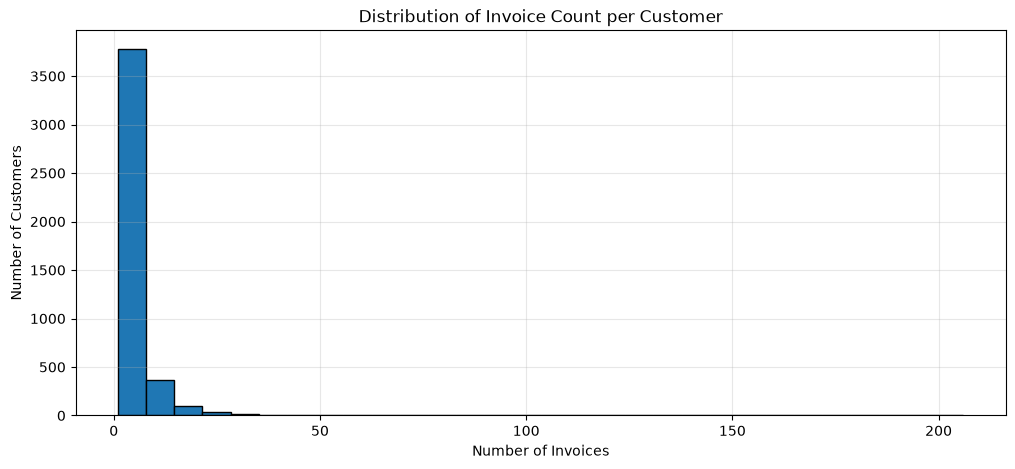

In [122]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.hist(
    customer_invoice_count,
    bins=30,
    edgecolor="black"
)

plt.title("Distribution of Invoice Count per Customer")
plt.xlabel("Number of Invoices")
plt.ylabel("Number of Customers")
plt.grid(alpha=0.3)

plt.show()

## سؤال ۷: بررسی تعداد مشتریان و توزیع تعداد فاکتورهای خرید

### هدف بررسی

هدف این مرحله، بررسی ساختار مشتریان از نظر تعداد فاکتورهای ثبت‌شده و شناسایی الگوی تکرار خرید در میان مشتریان است.

از آنجا که هر فاکتور می‌تواند شامل چندین ردیف کالایی باشد، برای محاسبه تعداد دفعات خرید هر مشتری از تعداد فاکتورهای منحصربه‌فرد استفاده می‌شود، نه تعداد ردیف‌های تراکنش.

### نتایج اولیه

پس از استخراج خریدهای معتبر، نتایج زیر به دست آمد:

- تعداد مشتریان منحصربه‌فرد: ۴٬۳۳۴
- تعداد فاکتورهای منحصربه‌فرد: ۱۸٬۴۰۲
- میانگین تعداد فاکتور به ازای هر مشتری: ۴٫۲۵
- میانه تعداد فاکتورها: ۲
- انحراف معیار: ۷٫۶۳
- حداقل تعداد فاکتور: ۱
- حداکثر تعداد فاکتور: ۲۰۶

### تحلیل توزیع

بررسی شاخص‌های آماری نشان می‌دهد که میانگین تعداد فاکتورهای مشتریان از میانه بیشتر است. همچنین، چارک اول برابر با یک و چارک سوم برابر با پنج فاکتور است.

این اختلاف نشان می‌دهد که تعداد دفعات خرید در میان مشتریان توزیع یکنواختی ندارد.

بررسی فراوانی تعداد فاکتورها نیز نشان داد که ۱٬۵۰۵ مشتری تنها یک فاکتور خرید داشته‌اند که حدود ۳۴٫۷ درصد کل مشتریان را تشکیل می‌دهد.

نمودار توزیع نیز همین الگو را تأیید می‌کند. بیشتر مشتریان در محدوده تعداد فاکتورهای پایین قرار دارند و با افزایش تعداد فاکتورها، فراوانی مشتریان کاهش پیدا می‌کند. در عین حال، دنباله بلندی در سمت راست نمودار مشاهده می‌شود که نشان‌دهنده وجود تعداد محدودی مشتری با دفعات خرید بسیار زیاد است.

### نتیجه‌گیری

توزیع تعداد فاکتورهای مشتریان به‌شدت راست‌چوله است و رفتار خرید مشتریان از نظر تکرار خرید تفاوت قابل‌توجهی دارد.

این موضوع در ادامه پروژه اهمیت دارد؛ زیرا Frequency یکی از شاخص‌های اصلی تحلیل رفتار مشتریان در بخش‌بندی K-Means و یکی از ویژگی‌های بالقوه پیش‌بینی Churn در مدل XGBoost خواهد بود.

مقادیر بسیار بالای تعداد فاکتورها نیز نباید بدون بررسی به‌عنوان داده پرت نامعتبر حذف شوند؛ زیرا ممکن است نشان‌دهنده رفتار واقعی مشتریان پرتکرار باشند.

In [124]:
customer_invoice_count.sort_values(
    ascending=False
).head(10)

CustomerID
12748.0    206
14911.0    198
17841.0    124
13089.0     97
15311.0     91
14606.0     90
12971.0     86
14646.0     72
13408.0     62
16029.0     62
Name: InvoiceNo, dtype: int64

### بررسی مشتریان با بیشترین تعداد فاکتور

برای بررسی دقیق‌تر دنباله سمت راست توزیع، ۱۰ مشتری دارای بیشترین تعداد فاکتور استخراج شدند.

نتایج نشان داد مشتری با شناسه 12748 دارای ۲۰۶ فاکتور و مشتری با شناسه 14911 دارای ۱۹۸ فاکتور است. همچنین چند مشتری دیگر نیز تعداد فاکتورهای بالایی دارند.

این مقادیر در مقایسه با میانه تعداد فاکتورها (۲) بسیار بزرگ هستند و از نظر آماری در انتهای توزیع قرار می‌گیرند.

بااین‌حال، بالا بودن تعداد فاکتور به‌تنهایی نشان‌دهنده خطای داده نیست و می‌تواند بیانگر رفتار واقعی مشتریان بسیار فعال یا پرتکرار باشد.

بنابراین در این مرحله هیچ‌یک از این مشتریان حذف نشدند و اطلاعات آن‌ها حفظ خواهد شد. تأثیر مقادیر بزرگ بر توزیع ویژگی‌ها و الگوریتم‌های خوشه‌بندی در مراحل آماده‌سازی داده‌ها بررسی می‌شود.

---

## سؤال ۸: شناسایی و بررسی داده‌های پرت (Outlier Detection)

### هدف بررسی

هدف این مرحله شناسایی مقادیر غیرمعمول در ویژگی‌های عددی تراکنش‌ها، به‌خصوص `Quantity` و `UnitPrice` است.

در داده‌های فروشگاهی ممکن است بعضی تراکنش‌ها از نظر تعداد کالای خریداری‌شده یا قیمت واحد، تفاوت زیادی با الگوی معمول سایر تراکنش‌ها داشته باشند.

این مقادیر می‌توانند ناشی از خریدهای عمده، رفتار واقعی مشتریان، خطاهای ثبت اطلاعات یا شرایط خاص تجاری باشند.

### چرا این بررسی اهمیت دارد؟

مقادیر بسیار بزرگ یا غیرمعمول می‌توانند بر محاسبات و ویژگی‌های بعدی تأثیر بگذارند. برای مثال:

- `Quantity`: تعداد کالاهای خریداری‌شده را مشخص می‌کند و در محاسبه تعداد کل کالاهای خریداری‌شده مؤثر است.
- `UnitPrice`: قیمت واحد کالا را نشان می‌دهد و در محاسبه ارزش خرید مؤثر است.
- `TotalSpend`: مجموع ارزش خرید مشتری را تحت تأثیر قرار می‌دهد.
- `AverageInvoiceValue`: میانگین ارزش فاکتورهای مشتری ممکن است تحت تأثیر چند تراکنش بسیار بزرگ قرار بگیرد.

بنابراین لازم است پیش از ساخت ویژگی‌های مشتری‌محور، توزیع این متغیرها بررسی شود.

### روش شناسایی داده‌های پرت

در این مرحله از دو روش آماری استفاده می‌شود:

**۱. روش IQR (Interquartile Range)**

ابتدا چارک اول و سوم محاسبه می‌شوند:

- Q1: صدک ۲۵
- Q3: صدک ۷۵

سپس دامنه بین چارکی محاسبه می‌شود:

\[
IQR = Q3-Q1
\]

حد پایین و بالای آماری به شکل زیر به دست می‌آیند:

\[
Lower = Q1 - 1.5 \times IQR
\]

\[
Upper = Q3 + 1.5 \times IQR
\]

مقادیر خارج از این محدوده، از نظر روش IQR به‌عنوان مقادیر پرت علامت‌گذاری می‌شوند.

**۲. بررسی صدک‌ها (Percentiles)**

صدک‌های مختلف مانند ۹۵، ۹۹ و ۹۹٫۹ بررسی می‌شوند تا مشخص شود مقادیر بزرگ در چه محدوده‌ای قرار دارند و شدت پراکندگی داده‌ها چقدر است.

### نکته مهم در تفسیر

تشخیص آماری داده پرت به معنای اشتباه بودن آن نیست.

برای مثال، خرید تعداد زیادی کالا توسط یک مشتری ممکن است کاملاً واقعی باشد. بنابراین در این مرحله هیچ رکوردی صرفاً به دلیل قرار گرفتن خارج از محدوده IQR حذف نمی‌شود.

هدف، شناسایی و شناخت این مقادیر است تا در مراحل بعدی درباره نحوه برخورد با آن‌ها تصمیم بگیریم.

In [125]:
percentiles = [0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99, 0.995, 0.999]

for column in ["Quantity", "UnitPrice"]:
    print(f"\n{'='*50}")
    print(f"Statistics for {column}")
    print("="*50)

    print(valid_purchase[column].describe(
        percentiles=percentiles
    ))


Statistics for Quantity
count    391057.000000
mean         13.148188
std         180.829232
min           1.000000
1%            1.000000
5%            1.000000
25%           2.000000
50%           6.000000
75%          12.000000
95%          40.000000
99%         120.000000
99.5%       200.000000
99.9%       504.000000
max       80995.000000
Name: Quantity, dtype: float64

Statistics for UnitPrice
count    391057.000000
mean          2.871719
std           4.281515
min           0.040000
1%            0.210000
5%            0.420000
25%           1.250000
50%           1.950000
75%           3.750000
95%           8.500000
99%          12.750000
99.5%        16.950000
99.9%        34.950000
max         649.500000
Name: UnitPrice, dtype: float64


In [126]:
outlier_results = {}

for column in ["Quantity", "UnitPrice"]:

    Q1 = valid_purchase[column].quantile(0.25)
    Q3 = valid_purchase[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outlier_mask = (
        (valid_purchase[column] < lower_bound) |
        (valid_purchase[column] > upper_bound)
    )

    outlier_results[column] = {
        "Q1": Q1,
        "Q3": Q3,
        "IQR": IQR,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound,
        "Outlier Count": outlier_mask.sum(),
        "Outlier Percentage": outlier_mask.mean() * 100
    }

outlier_summary = pd.DataFrame(outlier_results).T

print(outlier_summary)

             Q1     Q3   IQR  Lower Bound  Upper Bound  Outlier Count  \
Quantity   2.00  12.00  10.0        -13.0         27.0        25594.0   
UnitPrice  1.25   3.75   2.5         -2.5          7.5        32702.0   

           Outlier Percentage  
Quantity             6.544826  
UnitPrice            8.362464  


C:\Users\Mega system32894565\AppData\Local\Temp\ipykernel_17980\1330817908.py:7: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(


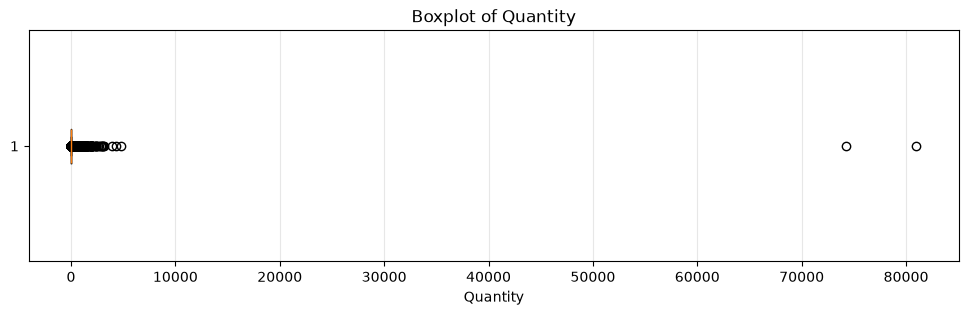

C:\Users\Mega system32894565\AppData\Local\Temp\ipykernel_17980\1330817908.py:7: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(


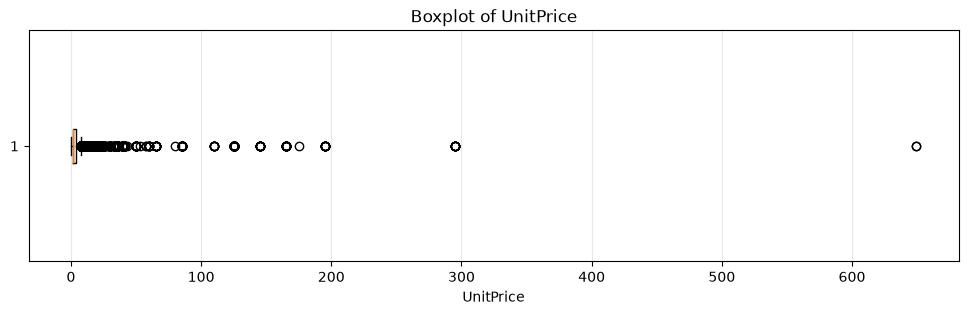

In [127]:
import matplotlib.pyplot as plt

for column in ["Quantity", "UnitPrice"]:

    plt.figure(figsize=(12, 3))

    plt.boxplot(
        valid_purchase[column].dropna(),
        vert=False,
        showfliers=True
    )

    plt.title(f"Boxplot of {column}")
    plt.xlabel(column)
    plt.grid(axis="x", alpha=0.3)

    plt.show()

In [128]:
valid_purchase.nlargest(
    20, "Quantity"
)[[
    "InvoiceNo",
    "StockCode",
    "Description",
    "Quantity",
    "UnitPrice",
    "CustomerID",
    "Country"
]]

,InvoiceNo,StockCode,Description,Quantity,UnitPrice,CustomerID,Country
540421,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2.08,16446.0,United Kingdom
61619,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,1.04,12346.0,United Kingdom
421632,573008,84077,WORLD WAR 2 GLIDERS ASSTD DESIGNS,4800,0.21,12901.0,United Kingdom
206121,554868,22197,SMALL POPCORN HOLDER,4300,0.72,13135.0,United Kingdom
97432,544612,22053,EMPIRE DESIGN ROSETTE,3906,0.82,18087.0,United Kingdom
270885,560599,18007,ESSENTIAL BALM 3.5g TIN IN ENVELOPE,3186,0.06,14609.0,United Kingdom
52711,540815,21108,FAIRY CAKE FLANNEL ASSORTED COLOUR,3114,2.10,15749.0,United Kingdom
160546,550461,21108,FAIRY CAKE FLANNEL ASSORTED COLOUR,3114,2.10,15749.0,United Kingdom
433788,573995,16014,SMALL CHINESE STYLE SCISSOR,3000,0.32,16308.0,United Kingdom
4945,536830,84077,WORLD WAR 2 GLIDERS ASSTD DESIGNS,2880,0.18,16754.0,United Kingdom


In [129]:
valid_purchase.nlargest(
    20, "UnitPrice"
)[[
    "InvoiceNo",
    "StockCode",
    "Description",
    "Quantity",
    "UnitPrice",
    "CustomerID",
    "Country"
]]

,InvoiceNo,StockCode,Description,Quantity,UnitPrice,CustomerID,Country
222680,556444,22502,PICNIC BASKET WICKER 60 PIECES,60,649.5,15098.0,United Kingdom
222682,556446,22502,PICNIC BASKET WICKER 60 PIECES,1,649.5,15098.0,United Kingdom
4989,536835,22655,VINTAGE RED KITCHEN CABINET,1,295.0,13145.0,United Kingdom
32484,539080,22655,VINTAGE RED KITCHEN CABINET,1,295.0,16607.0,United Kingdom
51636,540647,22655,VINTAGE RED KITCHEN CABINET,1,295.0,17406.0,United Kingdom
82768,543253,22655,VINTAGE RED KITCHEN CABINET,1,295.0,14842.0,United Kingdom
118769,546480,22656,VINTAGE BLUE KITCHEN CABINET,1,295.0,13452.0,United Kingdom
133994,547814,22656,VINTAGE BLUE KITCHEN CABINET,1,295.0,13452.0,United Kingdom
171178,551393,22656,VINTAGE BLUE KITCHEN CABINET,1,295.0,14973.0,United Kingdom
205759,554836,22655,VINTAGE RED KITCHEN CABINET,1,295.0,13015.0,United Kingdom


### نتایج بررسی

نتایج آمار توصیفی نشان داد که هر دو ویژگی Quantity و UnitPrice دارای توزیع راست‌چوله هستند.

در ویژگی Quantity، میانه برابر با ۶ و میانگین برابر با ۱۳٫۱۵ است؛ درحالی‌که حداکثر مقدار به ۸۰٬۹۹۵ می‌رسد. این اختلاف نشان‌دهنده وجود تعداد محدودی تراکنش با تعداد کالای بسیار زیاد است.

در ویژگی UnitPrice نیز میانه قیمت پایین‌تر از میانگین قرار دارد و حداکثر قیمت واحد برابر با ۶۴۹٫۵ است.

### نتایج روش IQR

با استفاده از روش IQR، تعداد ۲۵٬۵۹۴ رکورد (۶٫۵۴ درصد) برای Quantity و تعداد ۳۲٬۷۰۲ رکورد (۸٫۳۶ درصد) برای UnitPrice به‌عنوان مقادیر پرت آماری شناسایی شدند.

حد بالای آماری برای Quantity برابر با ۲۷ و برای UnitPrice برابر با ۷٫۵ محاسبه شد.

### بررسی نمونه‌های پرت

بررسی نمونه‌های دارای بیشترین Quantity نشان داد که برخی تراکنش‌ها شامل تعداد بسیار زیادی از یک محصول هستند. همچنین در ویژگی UnitPrice، محصولاتی مانند سبد پیک‌نیک، کابینت و صندلی فلزی دارای قیمت‌های بالاتری نسبت به سایر محصولات هستند.

این موارد نشان می‌دهند که مقادیر پرت می‌توانند ناشی از خرید عمده یا ماهیت واقعی کالا باشند و نباید صرفاً بر اساس معیارهای آماری حذف شوند.

### نتیجه‌گیری

توزیع ویژگی‌های Quantity و UnitPrice دارای چولگی مثبت و مقادیر دورافتاده است. روش IQR توانست بخش قابل‌توجهی از رکوردهای غیرمعمول را شناسایی کند؛ بااین‌حال، پرت بودن آماری به معنای نامعتبر بودن رکورد نیست.

بنابراین در این مرحله هیچ رکوردی صرفاً بر اساس مقدار پرت حذف نشد. بررسی اعتبار تراکنش‌های بسیار بزرگ در سطح فاکتور انجام خواهد شد و نحوه مدیریت اثر این مقادیر در مراحل بعدی آماده‌سازی ویژگی‌ها، به‌ویژه برای K-Means، تعیین می‌شود.

In [130]:
suspicious_invoices = [
    "581483",
    "541431",
    "556444",
    "556446"
]

invoice_details = df_no_duplicates[
    df_no_duplicates["InvoiceNo"]
    .astype("string")
    .isin(suspicious_invoices)
].copy()

invoice_details["LineTotal"] = (
    invoice_details["Quantity"] * invoice_details["UnitPrice"]
)

invoice_details[
    [
        "InvoiceNo",
        "StockCode",
        "Description",
        "Quantity",
        "UnitPrice",
        "LineTotal",
        "CustomerID"
    ]
].sort_values(
    ["InvoiceNo", "Quantity"],
    ascending=[True, False]
)

,InvoiceNo,StockCode,Description,Quantity,UnitPrice,LineTotal,CustomerID
61619,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,1.04,77183.6,12346.0
222680,556444,22502,PICNIC BASKET WICKER 60 PIECES,60,649.50,38970.0,15098.0
222682,556446,22502,PICNIC BASKET WICKER 60 PIECES,1,649.50,649.5,15098.0
540421,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2.08,168469.6,16446.0


In [131]:
invoice_summary = (
    invoice_details.groupby("InvoiceNo")
    .agg(
        CustomerID=("CustomerID", "first"),
        NumberOfLines=("StockCode", "count"),
        TotalQuantity=("Quantity", "sum"),
        TotalValue=("LineTotal", "sum"),
        MinUnitPrice=("UnitPrice", "min"),
        MaxUnitPrice=("UnitPrice", "max")
    )
)

print(invoice_summary)

           CustomerID  NumberOfLines  TotalQuantity  TotalValue  MinUnitPrice  \
InvoiceNo                                                                       
541431        12346.0              1          74215     77183.6          1.04   
556444        15098.0              1             60     38970.0        649.50   
556446        15098.0              1              1       649.5        649.50   
581483        16446.0              1          80995    168469.6          2.08   

           MaxUnitPrice  
InvoiceNo                
541431             1.04  
556444           649.50  
556446           649.50  
581483             2.08  


In [132]:
suspicious_invoices = ["541431", "581483"]

for invoice in suspicious_invoices:

    original = df_no_duplicates[
        df_no_duplicates["InvoiceNo"].astype("string") == invoice
    ]

    print(f"\n{'='*60}")
    print(f"Original Invoice: {invoice}")
    print("="*60)

    for _, row in original.iterrows():

        related_cancellations = df_no_duplicates[
            (
                df_no_duplicates["InvoiceNo"]
                .astype("string")
                .str.startswith("C", na=False)
            )
            & (df_no_duplicates["CustomerID"] == row["CustomerID"])
            & (df_no_duplicates["StockCode"] == row["StockCode"])
            & (df_no_duplicates["Quantity"] == -row["Quantity"])
        ]

        print("\nOriginal Product:", row["Description"])
        print("Original Quantity:", row["Quantity"])

        if related_cancellations.empty:
            print("No exact matching cancellation found.")
        else:
            print("Matching cancellation records:")
            display(
                related_cancellations[
                    [
                        "InvoiceNo",
                        "StockCode",
                        "Description",
                        "Quantity",
                        "UnitPrice",
                        "CustomerID",
                        "InvoiceDate"
                    ]
                ]
            )


Original Invoice: 541431

Original Product: MEDIUM CERAMIC TOP STORAGE JAR
Original Quantity: 74215
Matching cancellation records:


,InvoiceNo,StockCode,Description,Quantity,UnitPrice,CustomerID,InvoiceDate
61624,C541433,23166,MEDIUM CERAMIC TOP STORAGE JAR,-74215,1.04,12346.0,1/18/11 10:17



Original Invoice: 581483

Original Product: PAPER CRAFT , LITTLE BIRDIE
Original Quantity: 80995
Matching cancellation records:


,InvoiceNo,StockCode,Description,Quantity,UnitPrice,CustomerID,InvoiceDate
540422,C581484,23843,"PAPER CRAFT , LITTLE BIRDIE",-80995,2.08,16446.0,12/9/11 9:27


### بررسی فاکتورهای دارای مقادیر بسیار بزرگ

برای ارزیابی اعتبار مقادیر پرت، فاکتورهای دارای بیشترین تعداد کالا و بالاترین قیمت واحد به‌صورت جداگانه بررسی شدند.

نتایج نشان داد فاکتورهای 541431 و 581483 به‌ترتیب شامل 74,215 و 80,995 واحد کالا هستند. به دلیل بزرگی غیرمعمول این مقادیر، اعتبار آن‌ها نیازمند بررسی بیشتر است.

همچنین دو فاکتور 556444 و 556446 مربوط به یک مشتری و یک محصول با قیمت واحد 649.50 هستند. این موضوع نشان می‌دهد قیمت بالای یک کالا به‌تنهایی نمی‌تواند نشانه نامعتبر بودن تراکنش باشد.

در ادامه، ارتباط فاکتورهای مشکوک با رکوردهای لغوشده بررسی می‌شود؛ زیرا حذف فاکتورهای لغوشده به‌تنهایی تضمین نمی‌کند که فاکتور خرید اولیه مرتبط با آن‌ها نیز از مجموعه خریدهای معتبر کنار گذاشته شده باشد.

تا زمان تکمیل این بررسی، هیچ‌یک از رکوردهای مذکور صرفاً بر اساس مقدار آماری آن‌ها حذف نمی‌شوند.

In [133]:
confirmed_cancelled_pairs = {
    ("541431", "23166"),
    ("581483", "23843")
}

invoice_stock_pairs = pd.Series(
    list(zip(
        valid_purchase["InvoiceNo"].astype("string"),
        valid_purchase["StockCode"].astype("string")
    )),
    index=valid_purchase.index
)

keep_mask = ~invoice_stock_pairs.isin(
    confirmed_cancelled_pairs
)

valid_purchase = valid_purchase.loc[keep_mask].copy()

print("Updated Valid Purchase Shape:", valid_purchase.shape)
print("Removed Fully Cancelled Purchase Lines:", (~keep_mask).sum())

Updated Valid Purchase Shape: (391055, 10)
Removed Fully Cancelled Purchase Lines: 2


In [134]:
valid_purchase[
    valid_purchase["InvoiceNo"].astype("string").isin(
        ["541431", "581483"]
    )
]

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,StockCode_Normalized,Description_Normalized


### بررسی فاکتورهای لغوشده و اصلاح خریدهای معتبر

در ادامه بررسی مقادیر پرت، فاکتورهای دارای بیشترین مقدار Quantity با رکوردهای لغوشده تطبیق داده شدند.

نتایج نشان داد فاکتور 541431 مربوط به مشتری 12346 و محصول MEDIUM CERAMIC TOP STORAGE JAR، دارای یک رکورد لغو با شماره C541433 است. تعداد کالای فاکتور اصلی 74,215 و تعداد ثبت‌شده در فاکتور لغو 74,215- است.

همچنین فاکتور 581483 مربوط به مشتری 16446 و محصول PAPER CRAFT, LITTLE BIRDIE، دارای رکورد لغو C581484 است. تعداد کالای فاکتور اصلی 80,995 و تعداد ثبت‌شده در فاکتور لغو 80,995- است.

در هر دو مورد، شناسه مشتری، کد کالا، قیمت واحد و مقدار معکوس‌شده مطابقت داشتند. بنابراین این دو تراکنش به‌عنوان خریدهای کاملاً لغوشده شناسایی شدند.

از آنجا که در مرحله حذف فاکتورهای لغوشده، فاکتورهای اصلی لزوماً حذف نمی‌شوند، دو ردیف خرید اولیه نیز از مجموعه خریدهای معتبر مشتری‌محور کنار گذاشته شدند.

این بررسی نشان داد که برخی مقادیر بسیار بزرگ که از نظر آماری پرت محسوب می‌شوند، ممکن است ناشی از تراکنش‌های لغوشده باشند. بنابراین بررسی ارتباط تراکنش‌ها در سطح فاکتور، در کنار روش‌های آماری شناسایی داده‌های پرت، ضروری است.

سایر مقادیر غیرمعمول بدون شواهد کافی حذف نشدند و برای بررسی‌های بعدی حفظ شدند.

### نتیجه نهایی و تصمیمات مربوط به داده‌های پرت

پس از بررسی مقادیر پرت و تطبیق فاکتورهای مشکوک با رکوردهای لغوشده، دو تراکنش با شماره فاکتورهای 541431 و 581483 به‌عنوان خریدهای کاملاً لغوشده شناسایی شدند.

این دو رکورد از مجموعه خریدهای معتبر حذف شدند و تعداد ردیف‌های این مجموعه از 391,057 به 391,055 کاهش یافت.

سایر مقادیر پرت صرفاً بر اساس معیارهای آماری حذف نشدند؛ زیرا ممکن است نشان‌دهنده خرید عمده یا ویژگی واقعی محصولات باشند.

در نتیجه، داده‌های پرت آماری از تراکنش‌های نامعتبر تفکیک شدند. مقادیر غیرمعمول باقی‌مانده برای بررسی و مدیریت اثر آن‌ها در مراحل بعدی آماده‌سازی ویژگی‌ها حفظ شدند.

---

## سؤال ۹: بررسی توزیع ارزش تراکنش‌ها (Transaction Value Analysis)

### ۱. هدف بررسی

در این مرحله قصد داریم ارزش مالی محاسباتی هر ردیف خرید را بررسی کنیم تا مشخص شود مشتریان چه مقدار کالا از نظر ارزش پولی خریداری کرده‌اند و آیا تراکنش‌هایی با ارزش غیرمعمول در داده‌ها وجود دارند یا خیر.

تا این مرحله ویژگی‌های Quantity و UnitPrice را به‌صورت جداگانه بررسی کردیم؛ اما هیچ‌کدام به‌تنهایی ارزش کامل یک ردیف خرید را نشان نمی‌دهند.

برای مثال، ممکن است یک مشتری تعداد زیادی کالای ارزان‌قیمت خریداری کرده باشد یا تعداد کمی کالای گران‌قیمت. بنابراین لازم است این دو ویژگی را با یکدیگر ترکیب کنیم.

### ۲. چرا این بررسی اهمیت دارد؟

این بررسی از چند جهت برای پروژه اهمیت دارد:

- شناسایی تراکنش‌هایی با ارزش مالی بسیار بالا یا غیرمعمول.
- بررسی اثر خریدهای عمده بر توزیع ارزش تراکنش‌ها.
- آماده‌سازی داده برای محاسبه ویژگی‌های مالی مشتریان.
- فراهم کردن اطلاعات لازم برای محاسبه Monetary در تحلیل LRFM.
- کمک به شناسایی مشتریانی که سهم بیشتری در ارزش خریدها دارند.

### ۳. روش محاسبه

برای محاسبه ارزش هر ردیف خرید از رابطه زیر استفاده می‌کنیم:

\[
LineTotal = Quantity \times UnitPrice
\]

این مقدار، ارزش محاسباتی کالاهای ثبت‌شده در یک ردیف فاکتور است.

توجه داشته باشیم که LineTotal الزاماً برابر با مبلغ نهایی پرداخت‌شده توسط مشتری نیست؛ زیرا ممکن است تخفیف‌ها، هزینه ارسال، مالیات یا سایر تعدیلات مالی در آن لحاظ نشده باشند.

### ۴. مراحل بررسی

در این مرحله موارد زیر را بررسی می‌کنیم:

1. محاسبه LineTotal برای تمام ردیف‌های خرید معتبر.
2. بررسی آمار توصیفی و صدک‌های توزیع LineTotal.
3. رسم Histogram برای مشاهده شکل توزیع.
4. رسم Boxplot برای شناسایی مقادیر پرت آماری.
5. بررسی بزرگ‌ترین تراکنش‌ها و شناسایی علت احتمالی آن‌ها.

### ۵. تصمیم مورد انتظار

هدف این مرحله حذف خودکار تراکنش‌های بزرگ نیست. ابتدا باید مشخص کنیم مقادیر بزرگ ناشی از خرید عمده واقعی، قیمت بالای کالا یا خطای احتمالی در ثبت اطلاعات هستند.

در صورت مشاهده مقادیر غیرمعمول، آن‌ها را بررسی می‌کنیم و تصمیم مربوط به مدیریت اثرشان را به مراحل آماده‌سازی ویژگی‌ها و مدل‌سازی موکول خواهیم کرد.

In [135]:
valid_purchase["LineTotal"] = (
    valid_purchase["Quantity"] *
    valid_purchase["UnitPrice"]
)

valid_purchase[
    ["InvoiceNo", "Quantity", "UnitPrice", "LineTotal"]
].head(10)

,InvoiceNo,Quantity,UnitPrice,LineTotal
0,536365,6,2.55,15.30
1,536365,6,3.39,20.34
2,536365,8,2.75,22.00
3,536365,6,3.39,20.34
4,536365,6,3.39,20.34
5,536365,2,7.65,15.30
6,536365,6,4.25,25.50
7,536366,6,1.85,11.10
8,536366,6,1.85,11.10
9,536367,32,1.69,54.08


In [136]:
percentiles = [
    0.01, 0.05, 0.25, 0.50,
    0.75, 0.95, 0.99, 0.995, 0.999
]

line_total_stats = valid_purchase["LineTotal"].describe(
    percentiles=percentiles
)

print(line_total_stats)

count    391055.000000
mean         21.711190
std          94.434713
min           0.060000
1%            0.550000
5%            1.250000
25%           4.950000
50%          11.900000
75%          19.800000
95%          67.500000
99%         201.600000
99.5%       305.280000
99.9%       838.800000
max       38970.000000
Name: LineTotal, dtype: float64


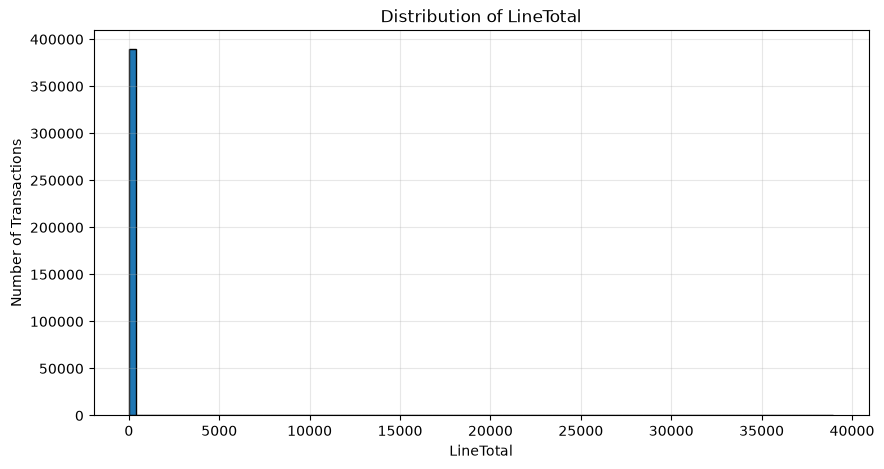

In [137]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.hist(
    valid_purchase["LineTotal"],
    bins=100,
    edgecolor="black"
)

plt.title("Distribution of LineTotal")
plt.xlabel("LineTotal")
plt.ylabel("Number of Transactions")
plt.grid(alpha=0.3)

plt.show()

In [138]:
Q1 = valid_purchase["LineTotal"].quantile(0.25)
Q3 = valid_purchase["LineTotal"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = valid_purchase[
    (valid_purchase["LineTotal"] < lower_bound) |
    (valid_purchase["LineTotal"] > upper_bound)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)
print("Outlier Count:", len(outliers))
print(
    "Outlier Percentage:",
    len(outliers) / len(valid_purchase) * 100
)

Q1: 4.949999999999999
Q3: 19.799999999999997
IQR: 14.849999999999998
Lower Bound: -17.325
Upper Bound: 42.074999999999996
Outlier Count: 30482
Outlier Percentage: 7.794811471532137


In [139]:
largest_transactions = valid_purchase.nlargest(
    20,
    "LineTotal"
)

largest_transactions[
    [
        "InvoiceNo",
        "StockCode",
        "Description",
        "Quantity",
        "UnitPrice",
        "LineTotal",
        "CustomerID",
        "Country"
    ]
]

,InvoiceNo,StockCode,Description,Quantity,UnitPrice,LineTotal,CustomerID,Country
222680,556444,22502,PICNIC BASKET WICKER 60 PIECES,60,649.50,38970.00,15098.0,United Kingdom
348325,567423,23243,SET OF TEA COFFEE SUGAR TINS PANTRY,1412,5.06,7144.72,17450.0,United Kingdom
52711,540815,21108,FAIRY CAKE FLANNEL ASSORTED COLOUR,3114,2.10,6539.40,15749.0,United Kingdom
160546,550461,21108,FAIRY CAKE FLANNEL ASSORTED COLOUR,3114,2.10,6539.40,15749.0,United Kingdom
421601,573003,23084,RABBIT NIGHT LIGHT,2400,2.08,4992.00,14646.0,Netherlands
52709,540815,85123A,WHITE HANGING HEART T-LIGHT HOLDER,1930,2.55,4921.50,15749.0,United Kingdom
160542,550461,85123A,WHITE HANGING HEART T-LIGHT HOLDER,1930,2.40,4632.00,15749.0,United Kingdom
52772,540818,48185,DOORMAT FAIRY CAKE,670,6.75,4522.50,15749.0,United Kingdom
244419,558526,23173,REGENCY TEAPOT ROSES,540,8.15,4401.00,17949.0,United Kingdom
160544,550461,48185,DOORMAT FAIRY CAKE,670,6.35,4254.50,15749.0,United Kingdom


C:\Users\Mega system32894565\AppData\Local\Temp\ipykernel_17980\2550715988.py:3: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(


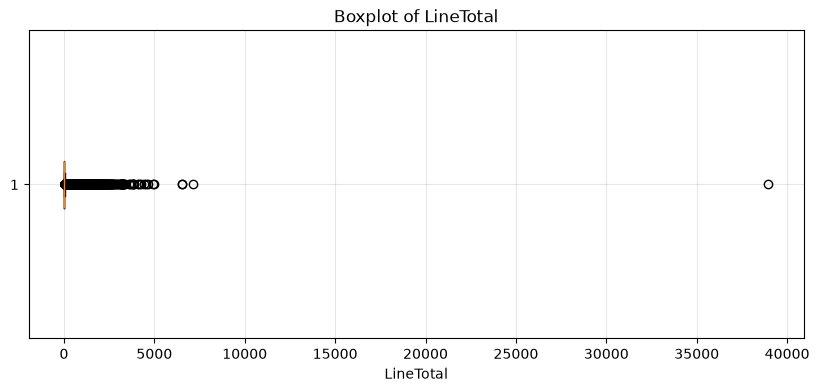

In [140]:
plt.figure(figsize=(10, 4))

plt.boxplot(
    valid_purchase["LineTotal"],
    vert=False
)

plt.title("Boxplot of LineTotal")
plt.xlabel("LineTotal")
plt.grid(alpha=0.3)

plt.show()

## نتیجه‌گیری سؤال ۹: بررسی توزیع ارزش تراکنش‌ها

در این مرحله، ویژگی LineTotal با استفاده از حاصل‌ضرب Quantity در UnitPrice محاسبه شد. هدف از این کار، بررسی ارزش محاسباتی هر ردیف خرید و آماده‌سازی داده برای استخراج ویژگی‌های مالی مشتریان بود.

تعداد ردیف‌های بررسی‌شده برابر با 391,055 بود. میانگین LineTotal برابر با 21.71 و میانه آن برابر با 11.90 به دست آمد. اختلاف میان این دو شاخص نشان‌دهنده چولگی مثبت توزیع و تأثیر مقادیر بزرگ بر میانگین است.

بررسی صدک‌ها نشان داد 99 درصد ردیف‌های خرید دارای LineTotal حداکثر برابر با 201.60 هستند؛ درحالی‌که بیشترین مقدار ثبت‌شده برابر با 38,970 است.

با استفاده از روش IQR، تعداد 30,482 ردیف، معادل 7.79 درصد از داده‌ها، به‌عنوان مقادیر پرت آماری شناسایی شدند. بااین‌حال، بررسی نمونه‌های دارای بیشترین ارزش نشان داد که بخشی از این مقادیر می‌توانند ناشی از خریدهای عمده یا قیمت بالای واقعی محصولات باشند.

بنابراین تصمیم گرفته شد مقادیر پرت صرفاً بر اساس معیارهای آماری حذف نشوند. تراکنش‌های غیرمعمول برای بررسی‌های تکمیلی حفظ شدند و مدیریت اثر آن‌ها به مراحل بعدی آماده‌سازی ویژگی‌ها موکول شد.

در نهایت، توزیع LineTotal به‌شدت راست‌چوله تشخیص داده شد و این موضوع در انتخاب روش‌های تبدیل و مقیاس‌بندی ویژگی‌های مالی در مراحل بعدی مورد توجه قرار خواهد گرفت.

---

## سؤال ۱۰: بررسی ساختار و رفتار خرید در سطح فاکتور (Invoice-Level Analysis)

### ۱. هدف بررسی

در این مرحله، ساختار تراکنش‌ها را از سطح ردیف کالا به سطح فاکتور منتقل می‌کنیم.

در دیتاست اولیه، هر ردیف نشان‌دهنده یک محصول ثبت‌شده در یک فاکتور است. بنابراین ممکن است یک فاکتور شامل چندین ردیف کالا باشد.

برای تحلیل رفتار خرید مشتریان، لازم است بدانیم هر فاکتور شامل چه تعداد کالا، چه تعداد محصول منحصربه‌فرد و چه ارزش محاسباتی است.

### ۲. چرا این بررسی اهمیت دارد؟

- جلوگیری از اشتباه گرفتن تعداد ردیف‌های کالا با تعداد دفعات خرید مشتری.
- محاسبه صحیح Frequency بر اساس تعداد فاکتورهای یکتا.
- بررسی ارزش کل هر فاکتور و تعداد کالاهای خریداری‌شده.
- شناسایی فاکتورهای غیرمعمول از نظر تعداد کالا یا ارزش خرید.
- آماده‌سازی داده برای استخراج ویژگی‌های مشتری‌محور در مراحل بعدی.

### ۳. واحد تحلیل

در این مرحله، هر فاکتور با شناسه منحصربه‌فرد InvoiceNo به‌عنوان یک مشاهده در نظر گرفته می‌شود.

### ۴. ویژگی‌های مورد بررسی

برای هر فاکتور، اطلاعات زیر استخراج می‌شوند:

- CustomerID: شناسه مشتری
- InvoiceDate: تاریخ فاکتور
- NumberOfLines: تعداد ردیف‌های کالا
- UniqueProducts: تعداد محصولات منحصربه‌فرد
- TotalQuantity: مجموع تعداد کالاها
- InvoiceValue: مجموع ارزش محاسباتی ردیف‌های فاکتور
- Country: کشور مشتری

### ۵. تصمیم مورد انتظار

در پایان این بررسی، باید مشخص شود آیا ساختار فاکتورها برای محاسبه ویژگی‌های رفتاری مشتریان مناسب است یا خیر.

همچنین فاکتورهای دارای تعداد کالا یا ارزش غیرمعمول شناسایی می‌شوند؛ اما صرفاً به دلیل بزرگ بودن، حذف نخواهند شد.

In [141]:
invoice_data = (
    valid_purchase
    .groupby("InvoiceNo")
    .agg(
        CustomerID=("CustomerID", "first"),
        InvoiceDate=("InvoiceDate", "first"),
        Country=("Country", "first"),
        NumberOfLines=("StockCode", "count"),
        UniqueProducts=("StockCode", "nunique"),
        TotalQuantity=("Quantity", "sum"),
        InvoiceValue=("LineTotal", "sum")
    )
    .reset_index()
)

print("Invoice Data Shape:", invoice_data.shape)

invoice_data.head(10)

Invoice Data Shape: (18400, 8)


,InvoiceNo,CustomerID,InvoiceDate,Country,NumberOfLines,UniqueProducts,TotalQuantity,InvoiceValue
0,536365,17850.0,12/1/10 8:26,United Kingdom,7,7,40,139.12
1,536366,17850.0,12/1/10 8:28,United Kingdom,2,2,12,22.20
2,536367,13047.0,12/1/10 8:34,United Kingdom,12,12,83,278.73
3,536368,13047.0,12/1/10 8:34,United Kingdom,4,4,15,70.05
4,536369,13047.0,12/1/10 8:35,United Kingdom,1,1,3,17.85
5,536370,12583.0,12/1/10 8:45,France,19,19,446,801.86
6,536371,13748.0,12/1/10 9:00,United Kingdom,1,1,80,204.00
7,536372,17850.0,12/1/10 9:01,United Kingdom,2,2,12,22.20
8,536373,17850.0,12/1/10 9:02,United Kingdom,16,16,88,259.86
9,536374,15100.0,12/1/10 9:09,United Kingdom,1,1,32,350.40


In [142]:
invoice_consistency = (
    valid_purchase
    .groupby("InvoiceNo")
    .agg(
        CustomerCount=("CustomerID", "nunique"),
        DateCount=("InvoiceDate", "nunique"),
        CountryCount=("Country", "nunique")
    )
)

print("Invoices with Multiple Customers:",
      (invoice_consistency["CustomerCount"] > 1).sum())

print("Invoices with Multiple Dates:",
      (invoice_consistency["DateCount"] > 1).sum())

print("Invoices with Multiple Countries:",
      (invoice_consistency["CountryCount"] > 1).sum())

Invoices with Multiple Customers: 0
Invoices with Multiple Dates: 30
Invoices with Multiple Countries: 0


In [143]:
invoice_data[
    [
        "NumberOfLines",
        "UniqueProducts",
        "TotalQuantity",
        "InvoiceValue"
    ]
].describe(
    percentiles=[
        0.25,
        0.50,
        0.75,
        0.95,
        0.99
    ]
)

,NumberOfLines,UniqueProducts,TotalQuantity,InvoiceValue
count,18400.000000,18400.000000,18400.000000,18400.000000
mean,21.252989,20.990815,271.004402,461.427687
std,24.355752,23.821427,547.541973,982.216846
min,1.000000,1.000000,1.000000,0.380000
25%,7.000000,7.000000,75.000000,157.015000
50%,15.000000,15.000000,156.000000,301.600000
75%,27.000000,27.000000,291.000000,462.970000
95%,63.000000,62.000000,778.000000,1209.902000
99%,107.000000,104.000000,2256.060000,3733.110000
max,541.000000,540.000000,15049.000000,38970.000000


In [144]:
print("Total Unique Invoices:", invoice_data["InvoiceNo"].nunique())

print("Total Unique Customers:", invoice_data["CustomerID"].nunique())

print("Total Invoice Records:", len(invoice_data))

Total Unique Invoices: 18400
Total Unique Customers: 4333
Total Invoice Records: 18400


In [145]:
multi_date_invoices = (
    invoice_consistency[
        invoice_consistency["DateCount"] > 1
    ].index
)

multi_date_details = (
    valid_purchase[
        valid_purchase["InvoiceNo"].isin(multi_date_invoices)
    ]
    .sort_values(["InvoiceNo", "InvoiceDate"])
)

print("Number of Invoices with Multiple Dates:",
      len(multi_date_invoices))

display(
    multi_date_details[
        [
            "InvoiceNo",
            "CustomerID",
            "InvoiceDate",
            "StockCode",
            "Description",
            "Quantity",
            "UnitPrice"
        ]
    ].head(50)
)

Number of Invoices with Multiple Dates: 30


,InvoiceNo,CustomerID,InvoiceDate,StockCode,Description,Quantity,UnitPrice
2421,536591,14606.0,12/1/10 16:57,21427,SKULLS STORAGE BOX SMALL,1,2.10
2422,536591,14606.0,12/1/10 16:57,22135,LADLE LOVE HEART PINK,1,0.42
2423,536591,14606.0,12/1/10 16:57,90214M,"LETTER ""M"" BLING KEY RING",1,1.25
2424,536591,14606.0,12/1/10 16:57,90214V,"LETTER ""V"" BLING KEY RING",1,1.25
2425,536591,14606.0,12/1/10 16:57,90214S,"LETTER ""S"" BLING KEY RING",1,1.25
2426,536591,14606.0,12/1/10 16:57,90214J,"LETTER ""J"" BLING KEY RING",2,1.25
2427,536591,14606.0,12/1/10 16:57,22386,JUMBO BAG PINK POLKADOT,1,1.95
2428,536591,14606.0,12/1/10 16:57,22378,WALL TIDY RETROSPOT,1,2.10
2429,536591,14606.0,12/1/10 16:57,20750,RED RETROSPOT MINI CASES,1,7.95
2430,536591,14606.0,12/1/10 16:57,21888,BINGO SET,1,3.75


In [147]:
multi_date_details = multi_date_details.copy()

multi_date_details["InvoiceDate_Parsed"] = pd.to_datetime(
    multi_date_details["InvoiceDate"],
    errors="coerce",
    format="mixed"
)

print("Original dtype:", multi_date_details["InvoiceDate"].dtype)
print("Parsed dtype:", multi_date_details["InvoiceDate_Parsed"].dtype)

print(
    "Invalid Dates:",
    multi_date_details["InvoiceDate_Parsed"].isna().sum()
)

Original dtype: str
Parsed dtype: datetime64[us]
Invalid Dates: 0


In [148]:
date_range_per_invoice = (
    multi_date_details
    .groupby("InvoiceNo")
    .agg(
        FirstDate=("InvoiceDate_Parsed", "min"),
        LastDate=("InvoiceDate_Parsed", "max"),
        NumberOfDates=("InvoiceDate_Parsed", "nunique")
    )
)

date_range_per_invoice["TimeDifference"] = (
    date_range_per_invoice["LastDate"]
    - date_range_per_invoice["FirstDate"]
)

display(
    date_range_per_invoice.sort_values(
        "TimeDifference",
        ascending=False
    )
)

,FirstDate,LastDate,NumberOfDates,TimeDifference
InvoiceNo,,,,
536591,2010-12-01 16:57:00,2010-12-01 16:58:00,2,0 days 00:01:00
540185,2011-01-05 13:40:00,2011-01-05 13:41:00,2,0 days 00:01:00
576057,2011-11-13 15:05:00,2011-11-13 15:06:00,2,0 days 00:01:00
571735,2011-10-19 10:03:00,2011-10-19 10:04:00,2,0 days 00:01:00
567183,2011-09-18 15:32:00,2011-09-18 15:33:00,2,0 days 00:01:00
563245,2011-08-15 10:53:00,2011-08-15 10:54:00,2,0 days 00:01:00
562128,2011-08-03 09:06:00,2011-08-03 09:07:00,2,0 days 00:01:00
558086,2011-06-26 11:58:00,2011-06-26 11:59:00,2,0 days 00:01:00
554116,2011-05-22 15:11:00,2011-05-22 15:12:00,2,0 days 00:01:00


## نتیجه‌گیری سؤال ۱۰: بررسی ساختار فاکتورها

پس از تجمیع داده‌ها در سطح فاکتور، تعداد ۱۸٬۴۰۰ فاکتور یکتا شناسایی شد که هرکدام به‌صورت یک رکورد مستقل در دیتاست نهایی نمایش داده می‌شوند.

بررسی سازگاری اطلاعات نشان داد هیچ فاکتوری به چند مشتری یا چند کشور مختلف نسبت داده نشده است. بااین‌حال، در ۳۰ فاکتور بیش از یک زمان ثبت‌شده مشاهده شد.

بررسی دقیق این موارد نشان داد اختلاف زمانی اولین و آخرین ردیف هر فاکتور تنها یک دقیقه است. بنابراین این اختلاف با ثبت ردیف‌های مختلف یک فاکتور در زمان‌های متوالی سازگار بوده و به‌عنوان خطای داده در نظر گرفته نشد.

در آمار توصیفی، میانگین تعداد ردیف‌های کالا در هر فاکتور حدود ۲۱٫۲۵ و میانه آن ۱۵ بود. همچنین میانگین ارزش محاسباتی فاکتور حدود ۴۶۱٫۴۳ و میانه آن ۳۰۱٫۶۰ به دست آمد.

فاصله میانگین و میانه، همراه با مقادیر بالای صدک‌های انتهایی، نشان‌دهنده وجود فاکتورهای بزرگ و توزیع نامتقارن ویژگی‌های خرید است.

در نهایت، دیتاست Invoice-Level با ۱۸٬۴۰۰ رکورد و ۴٬۳۳۳ مشتری یکتا ساخته شد. این دیتاست مبنای مناسبی برای استخراج ویژگی‌های رفتاری مشتریان، از جمله تعداد دفعات خرید، ارزش خرید و الگوی زمانی تراکنش‌ها خواهد بود.

---

## سؤال ۱۱: بررسی الگوهای زمانی خرید مشتریان

### ۱. هدف بررسی

هدف این مرحله، شناسایی الگوهای زمانی خرید مشتریان در طول دوره جمع‌آوری داده‌ها است.

با استفاده از تاریخ فاکتورها، رفتار خرید مشتریان را در بازه‌های زمانی مختلف بررسی می‌کنیم تا مشخص شود فعالیت خرید در طول زمان چگونه تغییر می‌کند.

### ۲. چرا این بررسی اهمیت دارد؟

رفتار خرید مشتریان صرفاً به تعداد دفعات خرید و ارزش مالی آن‌ها محدود نمی‌شود؛ زمان انجام خرید نیز می‌تواند اطلاعات مهمی درباره رفتار مشتری ارائه دهد.

برای مثال، ممکن است:
- تعداد فاکتورها در بعضی ماه‌ها بیشتر باشد.
- تعداد مشتریان فعال در طول زمان تغییر کند.
- خریدها در روزهای خاصی از هفته متمرکز باشند.
- فعالیت خرید در ساعات مشخصی از روز بیشتر باشد.

شناسایی این الگوها به درک بهتر رفتار مشتریان و استخراج ویژگی‌های زمانی در مراحل مدل‌سازی کمک می‌کند.

### ۳. ابعاد زمانی مورد بررسی

در این مرحله، رفتار خرید از چهار جنبه بررسی می‌شود:

1. تعداد فاکتورهای ثبت‌شده در هر ماه
2. تعداد مشتریان فعال در هر ماه
3. توزیع فاکتورها در روزهای هفته
4. توزیع فاکتورها در ساعات مختلف روز

### ۴. هدف نهایی

نتایج این بررسی برای شناخت روند فعالیت مشتریان، تشخیص تغییرات زمانی رفتار خرید و تصمیم‌گیری درباره ویژگی‌های زمانی قابل استفاده در مراحل بعدی آماده‌سازی داده‌ها مورد استفاده قرار می‌گیرند.

In [149]:
invoice_data["InvoiceDate"] = pd.to_datetime(
    invoice_data["InvoiceDate"],
    format="mixed",
    errors="coerce"
)

invoice_data["Year"] = invoice_data["InvoiceDate"].dt.year
invoice_data["Month"] = invoice_data["InvoiceDate"].dt.month

invoice_data["YearMonth"] = (
    invoice_data["InvoiceDate"].dt.to_period("M")
)

invoice_data["DayOfWeek"] = (
    invoice_data["InvoiceDate"].dt.day_name()
)

invoice_data["Hour"] = (
    invoice_data["InvoiceDate"].dt.hour
)

print("Invalid Dates:", invoice_data["InvoiceDate"].isna().sum())

display(invoice_data.head())

Invalid Dates: 0


,InvoiceNo,CustomerID,InvoiceDate,Country,NumberOfLines,UniqueProducts,TotalQuantity,InvoiceValue,Year,Month,YearMonth,DayOfWeek,Hour
0,536365,17850.0,2010-12-01 08:26:00,United Kingdom,7,7,40,139.12,2010,12,2010-12,Wednesday,8
1,536366,17850.0,2010-12-01 08:28:00,United Kingdom,2,2,12,22.20,2010,12,2010-12,Wednesday,8
2,536367,13047.0,2010-12-01 08:34:00,United Kingdom,12,12,83,278.73,2010,12,2010-12,Wednesday,8
3,536368,13047.0,2010-12-01 08:34:00,United Kingdom,4,4,15,70.05,2010,12,2010-12,Wednesday,8
4,536369,13047.0,2010-12-01 08:35:00,United Kingdom,1,1,3,17.85,2010,12,2010-12,Wednesday,8


In [150]:
monthly_invoices = (
    invoice_data
    .groupby("YearMonth")["InvoiceNo"]
    .nunique()
)

display(monthly_invoices)

YearMonth
2010-12    1394
2011-01     982
2011-02     992
2011-03    1312
2011-04    1139
2011-05    1544
2011-06    1390
2011-07    1321
2011-08    1267
2011-09    1739
2011-10    1903
2011-11    2642
2011-12     775
Freq: M, Name: InvoiceNo, dtype: int64

In [152]:
monthly_customers = (
    invoice_data
    .groupby("YearMonth")["CustomerID"]
    .nunique()
)

display(monthly_customers)

YearMonth
2010-12     884
2011-01     738
2011-02     757
2011-03     973
2011-04     853
2011-05    1054
2011-06     990
2011-07     946
2011-08     933
2011-09    1259
2011-10    1361
2011-11    1660
2011-12     613
Freq: M, Name: CustomerID, dtype: int64

In [160]:
weekday_orders = (
    invoice_data
    .groupby("DayOfWeek")["InvoiceNo"]
    .nunique()
)

weekday_order = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday"
]

weekday_orders = weekday_orders.reindex(weekday_order)
weekday_orders = weekday_orders.fillna(0)

display(weekday_orders)

DayOfWeek
Monday       2830.0
Tuesday      3155.0
Wednesday    3436.0
Thursday     4003.0
Friday       2808.0
Saturday        0.0
Sunday       2168.0
Name: InvoiceNo, dtype: float64

In [154]:
hourly_orders = (
    invoice_data
    .groupby("Hour")["InvoiceNo"]
    .nunique()
    .reindex(range(24), fill_value=0)
)

display(hourly_orders)

Hour
0        0
1        0
2        0
3        0
4        0
5        0
6        1
7       29
8      554
9     1382
10    2203
11    2262
12    3117
13    2623
14    2251
15    2021
16    1088
17     539
18     169
19     143
20      18
21       0
22       0
23       0
Name: InvoiceNo, dtype: int64

In [155]:
hourly_orders = (
    invoice_data
    .groupby("Hour")["InvoiceNo"]
    .nunique()
    .reindex(range(24), fill_value=0)
)

display(hourly_orders)

Hour
0        0
1        0
2        0
3        0
4        0
5        0
6        1
7       29
8      554
9     1382
10    2203
11    2262
12    3117
13    2623
14    2251
15    2021
16    1088
17     539
18     169
19     143
20      18
21       0
22       0
23       0
Name: InvoiceNo, dtype: int64

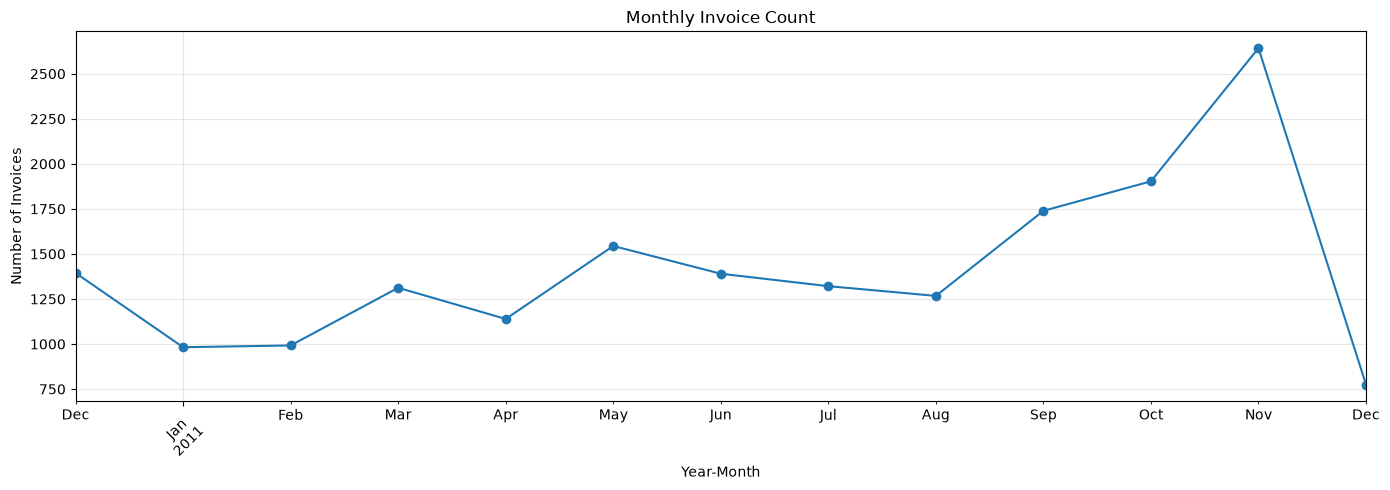

In [156]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 5))

monthly_invoices.plot(
    kind="line",
    marker="o"
)

plt.title("Monthly Invoice Count")
plt.xlabel("Year-Month")
plt.ylabel("Number of Invoices")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

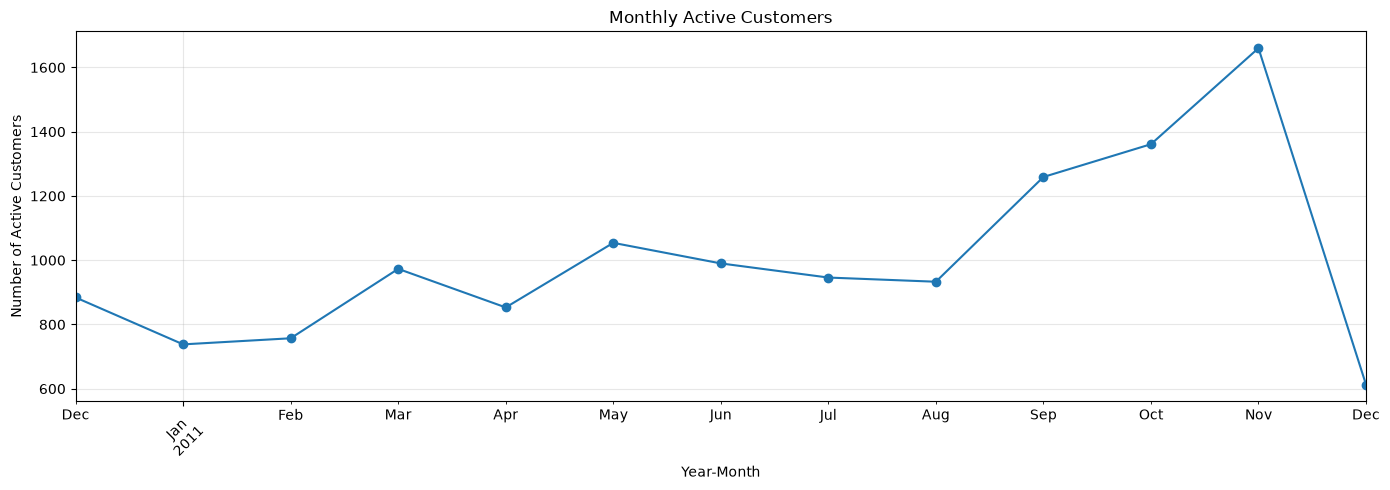

In [157]:
plt.figure(figsize=(14, 5))

monthly_customers.plot(
    kind="line",
    marker="o"
)

plt.title("Monthly Active Customers")
plt.xlabel("Year-Month")
plt.ylabel("Number of Active Customers")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

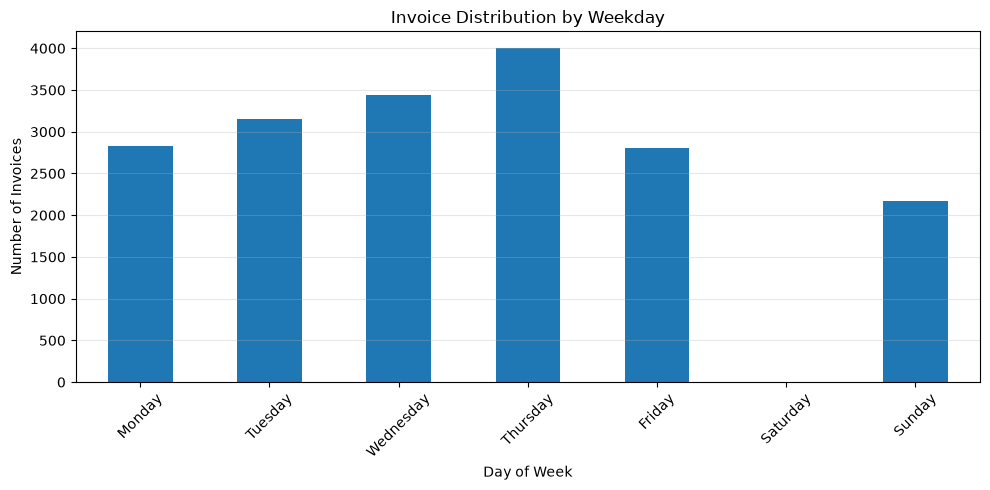

In [158]:
plt.figure(figsize=(10, 5))

weekday_orders.plot(
    kind="bar"
)

plt.title("Invoice Distribution by Weekday")
plt.xlabel("Day of Week")
plt.ylabel("Number of Invoices")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

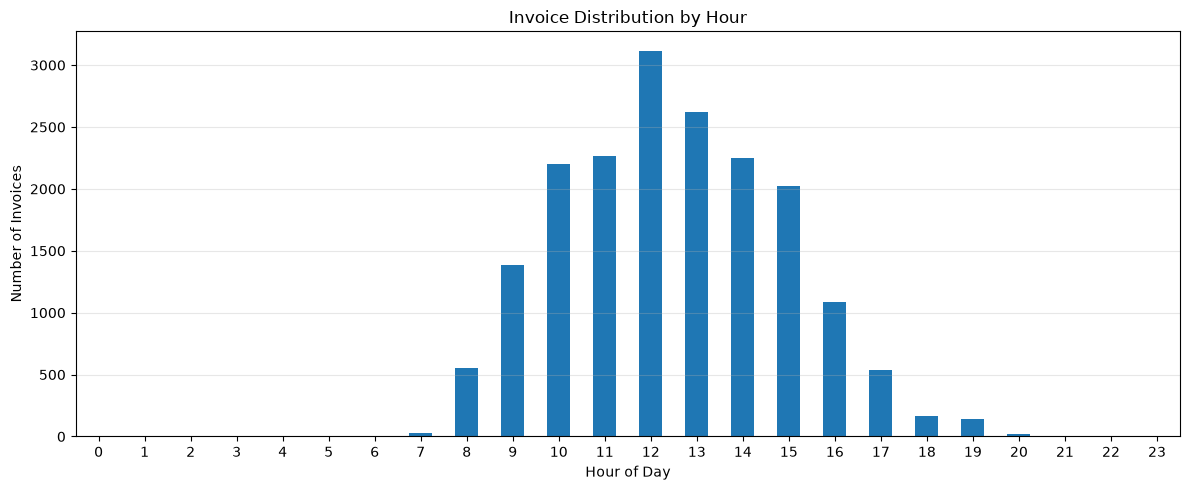

In [159]:
plt.figure(figsize=(12, 5))

hourly_orders.plot(
    kind="bar"
)

plt.title("Invoice Distribution by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Number of Invoices")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

### نتیجه‌گیری — تحلیل الگوهای زمانی خرید مشتریان (Temporal Purchase Analysis)

در این مرحله، الگوهای زمانی خرید با استفاده از داده‌های تجمیع‌شده در سطح فاکتور بررسی شدند. برای این منظور، تعداد فاکتورها و مشتریان فعال در هر ماه، توزیع فاکتورها در روزهای هفته و توزیع ساعتی سفارش‌ها مورد تحلیل قرار گرفت.

**۱. الگوی ماهانه سفارش‌ها و مشتریان فعال**

نتایج نشان داد تعداد فاکتورها و مشتریان فعال از سپتامبر ۲۰۱۱ روند افزایشی قابل‌توجهی داشته‌اند. نوامبر ۲۰۱۱ با ۲۶۴۲ فاکتور و ۱۶۶۰ مشتری فعال، بیشترین مقادیر را در میان ماه‌های بررسی‌شده داشته است.

هم‌زمانی افزایش تعداد فاکتورها و مشتریان فعال نشان می‌دهد افزایش حجم سفارش‌ها در این دوره با افزایش تعداد مشتریان خریدار نیز همراه بوده است.

بااین‌حال، دسامبر ۲۰۱۱ فقط تا روز نهم در داده‌ها پوشش داده شده است؛ بنابراین مقادیر این ماه برای مقایسه مستقیم با ماه‌های کامل مناسب نیستند.

**۲. الگوی هفتگی سفارش‌ها**

بیشترین تعداد فاکتور در روز پنجشنبه با ۴۰۰۳ فاکتور ثبت شده است. پس از آن چهارشنبه با ۳۴۳۶ و سه‌شنبه با ۳۱۵۵ فاکتور قرار دارند.

در داده‌های بررسی‌شده، هیچ فاکتوری در روز شنبه ثبت نشده است. این موضوع به‌عنوان ویژگی مشاهده‌شده در دیتاست در نظر گرفته می‌شود.

**۳. الگوی ساعتی سفارش‌ها**

بیشترین تعداد فاکتورها در ساعت ۱۲ ظهر با ۳۱۱۷ فاکتور ثبت شده است. بخش عمده سفارش‌ها در بازه زمانی ۹ صبح تا ۱۵ بعدازظهر قرار دارند و پس از ساعت ۱۷ تعداد سفارش‌ها به‌طور محسوسی کاهش می‌یابد.

این الگو نشان‌دهنده تمرکز فعالیت‌های خرید ثبت‌شده در ساعات روز است.

**۴. نتیجه کلی**

تحلیل زمانی نشان داد رفتار خرید مشتریان در طول ماه، هفته و ساعات شبانه‌روز یکنواخت نیست و دارای الگوهای مشخصی است. این اطلاعات می‌توانند در مراحل بعدی برای شناخت رفتار خرید، بررسی تغییرات فعالیت مشتریان و طراحی ویژگی‌های زمانی مورد استفاده در مدل‌سازی به کار گرفته شوند.

همچنین، این تحلیل به‌تنهایی برای تعیین ریزش مشتری کافی نیست؛ زیرا کاهش فعالیت یک مشتری در یک ماه لزوماً به معنای ریزش او نیست و باید رفتار خرید او در یک بازه زمانی مشخص بررسی شود.

---

### ۱۲-۱. بررسی توزیع تعداد فاکتورها در کشورهای مختلف (Invoice Distribution by Country)

**هدف:**

در این مرحله قصد داریم توزیع تعداد فاکتورهای ثبت‌شده را در کشورهای مختلف بررسی کنیم تا مشخص شود فعالیت تراکنشی کسب‌وکار در کدام کشورها بیشتر متمرکز شده است.

**چرا این بررسی ضروری است؟**

داده‌های ما شامل مشتریانی از کشورهای مختلف است. بنابراین قبل از بررسی عمیق‌تر رفتار مشتریان، لازم است ساختار جغرافیایی تراکنش‌ها را بشناسیم.

با محاسبه تعداد فاکتورها در هر کشور می‌توانیم بازارهایی را که بیشترین حجم سفارش را دارند شناسایی کنیم.

**روش انجام:**

داده‌های `invoice_data` را بر اساس ستون `Country` گروه‌بندی می‌کنیم و تعداد فاکتورهای منحصربه‌فرد هر کشور را با استفاده از `nunique()` محاسبه می‌کنیم.

از آنجا که هر ردیف `invoice_data` نماینده یک فاکتور است، این محاسبه در سطح فاکتور انجام می‌شود و از شمارش مجدد ردیف‌های کالایی جلوگیری می‌کند.

**فایده این بررسی:**

- شناسایی کشورهای دارای بیشترین حجم سفارش.
- شناخت میزان تمرکز فعالیت کسب‌وکار در بازارهای مختلف.
- فراهم‌کردن مبنایی برای مقایسه تعداد سفارش‌ها با تعداد مشتریان و ارزش خرید در مراحل بعدی.

**نکته:** تعداد فاکتورها به‌تنهایی نشان‌دهنده ارزش اقتصادی یک بازار نیست؛ ممکن است کشوری سفارش‌های بیشتری داشته باشد، اما میانگین ارزش هر سفارش آن کمتر باشد. به همین دلیل در مراحل بعدی شاخص‌های دیگری را نیز بررسی خواهیم کرد.

In [161]:
print("Number of Countries:", invoice_data["Country"].nunique())

country_invoice_counts = (
    invoice_data.groupby("Country")["InvoiceNo"]
    .nunique()
    .sort_values(ascending=False)
)

country_invoice_counts

Number of Countries: 37


Country
United Kingdom          16577
Germany                   443
France                    379
EIRE                      256
Belgium                    98
Netherlands                93
Spain                      88
Australia                  56
Portugal                   49
Switzerland                47
Finland                    40
Italy                      35
Sweden                     34
Norway                     32
Channel Islands            25
Japan                      19
Poland                     19
Denmark                    18
Austria                    17
Cyprus                     14
Unspecified                 8
Iceland                     7
Canada                      5
Greece                      5
USA                         5
Malta                       5
Israel                      5
Singapore                   4
Lithuania                   4
European Community          3
Bahrain                     2
United Arab Emirates        2
Czech Republic              2
Br

### نتیجه‌گیری — توزیع تعداد فاکتورها در کشورهای مختلف

بررسی تعداد فاکتورهای منحصربه‌فرد در کشورهای مختلف نشان داد که فعالیت تراکنشی کسب‌وکار به‌شدت در بریتانیا متمرکز است. بریتانیا با ۱۶٬۵۷۷ فاکتور در رتبه نخست قرار دارد و پس از آن آلمان با ۴۴۳ فاکتور و فرانسه با ۳۷۹ فاکتور قرار گرفته‌اند.

اختلاف قابل‌توجه تعداد فاکتورها میان بریتانیا و سایر کشورها نشان‌دهنده‌ی توزیع نامتوازن فعالیت تراکنشی در سطح جغرافیایی است.

همچنین برخی کشورها تنها تعداد بسیار محدودی فاکتور دارند؛ بنابراین تحلیل رفتار مشتریان در این کشورها باید با احتیاط انجام شود.

با این حال، تعداد فاکتورها به‌تنهایی معیار کافی برای ارزیابی اهمیت اقتصادی یک بازار نیست. برای بررسی دقیق‌تر، لازم است تعداد مشتریان فعال، مجموع ارزش خرید و میانگین ارزش هر فاکتور نیز در سطح کشور محاسبه شوند.

In [ ]:
country_summary = (
    invoice_data.groupby("Country")
    .agg(
        NumberOfInvoices=("InvoiceNo", "nunique"),
        NumberOfCustomers=("CustomerID", "nunique"),
        TotalQuantity=("TotalQuantity", "sum"),
        TotalValue=("InvoiceValue", "sum"),
        AverageInvoiceValue=("InvoiceValue", "mean")
    )
)

country_summary["InvoicesPerCustomer"] = (
    country_summary["NumberOfInvoices"] /
    country_summary["NumberOfCustomers"]
)

country_summary = country_summary.sort_values(
    by="NumberOfInvoices",
    ascending=False
)

country_summary.head(10)

,NumberOfInvoices,NumberOfCustomers,TotalQuantity,TotalValue,AverageInvoiceValue,InvoicesPerCustomer
Country,,,,,,
United Kingdom,16577,3915,4079011,6995912.12,422.025223,4.234227
Germany,443,94,118032,205381.15,463.614334,4.712766
France,379,87,110593,183794.44,484.945752,4.356322
EIRE,256,3,140032,257005.62,1003.928203,85.333333
Belgium,98,25,22962,36927.34,376.809592,3.920000
Netherlands,93,9,200258,283889.34,3052.573548,10.333333
Spain,88,30,27724,55706.56,633.029091,2.933333
Australia,56,9,83890,138103.81,2466.139464,6.222222
Portugal,49,19,15990,26643.90,543.753061,2.578947


### نتیجه‌گیری — تجمیع شاخص‌های خرید در سطح کشور

نتایج تجمیع شاخص‌های خرید نشان داد که بریتانیا با ۱۶٬۵۷۷ فاکتور، ۳٬۹۱۵ مشتری و ارزش کل خرید ۶٬۹۹۵٬۹۱۲٫۱۲، بزرگ‌ترین بازار از نظر حجم تراکنش، تعداد مشتریان و ارزش کل خرید در داده‌های بررسی‌شده است.

بااین‌حال، مقایسه‌ی میانگین ارزش فاکتورها نشان داد که رتبه‌بندی کشورها بر اساس ارزش متوسط سفارش با رتبه‌بندی آن‌ها بر اساس تعداد فاکتورها متفاوت است. هلند با میانگین ارزش فاکتور ۳۰۵۲٫۵۷ و استرالیا با ۲۴۶۶٫۱۴ در رتبه‌های بالاتری از بریتانیا قرار دارند.

همچنین ایرلند با ۲۵۶ فاکتور و تنها ۳ مشتری، مقدار ۸۵٫۳۳ فاکتور به‌ازای هر مشتری را نشان می‌دهد. این مقدار بیانگر تمرکز بالای تراکنش‌ها در تعداد محدودی مشتری است.

در هلند نیز با وجود تعداد کم مشتریان، مجموع تعداد کالاها و ارزش خرید قابل‌توجه است.

بنابراین، بازارهای مختلف از نظر حجم تراکنش، تعداد مشتریان، ارزش کل خرید و میانگین اندازه سفارش رفتار یکسانی ندارند.

**نکته روش‌شناختی:** میانگین ارزش فاکتور ممکن است تحت تأثیر سفارش‌های عمده و مقادیر پرت قرار گیرد. همچنین شاخص تعداد فاکتور به‌ازای هر مشتری یک میانگین کلی است و توزیع واقعی رفتار مشتریان را به‌تنهایی نشان نمی‌دهد. در نتیجه، برای تفسیر دقیق‌تر این تفاوت‌ها باید در مراحل بعدی سهم کشورها و توزیع ارزش سفارش‌ها نیز بررسی شود.

In [163]:
total_invoices = country_summary["NumberOfInvoices"].sum()
total_value = country_summary["TotalValue"].sum()

country_summary["InvoiceSharePercent"] = (
    country_summary["NumberOfInvoices"] / total_invoices
) * 100

country_summary["ValueSharePercent"] = (
    country_summary["TotalValue"] / total_value
) * 100

country_summary[
    [
        "NumberOfInvoices",
        "TotalValue",
        "InvoiceSharePercent",
        "ValueSharePercent"
    ]
].head(10)

,NumberOfInvoices,TotalValue,InvoiceSharePercent,ValueSharePercent
Country,,,,
United Kingdom,16577,6995912.12,90.092391,82.399177
Germany,443,205381.15,2.407609,2.419018
France,379,183794.44,2.059783,2.164766
EIRE,256,257005.62,1.391304,3.027061
Belgium,98,36927.34,0.532609,0.434937
Netherlands,93,283889.34,0.505435,3.343702
Spain,88,55706.56,0.478261,0.656122
Australia,56,138103.81,0.304348,1.626613
Portugal,49,26643.90,0.266304,0.313817


### نتیجه‌گیری — سهم کشورها از کل فاکتورها و ارزش خرید

محاسبه سهم نسبی کشورها نشان داد که بریتانیا با اختصاص ۹۰٫۰۹ درصد از کل فاکتورها و ۸۲٫۴۰ درصد از کل ارزش خرید، بازار اصلی کسب‌وکار از نظر حجم تراکنش و ارزش اقتصادی است.

بااین‌حال، مقایسه سهم فاکتورها و سهم ارزش خرید نشان داد که این دو شاخص در تمام کشورها یکسان نیستند.

برای مثال، هلند با سهم ۰٫۵۱ درصدی از تعداد فاکتورها، حدود ۳٫۳۴ درصد از ارزش کل خرید را به خود اختصاص داده است. همچنین استرالیا با سهم ۰٫۳۰ درصدی از فاکتورها، حدود ۱٫۶۳ درصد از ارزش خرید را ایجاد کرده است.

در مقابل، بلژیک سهم ۰٫۵۳ درصدی از فاکتورها و سهم ۰٫۴۳ درصدی از ارزش خرید دارد.

این تفاوت‌ها نشان می‌دهند که حجم تراکنش و ارزش اقتصادی سفارش‌ها در کشورهای مختلف رفتار یکسانی ندارند و رتبه‌بندی کشورها بر اساس تعداد فاکتورها لزوماً با رتبه‌بندی آن‌ها بر اساس ارزش خرید یکسان نیست.

**محدودیت تحلیل:** سهم بالاتر ارزش خرید نسبت به سهم فاکتورها به‌تنهایی نشان‌دهنده سودآوری بیشتر یک کشور نیست. همچنین در کشورهایی با تعداد مشتریان و فاکتورهای محدود، مقادیر میانگین و سهم ارزش خرید ممکن است تحت تأثیر سفارش‌های بزرگ قرار بگیرند.

In [164]:
top_countries_by_invoices = country_summary.sort_values(
    by="NumberOfInvoices",
    ascending=False
).head(10)

top_countries_by_value = country_summary.sort_values(
    by="TotalValue",
    ascending=False
).head(10)

top_countries_by_average_value = country_summary.sort_values(
    by="AverageInvoiceValue",
    ascending=False
).head(10)

print("Top Countries by Number of Invoices:")
display(top_countries_by_invoices)

print("Top Countries by Total Value:")
display(top_countries_by_value)

print("Top Countries by Average Invoice Value:")
display(top_countries_by_average_value)

Top Countries by Number of Invoices:


,NumberOfInvoices,NumberOfCustomers,TotalQuantity,TotalValue,AverageInvoiceValue,InvoicesPerCustomer,InvoiceSharePercent,ValueSharePercent
Country,,,,,,,,
United Kingdom,16577,3915,4079011,6995912.12,422.025223,4.234227,90.092391,82.399177
Germany,443,94,118032,205381.15,463.614334,4.712766,2.407609,2.419018
France,379,87,110593,183794.44,484.945752,4.356322,2.059783,2.164766
EIRE,256,3,140032,257005.62,1003.928203,85.333333,1.391304,3.027061
Belgium,98,25,22962,36927.34,376.809592,3.920000,0.532609,0.434937
Netherlands,93,9,200258,283889.34,3052.573548,10.333333,0.505435,3.343702
Spain,88,30,27724,55706.56,633.029091,2.933333,0.478261,0.656122
Australia,56,9,83890,138103.81,2466.139464,6.222222,0.304348,1.626613
Portugal,49,19,15990,26643.90,543.753061,2.578947,0.266304,0.313817


Top Countries by Total Value:


,NumberOfInvoices,NumberOfCustomers,TotalQuantity,TotalValue,AverageInvoiceValue,InvoicesPerCustomer,InvoiceSharePercent,ValueSharePercent
Country,,,,,,,,
United Kingdom,16577,3915,4079011,6995912.12,422.025223,4.234227,90.092391,82.399177
Netherlands,93,9,200258,283889.34,3052.573548,10.333333,0.505435,3.343702
EIRE,256,3,140032,257005.62,1003.928203,85.333333,1.391304,3.027061
Germany,443,94,118032,205381.15,463.614334,4.712766,2.407609,2.419018
France,379,87,110593,183794.44,484.945752,4.356322,2.059783,2.164766
Australia,56,9,83890,138103.81,2466.139464,6.222222,0.304348,1.626613
Spain,88,30,27724,55706.56,633.029091,2.933333,0.478261,0.656122
Switzerland,47,21,29980,52441.95,1115.786170,2.238095,0.255435,0.617671
Japan,19,8,26016,37416.37,1969.282632,2.375000,0.103261,0.440697


Top Countries by Average Invoice Value:


,NumberOfInvoices,NumberOfCustomers,TotalQuantity,TotalValue,AverageInvoiceValue,InvoicesPerCustomer,InvoiceSharePercent,ValueSharePercent
Country,,,,,,,,
Netherlands,93,9,200258,283889.34,3052.573548,10.333333,0.505435,3.343702
Australia,56,9,83890,138103.81,2466.139464,6.222222,0.304348,1.626613
Singapore,4,1,5234,9120.39,2280.097500,4.000000,0.021739,0.107422
Japan,19,8,26016,37416.37,1969.282632,2.375000,0.103261,0.440697
Lebanon,1,1,386,1693.88,1693.880000,1.000000,0.005435,0.019951
Israel,5,3,4043,7215.84,1443.168000,1.666667,0.027174,0.084990
Brazil,1,1,356,1143.60,1143.600000,1.000000,0.005435,0.013470
Switzerland,47,21,29980,52441.95,1115.786170,2.238095,0.255435,0.617671
Sweden,34,8,36037,36828.83,1083.200882,4.250000,0.184783,0.433777


### بررسی و مقایسه کشورهای برتر بر اساس شاخص‌های خرید

در این مرحله، کشورها بر اساس سه شاخص تعداد فاکتور، ارزش کل خرید و میانگین ارزش هر فاکتور رتبه‌بندی و مقایسه شدند.

نتایج نشان داد که بریتانیا از نظر تعداد فاکتور و ارزش کل خرید، بازار اصلی مجموعه داده است. با این حال، رتبه‌بندی بر اساس میانگین ارزش فاکتور تفاوت قابل‌توجهی داشت؛ به‌طوری‌که هلند و استرالیا با وجود تعداد فاکتور و مشتری کمتر، میانگین ارزش فاکتور بالاتری نسبت به بریتانیا داشتند.

همچنین کشورهایی مانند سنگاپور، لبنان و برزیل در رتبه‌بندی میانگین ارزش فاکتور جایگاه بالایی داشتند، اما تعداد بسیار کم فاکتورهای آن‌ها باعث می‌شود این رتبه‌بندی با احتیاط تفسیر شود. در چنین شرایطی، تعداد مشاهدات و مشتریان باید در کنار میانگین بررسی شود.

این تحلیل نشان داد که حجم فعالیت، ارزش کل خرید و میانگین ارزش سفارش، ابعاد متفاوتی از رفتار خرید کشورها را توصیف می‌کنند. بنابراین برای ارزیابی دقیق‌تر بازارها باید این شاخص‌ها به‌صورت مکمل استفاده شوند.

**نتیجه:** بریتانیا از نظر حجم و ارزش کل خرید بازار غالب است؛ در حالی که هلند و استرالیا از نظر میانگین ارزش فاکتور قابل‌توجه‌اند. این تفاوت‌ها مبنای مناسبی برای بررسی‌های آماری و تحلیل دقیق‌تر رفتار مشتریان در مراحل بعدی فراهم می‌کنند.

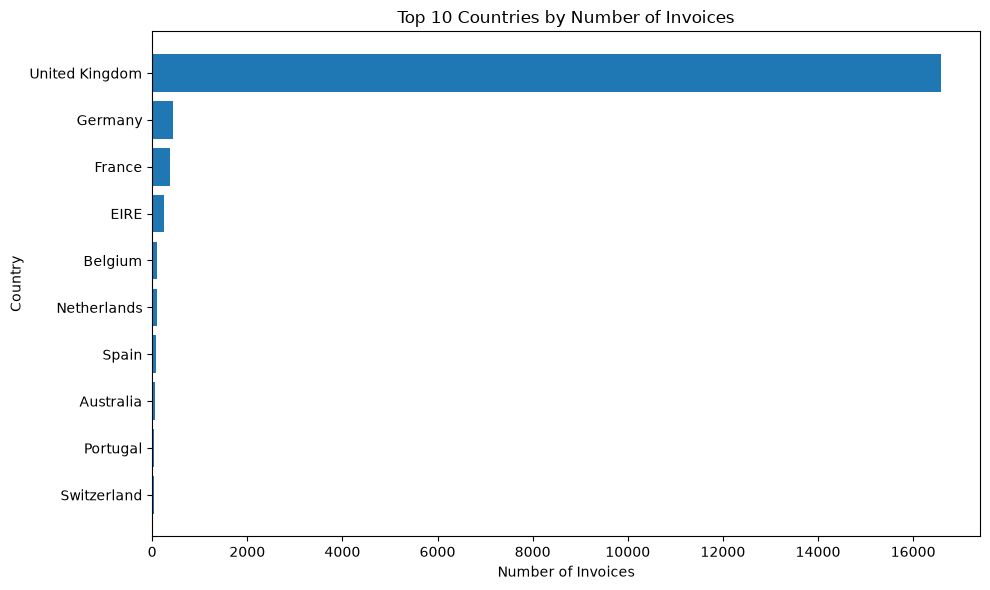

In [165]:
import matplotlib.pyplot as plt

top_countries_by_invoices = (
    country_summary
    .sort_values(by="NumberOfInvoices", ascending=False)
    .head(10)
    .sort_values(by="NumberOfInvoices", ascending=True)
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_countries_by_invoices.index,
    top_countries_by_invoices["NumberOfInvoices"]
)

plt.title("Top 10 Countries by Number of Invoices")
plt.xlabel("Number of Invoices")
plt.ylabel("Country")

plt.tight_layout()
plt.show()

### تحلیل توزیع تعداد فاکتورها در کشورهای مختلف

نمودار میله‌ای تعداد فاکتورهای ثبت‌شده در ده کشور برتر نشان می‌دهد که فعالیت تراکنشی مجموعه داده به‌شدت در بریتانیا متمرکز است. بریتانیا با ۱۶٬۵۷۷ فاکتور در جایگاه نخست قرار دارد و اختلاف قابل‌توجهی با آلمان، فرانسه و سایر کشورها دارد.

آلمان با ۴۴۳ و فرانسه با ۳۷۹ فاکتور، پس از بریتانیا قرار گرفته‌اند. این اختلاف نشان می‌دهد که بریتانیا از نظر حجم تراکنش‌ها بازار غالب مجموعه داده است.

همچنین به دلیل اختلاف زیاد مقادیر، میله‌های مربوط به سایر کشورها در مقیاس خطی نمودار فشرده دیده می‌شوند. این مسئله ناشی از تفاوت واقعی حجم تراکنش‌هاست و در صورت نیاز می‌توان برای بررسی دقیق‌تر سایر کشورها، نموداری جداگانه با حذف بریتانیا تهیه کرد.

**نتیجه:** تعداد فاکتورهای ثبت‌شده در بریتانیا به‌مراتب بیشتر از سایر کشورهاست؛ بنابراین بخش عمده فعالیت تراکنشی مجموعه داده در این کشور انجام شده است.

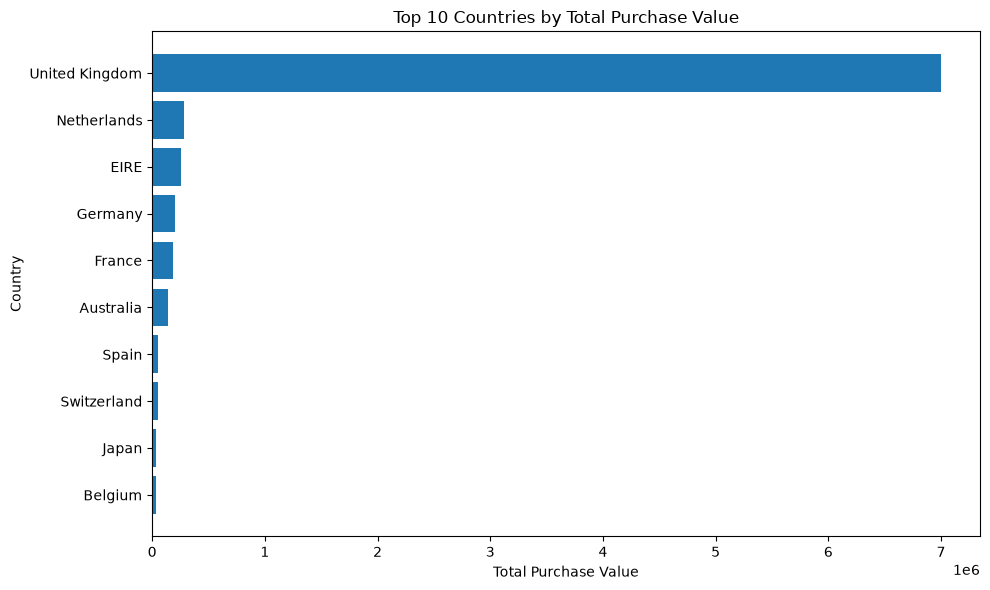

In [166]:
top_countries_by_value = (
    country_summary
    .sort_values(by="TotalValue", ascending=False)
    .head(10)
    .sort_values(by="TotalValue", ascending=True)
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_countries_by_value.index,
    top_countries_by_value["TotalValue"]
)

plt.title("Top 10 Countries by Total Purchase Value")
plt.xlabel("Total Purchase Value")
plt.ylabel("Country")

plt.tight_layout()
plt.show()

### تحلیل توزیع ارزش کل خرید در کشورهای مختلف

نمودار میله‌ای ارزش کل خرید در ده کشور برتر نشان می‌دهد که بریتانیا با مجموع ارزش تقریبی ۶٫۹۹ میلیون، سهم بسیار بیشتری نسبت به سایر کشورها دارد و در رتبه نخست قرار گرفته است.

پس از بریتانیا، هلند و ایرلند (EIRE) به‌ترتیب در رتبه‌های دوم و سوم قرار دارند. نکته قابل‌توجه، جایگاه هلند است؛ این کشور با وجود تعداد فاکتورهای کمتر نسبت به آلمان و فرانسه، ارزش کل خرید بیشتری ثبت کرده است.

همچنین استرالیا و ژاپن با وجود تعداد فاکتورهای نسبتاً کم، در میان ده کشور برتر از نظر ارزش کل خرید قرار گرفته‌اند. این موضوع نشان می‌دهد که رتبه‌بندی کشورها بر اساس ارزش کل خرید با رتبه‌بندی تعداد فاکتورها تفاوت دارد.

**نتیجه:** بریتانیا بازار غالب از نظر ارزش کل خرید است؛ بااین‌حال، کشورهایی مانند هلند و استرالیا نیز با وجود حجم تراکنش کمتر، ارزش کل خرید قابل‌توجهی دارند. بنابراین بررسی هم‌زمان تعداد فاکتورها و ارزش کل خرید برای شناخت بهتر الگوی فعالیت کشورها ضروری است.

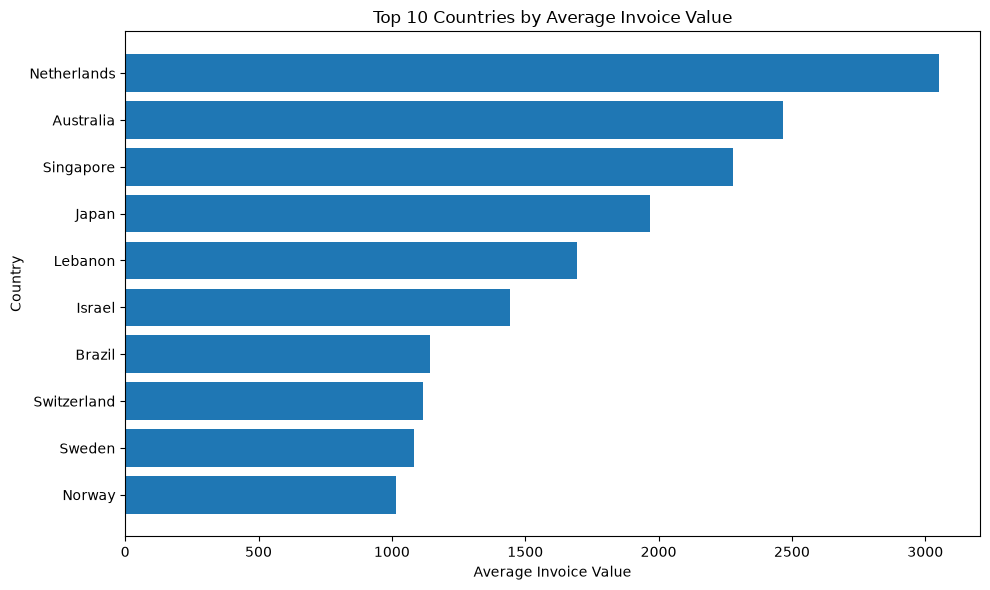

In [167]:
top_countries_by_average_value = (
    country_summary
    .sort_values(by="AverageInvoiceValue", ascending=False)
    .head(10)
    .sort_values(by="AverageInvoiceValue", ascending=True)
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_countries_by_average_value.index,
    top_countries_by_average_value["AverageInvoiceValue"]
)

plt.title("Top 10 Countries by Average Invoice Value")
plt.xlabel("Average Invoice Value")
plt.ylabel("Country")

plt.tight_layout()
plt.show()

### تحلیل میانگین ارزش فاکتور در کشورهای مختلف

نمودار میانگین ارزش فاکتور در ده کشور برتر نشان می‌دهد که هلند با میانگین تقریبی ۳۰۵۲٫۵۷ در رتبه نخست قرار دارد. پس از آن استرالیا با ۲۴۶۶٫۱۴، سنگاپور با ۲۲۸۰٫۱۰ و ژاپن با ۱۹۶۹٫۲۸ قرار گرفته‌اند.

نتایج نشان می‌دهد کشورهایی که از نظر تعداد فاکتور یا ارزش کل خرید در رتبه‌های نخست قرار ندارند، ممکن است از نظر میانگین ارزش هر فاکتور عملکرد متفاوتی داشته باشند.

بااین‌حال، تعداد فاکتورها و مشتریان در تفسیر این شاخص اهمیت زیادی دارد. برای مثال، میانگین سنگاپور بر اساس چهار فاکتور از یک مشتری و میانگین لبنان و برزیل بر اساس تنها یک فاکتور محاسبه شده است. بنابراین نمی‌توان این مقادیر را به‌عنوان الگوی عمومی خرید مشتریان این کشورها در نظر گرفت.

**نتیجه:** هلند و استرالیا از نظر میانگین ارزش فاکتور برجسته هستند؛ اما برای تفسیر قابل‌اعتماد این تفاوت‌ها باید حجم نمونه و تعداد مشتریان نیز در نظر گرفته شود. میانگین ارزش فاکتور در کنار تعداد فاکتورها و ارزش کل خرید، تصویر کامل‌تری از الگوی خرید کشورها ارائه می‌دهد.

---

### سؤال ۱۳: پرتکرارترین محصولات از نظر تعداد ردیف‌های ثبت‌شده کدام‌اند؟

**هدف:** شناسایی محصولاتی که بیشترین تعداد دفعات در ردیف‌های تراکنش ثبت شده‌اند.

**چرا این تحلیل را انجام می‌دهیم؟**

در مجموعه داده Online Retail هر ردیف نشان‌دهنده یک قلم محصول در یک فاکتور است. بنابراین با شمارش تعداد ردیف‌های مربوط به هر محصول می‌توانیم محصولاتی را شناسایی کنیم که بیشتر در تراکنش‌های ثبت‌شده حضور داشته‌اند.

**روش انجام تحلیل:**

- از دیتافریم `valid_purchase` استفاده می‌کنیم؛ زیرا در مراحل قبلی، تراکنش‌های نامعتبر، کالاهای غیرتجاری و ردیف‌های خریدی که به‌طور کامل لغو شده بودند، از مجموعه خریدهای معتبر مشتریان کنار گذاشته شده‌اند.
- شناسه محصول (`StockCode_Normalized`) را مبنای شناسایی محصول قرار می‌دهیم.
- تعداد ردیف‌های ثبت‌شده برای هر محصول را با شمارش رکوردها محاسبه می‌کنیم.
- تعداد فاکتورهای متمایز و مجموع تعداد واحدهای فروخته‌شده را نیز برای شناخت بهتر محصولات در کنار تعداد ردیف‌ها نگه می‌داریم.
- محصولات را بر اساس تعداد ردیف‌های ثبت‌شده به‌صورت نزولی مرتب می‌کنیم.

**چرا از تعداد ردیف‌ها استفاده می‌کنیم؟**

تعداد ردیف‌ها نشان می‌دهد یک محصول در چند قلم ثبت‌شده از تراکنش‌ها حضور داشته است. این شاخص با مجموع تعداد واحدهای فروخته‌شده (`Quantity`) متفاوت است؛ برای مثال ممکن است یک محصول در یک فاکتور با تعداد ۱۰۰ واحد ثبت شده باشد، اما همچنان فقط یک ردیف تراکنش داشته باشد.

**مزیت این تحلیل:**

- شناسایی محصولات پرتکرار در تراکنش‌ها
- شناخت محصولات رایج در سبد خرید مشتریان
- فراهم‌کردن زمینه برای بررسی محبوبیت محصولات و الگوهای خرید
- ایجاد اطلاعات اولیه برای تحلیل‌های بعدی محصول‌محور

**خروجی مورد انتظار:** جدولی شامل شناسه محصول، تعداد ردیف‌های ثبت‌شده، تعداد فاکتورهای متمایز و مجموع واحدهای فروخته‌شده، مرتب‌شده بر اساس تعداد ردیف‌ها.

In [168]:
product_frequency = (
    valid_purchase
    .groupby("StockCode_Normalized")
    .agg(
        Description=("Description_Normalized", "first"),
        NumberOfLines=("InvoiceNo", "size"),
        NumberOfInvoices=("InvoiceNo", "nunique"),
        TotalQuantity=("Quantity", "sum")
    )
    .sort_values(
        by="NumberOfLines",
        ascending=False
    )
)

top_20_products = product_frequency.head(20)

display(top_20_products)

,Description,NumberOfLines,NumberOfInvoices,TotalQuantity
StockCode_Normalized,,,,
85123A,WHITE HANGING HEART T-LIGHT HOLDER,2023,1978,36763
22423,REGENCY CAKESTAND 3 TIER,1713,1703,12374
85099B,JUMBO BAG RED RETROSPOT,1615,1600,46078
84879,ASSORTED COLOUR BIRD ORNAMENT,1395,1375,35263
47566,PARTY BUNTING,1389,1379,15279
20725,LUNCH BAG RED RETROSPOT,1304,1289,17776
22720,SET OF 3 CAKE TINS PANTRY DESIGN,1152,1146,7010
23203,JUMBO BAG DOILEY PATTERNS,1091,1080,19498
20727,LUNCH BAG BLACK SKULL.,1078,1052,11246


### تحلیل پرتکرارترین محصولات بر اساس تعداد ردیف‌های تراکنش

در این مرحله، محصولات بر اساس تعداد ردیف‌های ثبت‌شده در تراکنش‌های معتبر مشتریان رتبه‌بندی شدند.

نتایج نشان داد محصول `WHITE HANGING HEART T-LIGHT HOLDER` با شناسه `85123A` و تعداد ۲۰۲۳ ردیف، پرتکرارترین محصول در مجموعه داده است. پس از آن، محصولات `REGENCY CAKESTAND 3 TIER` و `JUMBO BAG RED RETROSPOT` در رتبه‌های دوم و سوم قرار گرفتند.

همچنین مقایسه تعداد ردیف‌ها با تعداد فاکتورهای متمایز نشان داد که این دو شاخص یکسان نیستند؛ زیرا یک محصول ممکن است بیش از یک بار در یک فاکتور ثبت شده باشد.

نکته قابل‌توجه دیگر، تفاوت تعداد ردیف‌ها با مجموع واحدهای فروخته‌شده است. برای مثال، محصول `SMALL POPCORN HOLDER` با وجود تعداد ردیف کمتر نسبت به محصول اول، مجموع واحدهای فروخته‌شده بیشتری دارد.

**نتیجه:** تعداد ردیف‌های ثبت‌شده شاخصی برای بررسی میزان حضور محصولات در تراکنش‌هاست، اما به‌تنهایی میزان فروش واحدی محصولات را نشان نمی‌دهد. بنابراین برای شناخت دقیق‌تر محصولات پرفروش، باید مجموع تعداد واحدهای فروخته‌شده نیز به‌صورت مستقل بررسی شود.

In [169]:
product_quantity = (
    valid_purchase
    .groupby("StockCode_Normalized")
    .agg(
        Description=("Description_Normalized", "first"),
        TotalQuantity=("Quantity", "sum"),
        NumberOfLines=("InvoiceNo", "size"),
        NumberOfInvoices=("InvoiceNo", "nunique")
    )
    .sort_values(
        by="TotalQuantity",
        ascending=False
    )
)

top_20_products_by_quantity = product_quantity.head(20)

display(top_20_products_by_quantity)

,Description,TotalQuantity,NumberOfLines,NumberOfInvoices
StockCode_Normalized,,,,
84077,WORLD WAR 2 GLIDERS ASSTD DESIGNS,54319,472,472
22197,SMALL POPCORN HOLDER,49160,1060,1035
85099B,JUMBO BAG RED RETROSPOT,46078,1615,1600
85123A,WHITE HANGING HEART T-LIGHT HOLDER,36763,2023,1978
84879,ASSORTED COLOUR BIRD ORNAMENT,35263,1395,1375
21212,PACK OF 72 RETROSPOT CAKE CASES,33670,1050,1029
23084,RABBIT NIGHT LIGHT,27153,823,801
22492,MINI PAINT SET VINTAGE,26076,325,325
22616,PACK OF 12 LONDON TISSUES,25329,392,382


### تحلیل محصولات بر اساس مجموع تعداد واحدهای فروخته‌شده

در این مرحله، محصولات بر اساس مجموع مقادیر ثبت‌شده در ستون `Quantity` رتبه‌بندی شدند تا محصولاتی که بیشترین تعداد واحد از آن‌ها فروخته شده است شناسایی شوند.

نتایج نشان داد محصول `WORLD WAR 2 GLIDERS ASSTD DESIGNS` با شناسه `84077` و مجموع ۵۴٬۳۱۹ واحد، در رتبه نخست قرار دارد. پس از آن محصولات `SMALL POPCORN HOLDER` با ۴۹٬۱۶۰ واحد و `JUMBO BAG RED RETROSPOT` با ۴۶٬۰۷۸ واحد قرار گرفتند.

مقایسه این نتایج با رتبه‌بندی تعداد ردیف‌ها نشان داد که محبوبیت یک محصول از نظر حضور در تراکنش‌ها الزاماً با حجم واحدهای فروخته‌شده آن یکسان نیست. برای مثال، محصول `WORLD WAR 2 GLIDERS ASSTD DESIGNS` با وجود قرار نگرفتن در میان ۲۰ محصول پرتکرار مرحله قبل، از نظر مجموع تعداد واحدهای فروخته‌شده رتبه نخست را کسب کرد.

همچنین محصول `WHITE HANGING HEART T-LIGHT HOLDER` که از نظر تعداد ردیف‌ها رتبه اول را داشت، از نظر مجموع واحدهای فروخته‌شده در رتبه چهارم قرار گرفت.

**نتیجه:** تعداد ردیف‌های تراکنش و مجموع تعداد واحدهای فروخته‌شده دو شاخص متفاوت برای تحلیل محصولات هستند. استفاده هم‌زمان از این دو شاخص، شناخت دقیق‌تری از میزان حضور محصولات در تراکنش‌ها و حجم فروش واحدی آن‌ها فراهم می‌کند.

In [170]:
product_value = (
    valid_purchase
    .groupby("StockCode_Normalized")
    .agg(
        Description=("Description_Normalized", "first"),
        TotalValue=("LineTotal", "sum"),
        TotalQuantity=("Quantity", "sum"),
        NumberOfLines=("InvoiceNo", "size"),
        NumberOfInvoices=("InvoiceNo", "nunique")
    )
    .sort_values(
        by="TotalValue",
        ascending=False
    )
)

top_20_products_by_value = product_value.head(20)

display(top_20_products_by_value)

,Description,TotalValue,TotalQuantity,NumberOfLines,NumberOfInvoices
StockCode_Normalized,,,,,
22423,REGENCY CAKESTAND 3 TIER,142264.75,12374,1713,1703
85123A,WHITE HANGING HEART T-LIGHT HOLDER,100547.45,36763,2023,1978
85099B,JUMBO BAG RED RETROSPOT,85040.54,46078,1615,1600
47566,PARTY BUNTING,68785.23,15279,1389,1379
84879,ASSORTED COLOUR BIRD ORNAMENT,56413.03,35263,1395,1375
23084,RABBIT NIGHT LIGHT,51251.24,27153,823,801
22502,PICNIC BASKET WICKER SMALL,47348.35,1485,236,234
79321,CHILLI LIGHTS,46265.11,9646,521,519
22086,PAPER CHAIN KIT 50'S CHRISTMAS,42584.13,15591,1003,980


### تحلیل محصولات بر اساس ارزش کل فروش

در این مرحله، محصولات بر اساس مجموع ارزش خطوط خرید (`LineTotal`) رتبه‌بندی شدند تا محصولاتی که بیشترین ارزش مالی ثبت‌شده را ایجاد کرده‌اند شناسایی شوند.

نتایج نشان داد محصول `REGENCY CAKESTAND 3 TIER` با شناسه `22423` و ارزش کل ۱۴۲٬۲۶۴٫۷۵ در رتبه نخست قرار دارد. پس از آن، محصولات `WHITE HANGING HEART T-LIGHT HOLDER` با ارزش ۱۰۰٬۵۴۷٫۴۵ و `JUMBO BAG RED RETROSPOT` با ارزش ۸۵٬۰۴۰٫۵۴ قرار گرفتند.

مقایسه این نتایج با دو مرحله قبلی نشان داد که رتبه‌بندی بر اساس ارزش کل فروش با تعداد ردیف‌ها و مجموع تعداد واحدهای فروخته‌شده متفاوت است.

برای مثال، محصول `PICNIC BASKET WICKER SMALL` با وجود مجموع فروش ۱٬۴۸۵ واحد و تنها ۲۳۶ ردیف، در رتبه هفتم ارزش کل فروش قرار گرفت. در مقابل، محصول `SMALL POPCORN HOLDER` با ۴۹٬۱۶۰ واحد فروش، در رتبه سیزدهم ارزش کل قرار دارد.

این تفاوت نشان می‌دهد که قیمت واحد محصولات نیز در تعیین ارزش کل فروش نقش مهمی دارد.

**نتیجه:** تعداد دفعات ثبت، مجموع واحدهای فروخته‌شده و ارزش کل فروش، سه شاخص مکمل برای تحلیل عملکرد محصولات هستند. بررسی هم‌زمان آن‌ها امکان شناسایی محصولاتی را فراهم می‌کند که از نظر حجم فروش یا ارزش مالی عملکرد متفاوتی دارند. همچنین ارزش کل محاسبه‌شده نباید با سود خالص یا درآمد واقعی شرکت یکسان در نظر گرفته شود.

In [171]:
product_average_price = (
    valid_purchase
    .groupby("StockCode_Normalized")
    .agg(
        Description=("Description_Normalized", "first"),
        TotalValue=("LineTotal", "sum"),
        TotalQuantity=("Quantity", "sum"),
        NumberOfLines=("InvoiceNo", "size"),
        NumberOfInvoices=("InvoiceNo", "nunique")
    )
)

product_average_price["AverageUnitPrice"] = (
    product_average_price["TotalValue"]
    / product_average_price["TotalQuantity"]
)

product_average_price = product_average_price.sort_values(
    by="AverageUnitPrice",
    ascending=False
)

top_20_products_by_average_price = product_average_price.head(20)

display(top_20_products_by_average_price)

,Description,TotalValue,TotalQuantity,NumberOfLines,NumberOfInvoices,AverageUnitPrice
StockCode_Normalized,,,,,,
22827,RUSTIC SEVENTEEN DRAWER SIDEBOARD,5415.00,35,26,26,154.714286
22828,REGENCY MIRROR WITH SHUTTERS,1530.00,10,7,7,153.000000
22656,VINTAGE BLUE KITCHEN CABINET,3685.00,26,20,20,141.730769
22655,VINTAGE RED KITCHEN CABINET,8125.00,60,38,38,135.416667
22823,CHEST NATURAL WOOD 20 DRAWERS,2745.00,24,13,13,114.375000
22826,LOVE SEAT ANTIQUE WHITE METAL,6210.00,58,41,41,107.068966
22929,SCHOOL DESK AND CHAIR,1199.75,19,13,13,63.144737
84632,DECORATIVE HANGING SHELVING UNIT,359.70,6,5,5,59.950000
21769,VINTAGE POST OFFICE CABINET,607.65,11,2,2,55.240909


### تحلیل محصولات بر اساس میانگین قیمت فروش هر واحد

در این مرحله، میانگین وزنی قیمت فروش هر واحد برای محصولات محاسبه و رتبه‌بندی شد.

برای محاسبه این شاخص، مجموع ارزش فروش هر محصول بر مجموع تعداد واحدهای فروخته‌شده آن تقسیم شد. در نتیجه، میانگین قیمت به‌دست‌آمده متناسب با حجم واحدهای فروخته‌شده محاسبه می‌شود.

نتایج نشان داد محصول `RUSTIC SEVENTEEN DRAWER SIDEBOARD` با میانگین قیمت ۱۵۴٫۷۱ در رتبه نخست قرار دارد. پس از آن محصولات `REGENCY MIRROR WITH SHUTTERS` و `VINTAGE BLUE KITCHEN CABINET` به‌ترتیب با میانگین قیمت ۱۵۳ و ۱۴۱٫۷۳ قرار گرفتند.

بررسی تعداد فاکتورها نشان داد که بالا بودن میانگین قیمت لزوماً به معنی حجم فروش بالا نیست. برای مثال، محصول `BLUE PAINTED KASHMIRI CHAIR` تنها در یک فاکتور ثبت شده است؛ بنابراین میانگین قیمت آن به‌تنهایی نمی‌تواند نشان‌دهنده یک الگوی پایدار باشد.

در مقابل، محصول `PICNIC BASKET WICKER SMALL` با میانگین قیمت پایین‌تر، به دلیل تعداد واحد و فاکتور بیشتر، ارزش کل فروش قابل‌توجهی ایجاد کرده است.

**نتیجه:** میانگین وزنی قیمت فروش هر واحد، شاخصی مکمل برای تحلیل ارزش محصولات است. بررسی هم‌زمان این شاخص با تعداد فاکتورها، مجموع واحدهای فروخته‌شده و ارزش کل فروش، امکان تفکیک محصولات گران‌قیمت از محصولات پرفروش و باارزش را فراهم می‌کند.

In [172]:
selected_product_codes = set(
    top_20_products.index
).union(
    set(top_20_products_by_quantity.index)
).union(
    set(top_20_products_by_value.index)
).union(
    set(top_20_products_by_average_price.index)
)

product_comparison = product_average_price.loc[
    product_average_price.index.isin(selected_product_codes)
].copy()

product_comparison = product_comparison.sort_values(
    by="TotalValue",
    ascending=False
)

display(product_comparison)

,Description,TotalValue,TotalQuantity,NumberOfLines,NumberOfInvoices,AverageUnitPrice
StockCode_Normalized,,,,,,
22423,REGENCY CAKESTAND 3 TIER,142264.75,12374,1713,1703,11.497070
85123A,WHITE HANGING HEART T-LIGHT HOLDER,100547.45,36763,2023,1978,2.735018
85099B,JUMBO BAG RED RETROSPOT,85040.54,46078,1615,1600,1.845578
47566,PARTY BUNTING,68785.23,15279,1389,1379,4.501946
84879,ASSORTED COLOUR BIRD ORNAMENT,56413.03,35263,1395,1375,1.599780
23084,RABBIT NIGHT LIGHT,51251.24,27153,823,801,1.887498
22502,PICNIC BASKET WICKER SMALL,47348.35,1485,236,234,31.884411
79321,CHILLI LIGHTS,46265.11,9646,521,519,4.796300
22086,PAPER CHAIN KIT 50'S CHRISTMAS,42584.13,15591,1003,980,2.731328


### نتیجه‌گیری : مقایسه جامع عملکرد محصولات

در این مرحله، فهرست محصولات منتخب حاصل از چهار رتبه‌بندی قبلی با یکدیگر ترکیب شد تا عملکرد محصولات از جنبه‌های مختلف به‌صورت هم‌زمان بررسی شود.

چهار معیار مورد استفاده عبارت‌اند از:

1. **TotalValue:** مجموع ارزش فروش محصول.
2. **TotalQuantity:** مجموع تعداد واحدهای فروخته‌شده.
3. **NumberOfLines:** تعداد ردیف‌های تراکنشی مربوط به محصول.
4. **NumberOfInvoices:** تعداد فاکتورهای منحصربه‌فردی که محصول در آن‌ها حضور داشته است.
5. **AverageUnitPrice:** میانگین وزنی قیمت هر واحد که از تقسیم مجموع ارزش فروش بر مجموع تعداد واحدها محاسبه شده است.

نتایج نشان داد که رتبه‌بندی محصولات بر اساس معیارهای مختلف الزاماً یکسان نیست. برای مثال، محصول REGENCY CAKESTAND 3 TIER بیشترین ارزش فروش کل را ایجاد کرده است، درحالی‌که WORLD WAR 2 GLIDERS ASSTD DESIGNS از نظر تعداد واحد فروخته‌شده در رتبه اول قرار دارد.

همچنین محصول WHITE HANGING HEART T-LIGHT HOLDER بیشترین تعداد فاکتور را به خود اختصاص داده است. در مقابل، برخی محصولات دکوراتیو و مبلمان با وجود تعداد فروش کمتر، میانگین قیمت واحد بالاتری دارند.

این نتایج نشان می‌دهد که برای ارزیابی عملکرد محصولات نباید تنها به یک معیار مانند تعداد فروش یا ارزش کل فروش تکیه کرد. بررسی هم‌زمان حجم فروش، میزان حضور در فاکتورها، ارزش فروش و میانگین قیمت، دید جامع‌تری از رفتار فروش محصولات فراهم می‌کند.

**محدودیت تحلیل:** میانگین قیمت محصولاتی که تعداد فروش یا تعداد فاکتور بسیار کمی دارند، ممکن است نماینده مناسبی برای عملکرد پایدار آن محصول نباشد. همچنین ارزش فروش محاسبه‌شده معادل سود خالص نیست؛ زیرا اطلاعات هزینه و حاشیه سود در این تحلیل لحاظ نشده است.

In [179]:
product_contribution = (
    valid_purchase
    .groupby("StockCode_Normalized")
    .agg(
        Description=("Description_Normalized", "first"),
        TotalValue=("LineTotal", "sum")
    )
)

product_contribution = product_contribution.sort_values(
    by="TotalValue",
    ascending=False
)

total_sales_value = product_contribution["TotalValue"].sum()

product_contribution["SalesShare"] = (
    product_contribution["TotalValue"] / total_sales_value
) * 100

product_contribution["CumulativeSalesShare"] = (
    product_contribution["SalesShare"].cumsum()
)

product_contribution["CumulativeProductShare"] = [
    (i / len(product_contribution)) * 100
    for i in range(1, len(product_contribution) + 1)
]
display(product_contribution.head(20))

print("Total number of products:", len(product_contribution))
print("Total sales value:", total_sales_value)

,Description,TotalValue,SalesShare,CumulativeSalesShare,CumulativeProductShare
StockCode_Normalized,,,,,
22423,REGENCY CAKESTAND 3 TIER,142264.75,1.675621,1.675621,0.027352
85123A,WHITE HANGING HEART T-LIGHT HOLDER,100547.45,1.184267,2.859888,0.054705
85099B,JUMBO BAG RED RETROSPOT,85040.54,1.001624,3.861512,0.082057
47566,PARTY BUNTING,68785.23,0.810165,4.671677,0.109409
84879,ASSORTED COLOUR BIRD ORNAMENT,56413.03,0.664443,5.336120,0.136761
23084,RABBIT NIGHT LIGHT,51251.24,0.603647,5.939767,0.164114
22502,PICNIC BASKET WICKER SMALL,47348.35,0.557678,6.497445,0.191466
79321,CHILLI LIGHTS,46265.11,0.544919,7.042364,0.218818
22086,PAPER CHAIN KIT 50'S CHRISTMAS,42584.13,0.501564,7.543928,0.246171


Total number of products: 3656
Total sales value: 8490269.44


##  مقایسه جامع محصولات و تحلیل سهم فروش

در این مرحله، محصولات بر اساس چهار معیار اصلی شامل تعداد دفعات ثبت در تراکنش‌ها، تعداد واحد فروخته‌شده، ارزش کل فروش و میانگین قیمت واحد مقایسه شدند. سپس مجموعه محصولات برتر این رتبه‌بندی‌ها با یکدیگر ادغام شد تا عملکرد آن‌ها به‌صورت جامع بررسی شود.

### یافته‌های اصلی

- محصول `REGENCY CAKESTAND 3 TIER` با ارزش فروش 142,264.75 بیشترین سهم را در ارزش فروش محصولات دارد.
- محصول `WHITE HANGING HEART T-LIGHT HOLDER` از نظر تعداد دفعات ثبت در تراکنش‌ها در رتبه نخست قرار دارد.
- محصول `SMALL POPCORN HOLDER` با فروش 49,160 واحد، از نظر تعداد واحد فروخته‌شده عملکرد برجسته‌ای دارد؛ اما ارزش فروش آن به اندازه محصولات برتر از نظر درآمد نیست.
- محصولات گران‌قیمت مانند `PICNIC BASKET WICKER SMALL` نشان می‌دهند که تعداد فروش کمتر نیز می‌تواند با ارزش فروش قابل‌توجه همراه باشد.

### تحلیل تمرکز فروش

از مجموع 3,656 محصول، 20 محصول نخست در رتبه‌بندی ارزش فروش، حدود 0.55 درصد از تعداد محصولات را تشکیل می‌دهند و در مجموع حدود 12.05 درصد از ارزش فروش را ایجاد می‌کنند.

این نتیجه نشان می‌دهد که بخشی از ارزش فروش در تعداد محدودی از محصولات متمرکز است؛ بااین‌حال، تمرکز فروش آن‌قدر زیاد نیست که بتوان گفت کل عملکرد فروش به چند محصول محدود وابسته است.

### نتیجه‌گیری

عملکرد محصولات را نمی‌توان صرفاً با تعداد فروش یا ارزش فروش ارزیابی کرد. برخی محصولات به دلیل تکرار خرید و حجم بالای فروش اهمیت دارند، درحالی‌که برخی دیگر با تعداد واحد کمتر، ارزش فروش بالاتری ایجاد می‌کنند.

بنابراین، استفاده هم‌زمان از معیارهای تعداد تراکنش، تعداد واحد، ارزش فروش و میانگین قیمت واحد، تصویر دقیق‌تری از عملکرد سبد محصولات ارائه می‌دهد و مبنای مناسب‌تری برای تحلیل‌های تجاری بعدی فراهم می‌کند.

**محدودیت تحلیل:** ارزش فروش محاسبه‌شده بر اساس `Quantity × UnitPrice` است و به‌تنهایی نشان‌دهنده سودآوری نیست؛ زیرا اطلاعات هزینه، حاشیه سود و سایر هزینه‌های عملیاتی در این داده‌ها وجود ندارد.

# Data Preparation — آماده‌سازی مشترک داده‌ها

## مرحله اول: ممیزی نهایی داده پاک‌سازی‌شده (Final Data Audit)

### هدف
اطمینان از صحت و یکپارچگی دیتاست `valid_purchase` پیش از استفاده در مسیرهای آماده‌سازی K-Means و XGBoost.

### چرا این مرحله ضروری است؟
در مراحل Data Understanding، رکوردهای تکراری، تراکنش‌های نامعتبر، فاکتورهای لغوشده، مقادیر غیرمجاز و کالاهای غیرمرتبط با فروش محصول بررسی شدند. همچنین داده‌ها در سطح فاکتور تجمیع شدند.

اکنون باید بررسی کنیم که تصمیم‌های اعمال‌شده واقعاً در دیتاست نهایی برقرار هستند و داده آماده ورود به مراحل بعدی است.

### موارد مورد بررسی
1. تعداد ردیف‌ها و ستون‌های دیتاست.
2. تعداد مقادیر گمشده در ستون‌های کلیدی.
3. وجود رکوردهای تکراری.
4. وجود مقادیر نامعتبر در `Quantity` و `UnitPrice`.
5. وجود فاکتورهای لغوشده.
6. تعداد مشتریان و فاکتورهای یکتا.
7. بازه زمانی تراکنش‌ها.
8. تعداد محصولات متمایز.

### خروجی مورد انتظار
یک گزارش ممیزی شامل شاخص‌های کیفیت و ساختار دیتاست که مشخص کند آیا `valid_purchase` می‌تواند به‌عنوان داده پایه مشترک دو مسیر مدل‌سازی استفاده شود یا به اصلاح بیشتری نیاز دارد.

**نکته:** در این مرحله هیچ رکوردی حذف یا اصلاح نمی‌شود. هدف صرفاً بررسی و گزارش وضعیت فعلی داده است.

In [180]:
import pandas as pd

required_columns = [
    "InvoiceNo",
    "StockCode_Normalized",
    "Quantity",
    "InvoiceDate",
    "UnitPrice",
    "CustomerID"
]

missing_columns = [
    col for col in required_columns
    if col not in valid_purchase.columns
]

if missing_columns:
    raise ValueError(f"Missing columns: {missing_columns}")

audit_report = pd.DataFrame({
    "Metric": [
        "Number of Rows",
        "Number of Columns",
        "Missing CustomerID",
        "Missing InvoiceNo",
        "Missing InvoiceDate",
        "Missing StockCode",
        "Missing Quantity",
        "Missing UnitPrice",
        "Duplicate Rows",
        "Non-positive Quantity",
        "Non-positive UnitPrice",
        "Cancelled Invoice Lines",
        "Unique Customers",
        "Unique Invoices",
        "Unique Products",
        "Minimum Invoice Date",
        "Maximum Invoice Date"
    ],
    "Value": [
        len(valid_purchase),
        valid_purchase.shape[1],
        valid_purchase["CustomerID"].isna().sum(),
        valid_purchase["InvoiceNo"].isna().sum(),
        valid_purchase["InvoiceDate"].isna().sum(),
        valid_purchase["StockCode_Normalized"].isna().sum(),
        valid_purchase["Quantity"].isna().sum(),
        valid_purchase["UnitPrice"].isna().sum(),
        valid_purchase.duplicated().sum(),
        (valid_purchase["Quantity"] <= 0).sum(),
        (valid_purchase["UnitPrice"] <= 0).sum(),
        valid_purchase["InvoiceNo"].astype(str).str.startswith("C").sum(),
        valid_purchase["CustomerID"].nunique(),
        valid_purchase["InvoiceNo"].nunique(),
        valid_purchase["StockCode_Normalized"].nunique(),
        valid_purchase["InvoiceDate"].min(),
        valid_purchase["InvoiceDate"].max()
    ]
})

display(audit_report)

,Metric,Value
0,Number of Rows,391055
1,Number of Columns,11
2,Missing CustomerID,0
3,Missing InvoiceNo,0
4,Missing InvoiceDate,0
5,Missing StockCode,0
6,Missing Quantity,0
7,Missing UnitPrice,0
8,Duplicate Rows,0
9,Non-positive Quantity,0


In [181]:
print("InvoiceDate dtype:", valid_purchase["InvoiceDate"].dtype)

print("\nSample dates:")
display(valid_purchase["InvoiceDate"].head(10))

date_check = pd.to_datetime(
    valid_purchase["InvoiceDate"],
    dayfirst=True,
    errors="coerce"
)

print("\nParsed date range:")
print("Minimum:", date_check.min())
print("Maximum:", date_check.max())

print("\nInvalid dates:", date_check.isna().sum())

InvoiceDate dtype: str

Sample dates:


0    12/1/10 8:26
1    12/1/10 8:26
2    12/1/10 8:26
3    12/1/10 8:26
4    12/1/10 8:26
5    12/1/10 8:26
6    12/1/10 8:26
7    12/1/10 8:28
8    12/1/10 8:28
9    12/1/10 8:34
Name: InvoiceDate, dtype: str

C:\Users\Mega system32894565\AppData\Local\Temp\ipykernel_17980\3894030611.py:6: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  date_check = pd.to_datetime(



Parsed date range:
Minimum: 2010-01-12 08:26:00
Maximum: 2011-12-10 17:19:00

Invalid dates: 0


In [182]:
valid_purchase["InvoiceDate"] = pd.to_datetime(
    valid_purchase["InvoiceDate"],
    format="%m/%d/%y %H:%M",
    errors="coerce"
)

print("InvoiceDate dtype:", valid_purchase["InvoiceDate"].dtype)

print("\nCorrected date range:")
print("Minimum:", valid_purchase["InvoiceDate"].min())
print("Maximum:", valid_purchase["InvoiceDate"].max())

print("\nInvalid dates:", valid_purchase["InvoiceDate"].isna().sum())

print("\nSample dates:")
display(valid_purchase["InvoiceDate"].head(10))

InvoiceDate dtype: datetime64[us]

Corrected date range:
Minimum: 2010-12-01 08:26:00
Maximum: 2011-12-09 12:50:00

Invalid dates: 0

Sample dates:


0   2010-12-01 08:26:00
1   2010-12-01 08:26:00
2   2010-12-01 08:26:00
3   2010-12-01 08:26:00
4   2010-12-01 08:26:00
5   2010-12-01 08:26:00
6   2010-12-01 08:26:00
7   2010-12-01 08:28:00
8   2010-12-01 08:28:00
9   2010-12-01 08:34:00
Name: InvoiceDate, dtype: datetime64[us]

### نتیجه‌گیری مرحله اول: ممیزی نهایی داده‌ها (Final Data Audit)

در این مرحله، مجموعه‌داده نهایی `valid_purchase` از نظر ساختار، کیفیت و اعتبار رکوردها بررسی شد.

پس از اعمال مراحل پاک‌سازی و حذف تراکنش‌های نامعتبر و خریدهای کاملاً لغوشده، مجموعه‌داده نهایی شامل **391,055 رکورد، 11 ستون، 4,333 مشتری یکتا، 18,400 فاکتور و 3,656 محصول یکتا** است.

نتایج ممیزی نشان داد:

- در ستون‌های کلیدی هیچ مقدار گمشده‌ای وجود ندارد.
- هیچ ردیف تکراری در مجموعه‌داده باقی نمانده است.
- هیچ مقدار غیرمثبت در ستون‌های `Quantity` و `UnitPrice` وجود ندارد.
- هیچ فاکتور لغوشده‌ای در داده‌های خرید معتبر باقی نمانده است.
- تاریخ‌ها با فرمت صحیح به نوع `datetime` تبدیل شده‌اند.
- بازه زمانی داده‌ها از 1 دسامبر 2010 تا 9 دسامبر 2011 است.

بنابراین، مجموعه‌داده `valid_purchase` از نظر کنترل‌های انجام‌شده، به‌عنوان **پایه مشترک مراحل بعدی آماده‌سازی داده** تأیید می‌شود.

در ادامه، برای هر مسئله یادگیری ماشین، ویژگی‌ها و ساختار داده متناسب با هدف همان مسئله آماده خواهد شد. این موضوع به معنای استفاده از یک مجموعه ویژگی یکسان برای K-Means و XGBoost نیست؛ زیرا هر الگوریتم هدف و نیاز متفاوتی دارد.

In [183]:
transactions = valid_purchase.copy()

transactions["CustomerID"] = transactions["CustomerID"].astype("int64")

transactions["InvoiceDate"] = pd.to_datetime(
    transactions["InvoiceDate"],
    format="%Y-%m-%d %H:%M:%S",
    errors="raise"
)

transactions["Quantity"] = pd.to_numeric(
    transactions["Quantity"],
    errors="raise"
)

transactions["UnitPrice"] = pd.to_numeric(
    transactions["UnitPrice"],
    errors="raise"
)

transactions["LineTotal"] = pd.to_numeric(
    transactions["LineTotal"],
    errors="raise"
)

transactions["StockCode_Normalized"] = (
    transactions["StockCode_Normalized"].astype("string")
)

print("Data Types:")
display(transactions.dtypes.to_frame(name="Data Type"))

print("\nDataset Shape:", transactions.shape)

print("\nMissing Values:")
display(transactions.isna().sum().to_frame(name="Missing Count"))

print("\nSample Records:")
display(transactions.head())

Data Types:


,Data Type
InvoiceNo,str
StockCode,str
Description,str
Quantity,int64
InvoiceDate,datetime64[us]
UnitPrice,float64
CustomerID,int64
Country,str
StockCode_Normalized,string
Description_Normalized,string



Dataset Shape: (391055, 11)

Missing Values:


,Missing Count
InvoiceNo,0
StockCode,0
Description,0
Quantity,0
InvoiceDate,0
UnitPrice,0
CustomerID,0
Country,0
StockCode_Normalized,0
Description_Normalized,0



Sample Records:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,StockCode_Normalized,Description_Normalized,LineTotal
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,85123A,WHITE HANGING HEART T-LIGHT HOLDER,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,71053,WHITE METAL LANTERN,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,84406B,CREAM CUPID HEARTS COAT HANGER,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,84029E,RED WOOLLY HOTTIE WHITE HEART.,20.34


### نتیجه‌گیری مرحله دوم: استانداردسازی نوع داده‌ها

در این مرحله، یک نسخه مستقل از مجموعه‌داده خریدهای معتبر با نام `transactions` ایجاد شد.

نوع داده ستون‌های کلیدی متناسب با کاربرد آن‌ها استانداردسازی شد:

- شناسه مشتری (`CustomerID`) به نوع عدد صحیح تبدیل شد.
- تاریخ فاکتور (`InvoiceDate`) به نوع `datetime` تبدیل شد.
- تعداد محصولات (`Quantity`) و قیمت واحد (`UnitPrice`) به انواع عددی مناسب تبدیل شدند.
- ارزش هر ردیف خرید (`LineTotal`) به‌صورت عدد اعشاری نگهداری شد.
- کدهای محصول به‌عنوان مقادیر متنی حفظ شدند.

بررسی نهایی نشان داد که ساختار مجموعه‌داده بدون تغییر در تعداد رکوردها و ستون‌ها باقی مانده و هیچ مقدار گمشده‌ای در آن وجود ندارد.

بنابراین، جدول `transactions` به‌عنوان نسخه استاندارد داده‌های خرید معتبر برای ورود به مراحل بعدی آماده است.

In [184]:
customer_data = (
    transactions
    .groupby("CustomerID")
    .agg(
        Frequency=("InvoiceNo", "nunique"),
        Monetary=("LineTotal", "sum"),
        TotalQuantity=("Quantity", "sum"),
        UniqueProducts=("StockCode_Normalized", "nunique"),
        ActiveDays=("InvoiceDate", lambda x: x.dt.date.nunique()),
        FirstPurchase=("InvoiceDate", "min"),
        LastPurchase=("InvoiceDate", "max")
    )
    .reset_index()
)

print("Customer Data Shape:", customer_data.shape)

print("\nNumber of Unique Customers:")
print(customer_data["CustomerID"].nunique())

print("\nSample Records:")
display(customer_data.head())

print("\nDescriptive Statistics:")
display(customer_data.describe().T)

Customer Data Shape: (4333, 8)

Number of Unique Customers:
4333

Sample Records:


,CustomerID,Frequency,Monetary,TotalQuantity,UniqueProducts,ActiveDays,FirstPurchase,LastPurchase
0,12347,7,4310.00,2458,103,7,2010-12-07 14:57:00,2011-12-07 15:52:00
1,12348,4,1437.24,2332,21,4,2010-12-16 19:09:00,2011-09-25 13:13:00
2,12349,1,1457.55,630,72,1,2011-11-21 09:51:00,2011-11-21 09:51:00
3,12350,1,294.40,196,16,1,2011-02-02 16:01:00,2011-02-02 16:01:00
4,12352,7,1385.74,526,57,7,2011-02-16 12:33:00,2011-11-03 14:37:00



Descriptive Statistics:


,count,mean,min,25%,50%,75%,max,std
CustomerID,4333.0,15299.933303,12347.0,13813.0,15298.0,16779.0,18287.0,1721.608094
Frequency,4333.0,4.24648,1.0,1.0,2.0,5.0,206.0,7.635794
Monetary,4333.0,1959.443674,2.9,303.97,660.0,1628.56,279138.02,8461.106354
TotalQuantity,4333.0,1150.814909,1.0,159.0,377.0,988.0,196844.0,4765.629026
UniqueProducts,4333.0,61.423263,1.0,16.0,35.0,77.0,1784.0,85.309241
ActiveDays,4333.0,3.848604,1.0,1.0,2.0,4.0,130.0,5.926697
FirstPurchase,4333,2011-04-30 17:36:24.426494,2010-12-01 08:26:00,2011-01-17 11:12:00,2011-04-05 10:13:00,2011-08-19 10:51:00,2011-12-09 12:16:00,NaN
LastPurchase,4333,2011-09-08 07:47:46.346642,2010-12-01 09:53:00,2011-07-20 10:51:00,2011-10-20 09:40:00,2011-11-22 10:59:00,2011-12-09 12:50:00,NaN


### نتیجه‌گیری مرحله سوم: تجمیع داده‌ها در سطح مشتری

در این مرحله، داده‌های تراکنشی با استفاده از شناسه مشتری تجمیع شدند و مجموعه‌داده‌ای با یک ردیف برای هر مشتری ایجاد شد.

خروجی شامل ۴۳۳۳ مشتری و ۸ ستون است. برای هر مشتری، تعداد فاکتورهای خرید، مجموع ارزش خرید، مجموع تعداد کالاها، تنوع محصولات، تعداد روزهای فعال، تاریخ اولین خرید و تاریخ آخرین خرید محاسبه شد.

بررسی نتایج نشان داد که ویژگی‌های رفتاری مشتریان دارای پراکندگی و تفاوت قابل‌توجهی هستند. همچنین اختلاف میان میانگین و میانه در برخی ویژگی‌ها، به‌ویژه `Frequency`، `Monetary` و `TotalQuantity`، نشان‌دهنده نامتقارن بودن توزیع آن‌هاست.

این ویژگی‌ها برای شناخت الگوهای خرید مشتریان مفید هستند؛ بااین‌حال، به دلیل تفاوت مقیاس و وجود مقادیر بسیار بزرگ، پیش از اجرای K-Means به بررسی و آماده‌سازی آماری مناسب نیاز دارند.

مجموعه‌داده حاصل با نام `customer_data` برای ادامه آماده‌سازی بخش‌بندی مشتریان استفاده خواهد شد.

### مرحله چهارم: محاسبه تازگی خرید (Recency)

#### هدف
محاسبه فاصله زمانی آخرین خرید هر مشتری تا تاریخ مرجع تحلیل.

#### روش محاسبه

\[
Recency = ReferenceDate - LastPurchase
\]

تاریخ مرجع برابر با یک روز پس از آخرین روز ثبت‌شده در مجموعه‌داده در نظر گرفته می‌شود.

#### دلیل انجام
تعداد خرید و ارزش خرید به‌تنهایی برای شناخت وضعیت رفتاری مشتری کافی نیستند. ممکن است مشتری در گذشته خریدهای زیادی انجام داده باشد، اما اخیراً هیچ فعالیتی نداشته باشد.

ویژگی Recency امکان تشخیص تفاوت میان مشتریان فعال‌تر و مشتریانی را فراهم می‌کند که مدت بیشتری از آخرین خریدشان گذشته است.

مقدار کمتر Recency نشان‌دهنده خرید جدیدتر است؛ بنابراین این ویژگی در کنار Frequency و Monetary اطلاعات رفتاری کامل‌تری برای بخش‌بندی مشتریان فراهم می‌کند.

In [185]:
reference_date = (
    transactions["InvoiceDate"].max().normalize()
    + pd.Timedelta(days=1)
)

print("Reference Date:", reference_date)

customer_data["Recency"] = (
    reference_date - customer_data["LastPurchase"].dt.normalize()
).dt.days

print("\nRecency Statistics:")
display(customer_data["Recency"].describe().to_frame())

print("\nSample Records:")
display(
    customer_data[
        ["CustomerID", "LastPurchase", "Recency"]
    ].head(10)
)

Reference Date: 2011-12-10 00:00:00

Recency Statistics:


,Recency
count,4333.000000
mean,93.220171
std,100.129302
min,1.000000
25%,18.000000
50%,51.000000
75%,143.000000
max,374.000000



Sample Records:


,CustomerID,LastPurchase,Recency
0,12347,2011-12-07 15:52:00,3
1,12348,2011-09-25 13:13:00,76
2,12349,2011-11-21 09:51:00,19
3,12350,2011-02-02 16:01:00,311
4,12352,2011-11-03 14:37:00,37
5,12353,2011-05-19 17:47:00,205
6,12354,2011-04-21 13:11:00,233
7,12355,2011-05-09 13:49:00,215
8,12356,2011-11-17 08:40:00,23
9,12357,2011-11-06 16:07:00,34


### نتیجه‌گیری مرحله چهارم: محاسبه Recency

در این مرحله، ویژگی Recency برای ۴۳۳۳ مشتری محاسبه شد.

تاریخ مرجع تحلیل، یک روز پس از آخرین تاریخ موجود در داده‌ها، یعنی ۱۰ دسامبر ۲۰۱۱، در نظر گرفته شد.

Recency از تفاضل تاریخ مرجع و تاریخ آخرین خرید هر مشتری محاسبه شد. نتایج نشان داد:

- میانگین Recency برابر با ۹۳٫۲۲ روز است.
- میانه Recency برابر با ۵۱ روز است.
- حداقل مقدار برابر با ۱ روز و حداکثر مقدار برابر با ۳۷۴ روز است.
- برای هیچ‌یک از مشتریان مقدار گمشده‌ای ایجاد نشده است.

اختلاف میان میانگین و میانه نشان می‌دهد توزیع این ویژگی نامتقارن است و تعدادی مشتری با فاصله زمانی زیاد از آخرین خرید وجود دارند.

این ویژگی در کنار Frequency و Monetary، اطلاعات مهمی درباره تازگی، تکرار و ارزش خرید مشتریان فراهم می‌کند.

In [186]:
behavior_features = [
    "Recency",
    "Frequency",
    "Monetary",
    "TotalQuantity",
    "UniqueProducts",
    "ActiveDays"
]

correlation_matrix = customer_data[
    behavior_features
].corr(method="pearson")

display(correlation_matrix.round(3))

,Recency,Frequency,Monetary,TotalQuantity,UniqueProducts,ActiveDays
Recency,1.000,-0.262,-0.128,-0.135,-0.300,-0.298
Frequency,-0.262,1.000,0.579,0.591,0.691,0.970
Monetary,-0.128,0.579,1.000,0.921,0.403,0.517
TotalQuantity,-0.135,0.591,0.921,1.000,0.438,0.536
UniqueProducts,-0.300,0.691,0.403,0.438,1.000,0.685
ActiveDays,-0.298,0.970,0.517,0.536,0.685,1.000


### نتیجه‌گیری مرحله پنجم: بررسی همبستگی و انتخاب ویژگی‌ها

در این مرحله، همبستگی پیرسون بین شش ویژگی رفتاری مشتریان بررسی شد.

نتایج نشان داد که دو جفت ویژگی دارای همبستگی بسیار بالا هستند:

- `Frequency` و `ActiveDays` با ضریب همبستگی 0.970
- `Monetary` و `TotalQuantity` با ضریب همبستگی 0.921

با توجه به هدف بخش‌بندی و جلوگیری از وزن‌دهی بیش از حد به رفتارهای مشابه، برای مدل پایه K-Means ویژگی‌های `Recency`، `Frequency`، `Monetary` و `UniqueProducts` انتخاب شدند.

ویژگی‌های `ActiveDays` و `TotalQuantity` در جدول اصلی حفظ می‌شوند، اما در ماتریس ورودی مدل پایه استفاده نخواهند شد.

این انتخاب با هدف ایجاد مجموعه‌ای فشرده‌تر از ویژگی‌ها و کاهش هم‌پوشانی اطلاعاتی انجام شده است. در صورت نیاز، می‌توان در آزمایش‌های مقایسه‌ای اثر حضور ویژگی‌های کنارگذاشته‌شده را نیز ارزیابی کرد.

In [187]:
kmeans_features = [
    "Recency",
    "Frequency",
    "Monetary",
    "UniqueProducts"
]

X_kmeans = customer_data[kmeans_features].copy()

print("K-Means Feature Matrix Shape:", X_kmeans.shape)

print("\nFeature Columns:")
print(X_kmeans.columns.tolist())

print("\nMissing Values:")
display(X_kmeans.isna().sum().to_frame("Missing Count"))

print("\nFeature Statistics:")
display(X_kmeans.describe().T)

K-Means Feature Matrix Shape: (4333, 4)

Feature Columns:
['Recency', 'Frequency', 'Monetary', 'UniqueProducts']

Missing Values:


,Missing Count
Recency,0
Frequency,0
Monetary,0
UniqueProducts,0



Feature Statistics:


,count,mean,std,min,25%,50%,75%,max
Recency,4333.0,93.220171,100.129302,1.0,18.00,51.0,143.00,374.00
Frequency,4333.0,4.246480,7.635794,1.0,1.00,2.0,5.00,206.00
Monetary,4333.0,1959.443674,8461.106354,2.9,303.97,660.0,1628.56,279138.02
UniqueProducts,4333.0,61.423263,85.309241,1.0,16.00,35.0,77.00,1784.00


### مرحله ششم: بررسی چولگی توزیع ویژگی‌ها (Skewness Analysis)

#### هدف
بررسی میزان عدم تقارن توزیع ویژگی‌های منتخب برای شناسایی ویژگی‌هایی که ممکن است به تبدیل آماری نیاز داشته باشند.

#### دلیل انجام
الگوریتم K-Means بر پایه محاسبه فاصله بین نمونه‌ها عمل می‌کند. در صورت وجود چولگی شدید، مقادیر بسیار بزرگ ممکن است بر ساختار فاصله‌ها و تشکیل خوشه‌ها تأثیر نامتناسبی داشته باشند.

#### روش بررسی
برای هر ویژگی، ضریب چولگی (Skewness) محاسبه و نمودار توزیع آن رسم می‌شود.

به‌طور کلی:

- چولگی نزدیک صفر: توزیع تقریباً متقارن
- چولگی مثبت: دنباله توزیع به سمت مقادیر بزرگ‌تر کشیده شده است.
- چولگی منفی: دنباله توزیع به سمت مقادیر کوچک‌تر کشیده شده است.

در صورت مشاهده چولگی مثبت شدید، تبدیل‌هایی مانند `log1p` می‌توانند به‌عنوان گزینه بررسی شوند.

در این مرحله هدف تشخیص نیاز به تبدیل است، نه اعمال خودکار آن.

Skewness of K-Means Features:


,Skewness
Recency,1.242
Frequency,11.948
Monetary,20.918
UniqueProducts,6.915


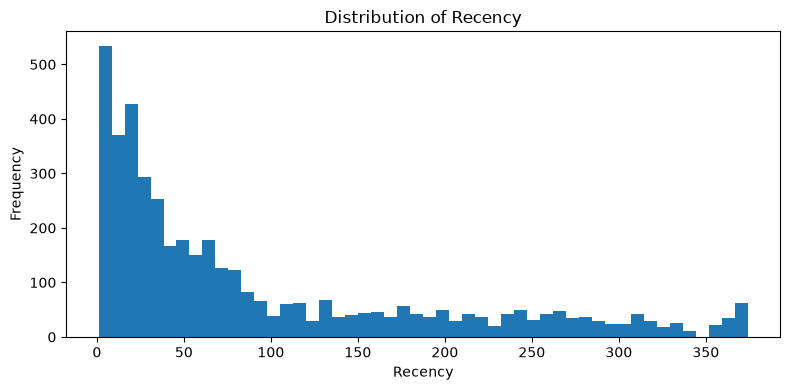

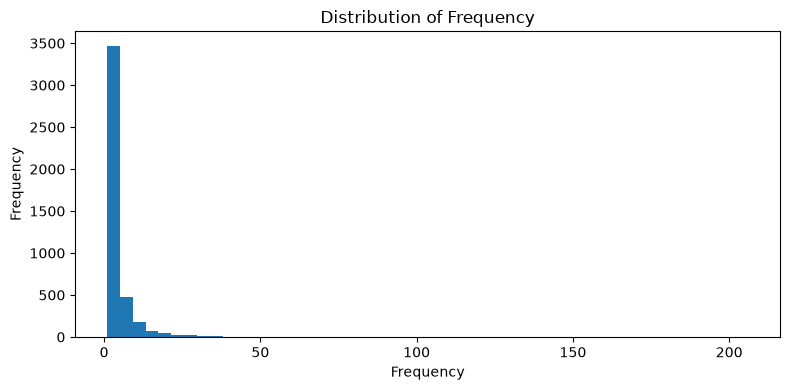

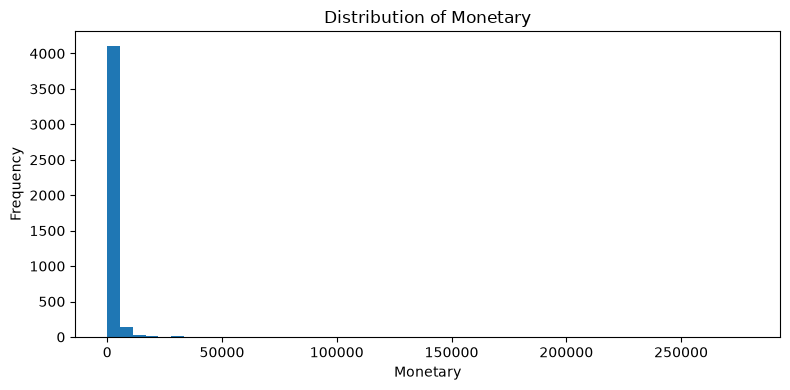

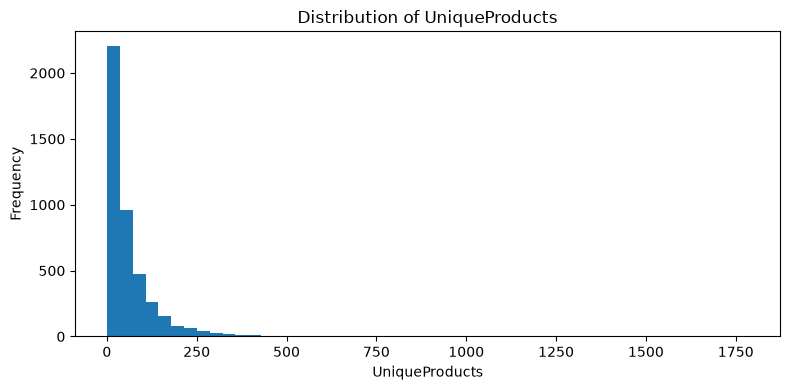

In [188]:
import matplotlib.pyplot as plt

skewness = X_kmeans.skew()

print("Skewness of K-Means Features:")
display(skewness.to_frame(name="Skewness").round(3))

for feature in kmeans_features:
    plt.figure(figsize=(8, 4))

    plt.hist(X_kmeans[feature], bins=50)

    plt.title(f"Distribution of {feature}")
    plt.xlabel(feature)
    plt.ylabel("Frequency")

    plt.tight_layout()
    plt.show()

### تصمیم آماده‌سازی: تبدیل لگاریتمی ویژگی‌های چوله

بر اساس محاسبه ضریب چولگی، مشخص شد که ویژگی‌های منتخب K-Means دارای توزیع‌های نامتقارن هستند.

ویژگی‌های `Frequency`، `Monetary` و `UniqueProducts` به‌ترتیب دارای ضرایب چولگی 11.948، 20.918 و 6.915 هستند که نشان‌دهنده چولگی مثبت شدید است.

بنابراین برای کاهش اثر مقادیر بسیار بزرگ، تبدیل لگاریتمی `log1p` برای این سه ویژگی انتخاب می‌شود.

ویژگی `Recency` با ضریب چولگی 1.242 فعلاً بدون تبدیل باقی می‌ماند؛ زیرا شدت چولگی آن نسبت به سایر ویژگی‌ها کمتر است.

پس از تبدیل، چولگی ویژگی‌ها مجدداً محاسبه خواهد شد تا میزان تغییر توزیع ارزیابی شود.

In [189]:
import numpy as np

X_kmeans_transformed = X_kmeans.copy()

log_features = [
    "Frequency",
    "Monetary",
    "UniqueProducts"
]

X_kmeans_transformed[log_features] = np.log1p(
    X_kmeans_transformed[log_features]
)

skewness_comparison = pd.DataFrame({
    "Before Transformation": X_kmeans.skew(),
    "After Transformation": X_kmeans_transformed.skew()
})

print("Skewness Comparison:")
display(skewness_comparison.round(3))

print("\nTransformed Feature Statistics:")
display(X_kmeans_transformed.describe().T)

Skewness Comparison:


,Before Transformation,After Transformation
Recency,1.242,1.242
Frequency,11.948,1.214
Monetary,20.918,0.360
UniqueProducts,6.915,-0.246



Transformed Feature Statistics:


,count,mean,std,min,25%,50%,75%,max
Recency,4333.0,93.220171,100.129302,1.000000,18.000000,51.000000,143.000000,374.000000
Frequency,4333.0,1.341695,0.681852,0.693147,0.693147,1.098612,1.791759,5.332719
Monetary,4333.0,6.571466,1.253291,1.360977,5.720213,6.493754,7.396065,12.539465
UniqueProducts,4333.0,3.549268,1.133040,0.693147,2.833213,3.583519,4.356709,7.487174


### نتیجه‌گیری مرحله ششم: بررسی و اصلاح چولگی توزیع ویژگی‌ها

در این مرحله، ضریب چولگی چهار ویژگی منتخب K-Means بررسی شد. نتایج اولیه نشان داد که سه ویژگی `Frequency`، `Monetary` و `UniqueProducts` دارای چولگی مثبت شدید هستند.

برای کاهش اثر مقادیر بسیار بزرگ، تبدیل لگاریتمی `log1p` روی این سه ویژگی اعمال شد.

مقایسه نتایج قبل و بعد از تبدیل نشان داد:

- چولگی Frequency از 11.948 به 1.214 کاهش یافت.
- چولگی Monetary از 20.918 به 0.360 کاهش یافت.
- چولگی UniqueProducts از 6.915 به 0.246- تغییر کرد.
- ویژگی Recency بدون تبدیل باقی ماند و چولگی آن 1.242 بود.

بنابراین تبدیل لگاریتمی توانست عدم تقارن شدید توزیع سه ویژگی را به میزان قابل‌توجهی کاهش دهد.

مجموعه‌داده تبدیل‌شده با نام `X_kmeans_transformed` برای مرحله مقیاس‌بندی ویژگی‌ها مورد استفاده قرار خواهد گرفت.

### مرحله هفتم: مقیاس‌بندی ویژگی‌ها (Feature Scaling)

#### هدف
قرار دادن ویژگی‌های منتخب در مقیاس قابل‌مقایسه، به‌منظور جلوگیری از تأثیر نامتناسب دامنه عددی ویژگی‌ها بر محاسبه فاصله‌ها.

#### دلیل انجام
K-Means از فاصله اقلیدسی برای تعیین شباهت و تشکیل خوشه‌ها استفاده می‌کند. در نتیجه، ویژگی‌هایی که دامنه عددی بزرگ‌تری دارند ممکن است بدون مقیاس‌بندی تأثیر بیشتری بر ساختار خوشه‌ها بگذارند.

#### روش انتخاب‌شده
در این مرحله از StandardScaler استفاده می‌شود. این روش با کم‌کردن میانگین و تقسیم بر انحراف معیار هر ویژگی، مقیاس آن‌ها را استاندارد می‌کند.

پس از مقیاس‌بندی، ویژگی‌ها میانگین نزدیک به صفر و انحراف معیار نزدیک به یک خواهند داشت.

خروجی این مرحله ماتریس استانداردشده‌ای است که برای آزمایش‌های بعدی الگوریتم K-Means استفاده می‌شود.

### مرحله هفتم: مقیاس‌بندی ویژگی‌ها (Feature Scaling)

#### هدف
قرار دادن ویژگی‌های منتخب در مقیاس قابل‌مقایسه، به‌منظور جلوگیری از تأثیر نامتناسب دامنه عددی ویژگی‌ها بر محاسبه فاصله‌ها.

#### دلیل انجام
K-Means از فاصله اقلیدسی برای تعیین شباهت و تشکیل خوشه‌ها استفاده می‌کند. در نتیجه، ویژگی‌هایی که دامنه عددی بزرگ‌تری دارند ممکن است بدون مقیاس‌بندی تأثیر بیشتری بر ساختار خوشه‌ها بگذارند.

#### روش انتخاب‌شده
در این مرحله از StandardScaler استفاده می‌شود. این روش با کم‌کردن میانگین و تقسیم بر انحراف معیار هر ویژگی، مقیاس آن‌ها را استاندارد می‌کند.

پس از مقیاس‌بندی، ویژگی‌ها میانگین نزدیک به صفر و انحراف معیار نزدیک به یک خواهند داشت.

خروجی این مرحله ماتریس استانداردشده‌ای است که برای آزمایش‌های بعدی الگوریتم K-Means استفاده می‌شود.

In [190]:
from sklearn.preprocessing import StandardScaler


scaler = StandardScaler()

X_kmeans_scaled = scaler.fit_transform(X_kmeans_transformed)

X_kmeans_scaled = pd.DataFrame(
    X_kmeans_scaled,
    columns=kmeans_features,
    index=X_kmeans_transformed.index
)

print("Scaled Feature Statistics:")
display(X_kmeans_scaled.describe().T)

print("\nMean:")
display(X_kmeans_scaled.mean().to_frame("Mean"))

print("\nStandard Deviation:")
display(X_kmeans_scaled.std().to_frame("Std"))

Scaled Feature Statistics:


,count,mean,std,min,25%,50%,75%,max
Recency,4333.0,3.607648e-17,1.000115,-0.921117,-0.751317,-0.421705,0.497213,2.804496
Frequency,4333.0,1.270876e-16,1.000115,-0.951267,-0.951267,-0.356545,0.660138,5.853891
Monetary,4333.0,-6.165799e-16,1.000115,-4.157925,-0.679292,-0.062013,0.658023,4.762412
UniqueProducts,4333.0,-4.050405e-16,1.000115,-2.521050,-0.632049,0.030233,0.712715,3.475924



Mean:


,Mean
Recency,3.607648e-17
Frequency,1.270876e-16
Monetary,-6.165799e-16
UniqueProducts,-4.050405e-16



Standard Deviation:


,Std
Recency,1.000115
Frequency,1.000115
Monetary,1.000115
UniqueProducts,1.000115


### نتیجه‌گیری مرحله هفتم: مقیاس‌بندی ویژگی‌ها

در این مرحله، چهار ویژگی منتخب K-Means با استفاده از روش StandardScaler مقیاس‌بندی شدند.

نتایج نشان داد:

- میانگین هر چهار ویژگی پس از مقیاس‌بندی تقریباً صفر است.
- انحراف معیار محاسبه‌شده توسط StandardScaler برای هر چهار ویژگی برابر با یک است.
- تعداد نمونه‌ها همچنان ۴۳۳۳ مشتری و تعداد ویژگی‌ها چهار ستون باقی مانده است.

بنابراین، ویژگی‌ها از نظر مقیاس عددی در وضعیت قابل‌مقایسه‌ای قرار گرفته‌اند و اثر اختلاف دامنه اولیه آن‌ها بر محاسبه فاصله اقلیدسی کاهش یافته است.

ماتریس `X_kmeans_scaled` به‌عنوان ورودی استانداردشده برای اجرای الگوریتم K-Means آماده است.

### مرحله هشتم: تعیین تعداد بهینه خوشه‌ها با روش Elbow

#### هدف
تعیین تعداد مناسب خوشه‌ها برای بخش‌بندی مشتریان با استفاده از الگوریتم K-Means.

#### دلیل انجام
تعداد خوشه‌ها یکی از پارامترهای اصلی الگوریتم K-Means است. انتخاب تعداد بسیار کم ممکن است تفاوت‌های رفتاری مشتریان را پنهان کند و انتخاب تعداد بسیار زیاد می‌تواند به ایجاد گروه‌های غیرضروری و دشوار برای تفسیر منجر شود.

#### روش انتخاب‌شده
در این مرحله، الگوریتم K-Means برای مقادیر مختلف K اجرا می‌شود و مقدار WCSS یا Inertia برای هر مقدار ثبت خواهد شد.

سپس نمودار Elbow رسم می‌شود تا نقطه‌ای که پس از آن کاهش WCSS کندتر می‌شود، شناسایی شود.

روش Elbow یک ابزار اکتشافی برای انتخاب تعداد خوشه‌هاست و نتیجه آن باید در کنار کیفیت جداسازی خوشه‌ها و قابلیت تفسیر تجاری بررسی شود.

,Number of Clusters (K),WCSS
0,2,9396.828546
1,3,6812.815242
2,4,5439.181747
3,5,4768.333726
4,6,4274.179878
5,7,3935.005311
6,8,3657.433609
7,9,3427.407394
8,10,3229.153650


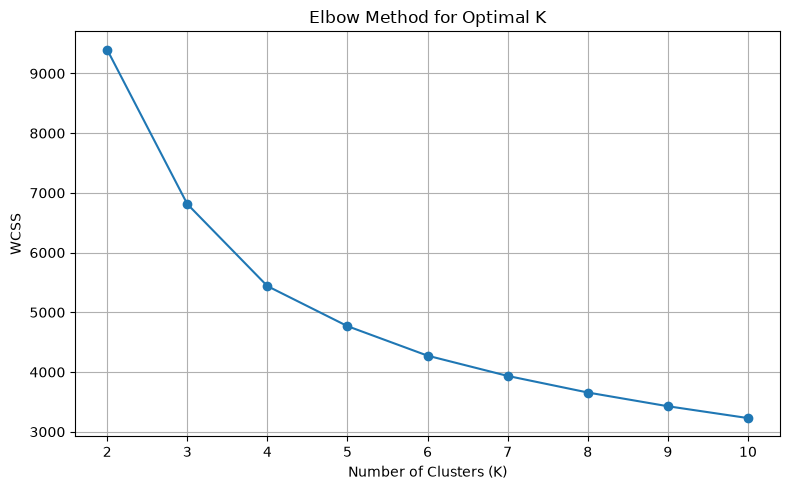

In [191]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt


k_values = range(2, 11)

wcss = []

for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_kmeans_scaled)

    wcss.append(kmeans.inertia_)


elbow_results = pd.DataFrame({
    "Number of Clusters (K)": list(k_values),
    "WCSS": wcss
})

display(elbow_results)


plt.figure(figsize=(8, 5))

plt.plot(
    list(k_values),
    wcss,
    marker="o"
)

plt.title("Elbow Method for Optimal K")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS")
plt.xticks(list(k_values))
plt.grid(True)
plt.tight_layout()
plt.show()

### نتیجه‌گیری مرحله هشتم: تعیین تعداد بهینه خوشه‌ها با روش Elbow

در این مرحله، الگوریتم K-Means برای مقادیر K از 2 تا 10 اجرا شد و مقدار WCSS برای هر حالت محاسبه گردید.

نتایج نشان دادند که با افزایش تعداد خوشه‌ها، WCSS کاهش می‌یابد؛ اما میزان این کاهش از Kهای بالاتر کمتر می‌شود. این تغییر روند نشان می‌دهد که نقطه آرنج احتمالی نمودار در محدوده K=4 تا K=5 قرار دارد.

با توجه به اینکه روش Elbow به‌تنهایی معیار قطعی انتخاب تعداد خوشه‌ها نیست، انتخاب نهایی K به بررسی معیار Silhouette و مقایسه کیفیت جداسازی خوشه‌ها نیز وابسته خواهد بود.

In [192]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

k_values = [3, 4, 5, 6]
silhouette_results = []

for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X_kmeans_scaled)

    score = silhouette_score(
        X_kmeans_scaled,
        labels
    )

    silhouette_results.append({
        "K": k,
        "Silhouette Score": score
    })

silhouette_df = pd.DataFrame(silhouette_results)

display(silhouette_df)

,K,Silhouette Score
0,3,0.349203
1,4,0.312193
2,5,0.280334
3,6,0.268466


### نتیجه‌گیری مرحله نهم: ارزیابی خوشه‌بندی با Silhouette Score

برای ارزیابی کیفیت خوشه‌بندی، معیار Silhouette Score برای مقادیر K برابر با 3، 4، 5 و 6 محاسبه شد.

بالاترین امتیاز مربوط به K=3 با مقدار 0.349203 بود. با افزایش تعداد خوشه‌ها، مقدار این معیار کاهش یافت.

در مقایسه با نتایج روش Elbow، مشخص شد که دو معیار پیشنهاد یکسانی ندارند. بنابراین K=3 به‌عنوان گزینه اولیه انتخاب شد، اما تصمیم نهایی پس از بررسی اندازه خوشه‌ها و ویژگی‌های رفتاری مشتریان اتخاذ خواهد شد.

In [193]:
from sklearn.cluster import KMeans

final_kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

customer_data["Cluster"] = final_kmeans.fit_predict(
    X_kmeans_scaled
)

display(customer_data.head())

,CustomerID,Frequency,Monetary,TotalQuantity,UniqueProducts,ActiveDays,FirstPurchase,LastPurchase,Recency,Cluster
0,12347,7,4310.00,2458,103,7,2010-12-07 14:57:00,2011-12-07 15:52:00,3,0
1,12348,4,1437.24,2332,21,4,2010-12-16 19:09:00,2011-09-25 13:13:00,76,2
2,12349,1,1457.55,630,72,1,2011-11-21 09:51:00,2011-11-21 09:51:00,19,2
3,12350,1,294.40,196,16,1,2011-02-02 16:01:00,2011-02-02 16:01:00,311,1
4,12352,7,1385.74,526,57,7,2011-02-16 12:33:00,2011-11-03 14:37:00,37,0


In [194]:
cluster_counts = (
    customer_data["Cluster"]
    .value_counts()
    .sort_index()
)

cluster_summary = pd.DataFrame({
    "Number of Customers": cluster_counts,
    "Percentage": (
        cluster_counts / len(customer_data) * 100
    )
})

display(cluster_summary)

,Number of Customers,Percentage
Cluster,,
0,1414,32.633279
1,955,22.040157
2,1964,45.326564


### نتیجه‌گیری مرحله دهم: اجرای مدل نهایی K-Means

با توجه به نتایج روش Elbow و معیار Silhouette، مقدار K=3 به‌عنوان گزینه اولیه انتخاب شد. سپس الگوریتم K-Means با سه خوشه و پارامترهای `random_state=42` و `n_init=10` اجرا گردید.

شناسه خوشه هر مشتری به مجموعه داده مشتریان اضافه شد.

توزیع مشتریان در خوشه‌ها به شرح زیر است:

- Cluster 0: تعداد 1414 مشتری، معادل 32.63 درصد
- Cluster 1: تعداد 955 مشتری، معادل 22.04 درصد
- Cluster 2: تعداد 1964 مشتری، معادل 45.33 درصد

هر سه خوشه تعداد قابل‌توجهی مشتری دارند و خوشه‌ای با اندازه بسیار کوچک یا خالی مشاهده نشد.

در این مرحله فقط ساختار اولیه خوشه‌ها بررسی شده است و هنوز نمی‌توان درباره رفتار یا ارزش تجاری مشتریان هر خوشه نتیجه‌گیری کرد.

In [195]:
cluster_profile = (
    customer_data
    .groupby("Cluster")
    .agg(
        CustomerCount=("CustomerID", "count"),

        Recency_Mean=("Recency", "mean"),
        Recency_Median=("Recency", "median"),

        Frequency_Mean=("Frequency", "mean"),
        Frequency_Median=("Frequency", "median"),

        Monetary_Mean=("Monetary", "mean"),
        Monetary_Median=("Monetary", "median"),

        UniqueProducts_Mean=("UniqueProducts", "mean"),
        UniqueProducts_Median=("UniqueProducts", "median"),

        TotalQuantity_Mean=("TotalQuantity", "mean"),
        TotalQuantity_Median=("TotalQuantity", "median"),

        ActiveDays_Mean=("ActiveDays", "mean"),
        ActiveDays_Median=("ActiveDays", "median")
    )
    .round(2)
)

display(cluster_profile)

,CustomerCount,Recency_Mean,Recency_Median,Frequency_Mean,Frequency_Median,Monetary_Mean,Monetary_Median,UniqueProducts_Mean,UniqueProducts_Median,TotalQuantity_Mean,TotalQuantity_Median,ActiveDays_Mean,ActiveDays_Median
Cluster,,,,,,,,,,,,,
0,1414,32.00,18.0,9.29,6.0,4906.72,2369.04,128.93,100.0,2868.96,1405.0,8.19,6.0
1,955,254.59,255.0,1.30,1.0,349.11,256.44,18.83,14.0,198.95,130.0,1.26,1.0
2,1964,58.83,48.0,2.05,2.0,620.55,496.14,33.54,28.0,376.67,281.0,1.98,2.0


### نتیجه‌گیری مرحله یازدهم: تحلیل و پروفایل‌سازی خوشه‌ها

پس از اجرای الگوریتم K-Means با سه خوشه، ویژگی‌های رفتاری مشتریان با استفاده از میانگین و میانه بررسی شد.

نتایج نشان دادند:

**Cluster 0:** شامل مشتریانی با تعداد خرید، مبلغ خرید، تنوع محصولات و روزهای فعالیت بالاتر و Recency پایین‌تر است. این گروه به‌عنوان مشتریان پرتکرار و باارزش شناسایی شد.

**Cluster 1:** شامل مشتریانی با تعداد خرید و مبلغ خرید پایین، فعالیت محدود و Recency بالا است. این گروه به‌عنوان مشتریان کم‌تعامل و غیرفعال شناسایی شد.

**Cluster 2:** بزرگ‌ترین خوشه است و مشتریانی با سطح متوسطی از تعداد خرید، مبلغ خرید و فعالیت را در بر می‌گیرد.

در مجموع، خوشه‌بندی توانست سه الگوی رفتاری متمایز را در مشتریان شناسایی کند. این بخش‌بندی می‌تواند برای طراحی راهبردهای متفاوت بازاریابی، حفظ مشتریان ارزشمند و بازگرداندن مشتریان کم‌تعامل مورد استفاده قرار گیرد.

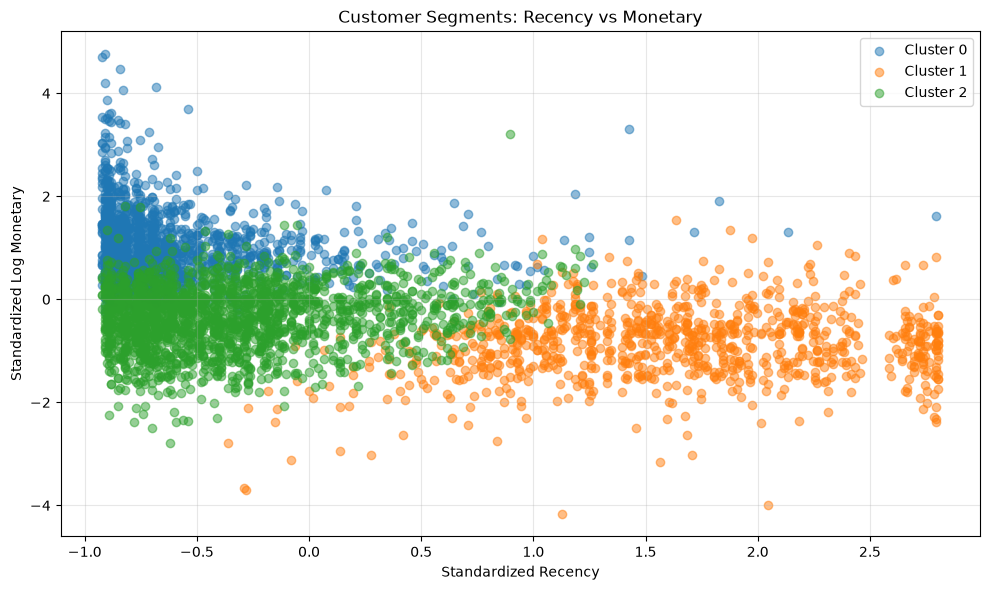

In [196]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

for cluster in sorted(customer_data["Cluster"].unique()):
    mask = customer_data["Cluster"] == cluster

    plt.scatter(
        X_kmeans_scaled.loc[mask, "Recency"],
        X_kmeans_scaled.loc[mask, "Monetary"],
        label=f"Cluster {cluster}",
        alpha=0.5
    )

plt.title("Customer Segments: Recency vs Monetary")
plt.xlabel("Standardized Recency")
plt.ylabel("Standardized Log Monetary")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### نتیجه‌گیری مرحله دوازدهم: بررسی بصری خوشه‌های مشتریان

در این مرحله، نمودار پراکندگی مشتریان بر اساس دو ویژگی Recency و Monetary بررسی شد. هر دو ویژگی پیش از ترسیم استانداردسازی شده بودند و Monetary نیز تبدیل لگاریتمی شده بود.

نتایج بصری با پروفایل عددی خوشه‌ها هم‌خوانی داشتند:

- **Cluster 0:** مشتریان با ارزش خرید و فعالیت بالاتر و Recency پایین‌تر؛ مناسب برای راهبردهای حفظ مشتری و وفادارسازی.
- **Cluster 1:** مشتریان با ارزش خرید و تعداد خرید پایین و Recency بالا؛ مناسب برای بررسی راهبردهای بازگشت مشتری.
- **Cluster 2:** مشتریان با رفتار خرید متوسط؛ دارای ظرفیت بالقوه برای افزایش تعامل و ارزش خرید.

همچنین هم‌پوشانی نسبی میان بعضی نقاط خوشه‌ها مشاهده شد. این موضوع با توجه به نمایش دوبعدی یک مدل چهاربعدی قابل انتظار است.

در مجموع، بررسی بصری و تحلیل آماری، وجود سه الگوی رفتاری متفاوت را در مشتریان تأیید می‌کنند؛ با این محدودیت که این نمودار به‌تنهایی معیار قطعی کیفیت خوشه‌بندی نیست.

In [197]:
cluster_centers = pd.DataFrame(
    final_kmeans.cluster_centers_,
    columns=kmeans_features
)

display(cluster_centers.round(3))

,Recency,Frequency,Monetary,UniqueProducts
0,-0.613,1.118,1.059,0.939
1,1.612,-0.788,-0.851,-0.840
2,-0.342,-0.420,-0.348,-0.267


### نتیجه‌گیری مرحله سیزدهم: بررسی مراکز خوشه‌ها

در این مرحله، مراکز سه خوشه استخراج‌شده از الگوریتم K-Means بررسی شدند.

از آنجا که مدل روی داده‌های لگاریتمی و استانداردشده آموزش دیده است، مقادیر مراکز نیز در فضای استانداردشده قرار دارند.

نتایج نشان دادند:

- **Cluster 0:** دارای Frequency، Monetary و UniqueProducts بالاتر از میانگین و Recency پایین‌تر از میانگین است. این گروه نمایانگر مشتریان پرتکرار و باارزش است.
- **Cluster 1:** دارای Recency بالاتر و سه ویژگی دیگر پایین‌تر از میانگین است. این گروه نمایانگر مشتریان غیرفعال و کم‌تعامل است.
- **Cluster 2:** در هر چهار ویژگی به میانگین کل نزدیک‌تر است و رفتار خرید متوسطی دارد.

این نتایج با تحلیل آماری و بصری مراحل قبل هم‌خوانی دارند و تفسیر رفتاری سه خوشه را تقویت می‌کنند.

In [198]:
centers_transformed = scaler.inverse_transform(
    final_kmeans.cluster_centers_
)

centers_transformed = pd.DataFrame(
    centers_transformed,
    columns=kmeans_features
)

centers_original = centers_transformed.copy()

centers_original[log_features] = np.expm1(
    centers_original[log_features]
)

display(centers_original.round(2))

,Recency,Frequency,Monetary,UniqueProducts
0,31.85,7.20,2693.93,99.84
1,254.64,1.23,244.80,12.43
2,58.99,1.87,461.15,24.71


### نتیجه‌گیری مرحله چهاردهم: بازگرداندن مراکز خوشه‌ها به مقیاس اصلی

در این مرحله، مراکز خوشه‌های K-Means ابتدا با استفاده از `inverse_transform` از مقیاس استانداردشده خارج شدند و سپس تبدیل لگاریتمی ویژگی‌های Frequency، Monetary و UniqueProducts معکوس شد.

نتایج نشان دادند:

- Cluster 0 دارای کمترین Recency و بالاترین مقادیر Frequency، Monetary و UniqueProducts است.
- Cluster 1 دارای بیشترین Recency و پایین‌ترین مقادیر سه ویژگی دیگر است.
- Cluster 2 از نظر هر چهار ویژگی در سطحی بین دو خوشه دیگر قرار دارد.

این مقادیر برای تفسیر موقعیت مراکز خوشه‌ها در مقیاس اولیه مناسب هستند؛ با این حال، به دلیل غیرخطی‌بودن تبدیل لگاریتمی، نباید آن‌ها را معادل میانگین واقعی اعضای خوشه در نظر گرفت.

In [199]:
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score
import pandas as pd

stability_results = []

baseline_labels = customer_data["Cluster"].to_numpy()

for seed in range(10):
    model = KMeans(
        n_clusters=3,
        random_state=seed,
        n_init=10
    )

    new_labels = model.fit_predict(X_kmeans_scaled)

    ari = adjusted_rand_score(
        baseline_labels,
        new_labels
    )

    stability_results.append({
        "Random State": seed,
        "WCSS": model.inertia_,
        "ARI": ari
    })

stability_df = pd.DataFrame(stability_results)

display(stability_df.round(4))

print("Mean ARI:", stability_df["ARI"].mean())
print("Minimum ARI:", stability_df["ARI"].min())
print("Maximum ARI:", stability_df["ARI"].max())

,Random State,WCSS,ARI
0,0,6812.8051,0.9993
1,1,6812.8152,1.0000
2,2,6812.8698,0.9970
3,3,6812.8152,1.0000
4,4,6812.7741,0.9985
5,5,6812.8307,0.9960
6,6,6812.8848,0.9813
7,7,6812.7715,0.9985
8,8,6812.8152,1.0000
9,9,6812.8307,0.9993


Mean ARI: 0.9970023685763054
Minimum ARI: 0.9813340044899691
Maximum ARI: 1.0


### نتیجه‌گیری مرحله پانزدهم: بررسی پایداری خوشه‌بندی

برای بررسی پایداری الگوریتم K-Means، مدل با تعداد سه خوشه و ده مقدار متفاوت برای `random_state` اجرا شد.

نتایج هر اجرا با تقسیم‌بندی اولیه با استفاده از معیار Adjusted Rand Index (ARI) مقایسه شدند.

نتایج به شرح زیر بود:

- میانگین ARI: 0.9970
- حداقل ARI: 0.9813
- حداکثر ARI: 1.0000

همچنین مقادیر WCSS در تمام اجراها بسیار نزدیک به یکدیگر بودند.

این نتایج نشان می‌دهند ساختار خوشه‌بندی نسبت به تغییر مقداردهی اولیه پایدار است و الگوریتم در اجراهای مختلف تقریباً تقسیم‌بندی یکسانی تولید می‌کند.

با این حال، پایداری بالا به‌تنهایی تضمین‌کننده کیفیت تجاری یا جداسازی کامل خوشه‌ها نیست و باید در کنار سایر معیارهای ارزیابی تفسیر شود.

In [200]:
from sklearn.metrics import silhouette_samples

sample_silhouette = silhouette_samples(
    X_kmeans_scaled,
    customer_data["Cluster"]
)

customer_data["Silhouette"] = sample_silhouette

cluster_silhouette = (
    customer_data
    .groupby("Cluster")
    .agg(
        Mean_Silhouette=("Silhouette", "mean"),
        Min_Silhouette=("Silhouette", "min"),
        Max_Silhouette=("Silhouette", "max"),
        Negative_Silhouette_Count=(
            "Silhouette",
            lambda x: (x < 0).sum()
        )
    )
)

display(cluster_silhouette.round(4))

,Mean_Silhouette,Min_Silhouette,Max_Silhouette,Negative_Silhouette_Count
Cluster,,,,
0,0.3808,-0.0203,0.5812,6
1,0.3458,-0.0388,0.5522,17
2,0.3281,-0.0021,0.5722,1


### نتیجه‌گیری: ارزیابی کیفیت جداسازی خوشه‌ها با Silhouette

در این مرحله، میانگین و دامنه ضریب Silhouette برای هر یک از سه خوشه محاسبه شد تا کیفیت تخصیص مشتریان به خوشه‌ها بررسی شود.

نتایج نشان داد:

- خوشه صفر با میانگین Silhouette برابر با 0.3808 بهترین کیفیت جداسازی نسبی را دارد.
- خوشه یک با مقدار 0.3458 در رتبه دوم قرار دارد.
- خوشه دو با مقدار 0.3281 کمترین میانگین را دارد.
- از مجموع 4333 مشتری، تنها 24 مشتری دارای Silhouette منفی هستند؛ بنابراین تعداد نمونه‌هایی که احتمال تخصیص نامناسب به خوشه دارند، بسیار محدود است.

با وجود نتایج مثبت، میانگین‌های Silhouette نشان می‌دهند که جداسازی خوشه‌ها کاملاً قوی و بدون هم‌پوشانی نیست. بنابراین، کیفیت خوشه‌بندی باید در کنار تفسیر تجاری خوشه‌ها و نتایج تحلیل پایداری ارزیابی شود.

در مجموع، مدل K-Means با سه خوشه، ساختار نسبتاً قابل قبولی از مشتریان ایجاد کرده است و می‌توان از آن برای تحلیل و بخش‌بندی مشتریان استفاده کرد.

---

### هدف مرحله

در این مرحله، بر اساس ویژگی‌های رفتاری مشتریان در هر خوشه، برای هر Cluster یک نام تجاری انتخاب می‌کنیم.

نام‌گذاری باید بر اساس شاخص‌های واقعی هر خوشه انجام شود، نه صرفاً شماره خوشه؛ زیرا شماره‌های K-Means معنای تجاری خاصی ندارند.

### سگمنت‌های شناسایی‌شده

**Cluster 0 — مشتریان وفادار و ارزشمند (VIP / Loyal Customers)**

ویژگی‌ها:
- تعداد خرید بالا
- ارزش خرید بالا
- تنوع محصولات خریداری‌شده بالا
- فاصله زمانی کم از آخرین خرید

استراتژی پیشنهادی:
- ارائه پیشنهادهای اختصاصی
- برنامه‌های وفاداری و پاداش خرید
- اطلاع‌رسانی محصولات جدید و پیشنهادهای مرتبط

**Cluster 1 — مشتریان غیرفعال یا کم‌تعامل (Dormant / Low-Engagement Customers)**

ویژگی‌ها:
- فاصله زمانی زیاد از آخرین خرید
- تعداد خرید پایین
- ارزش خرید پایین
- تنوع محصولات پایین

استراتژی پیشنهادی:
- بررسی دلایل کاهش تعامل
- ارسال پیشنهاد بازگشت مشتری
- ارائه تخفیف یا پیشنهاد متناسب با سابقه خرید

توجه: این خوشه الزاماً به معنای مشتریان Churn شده نیست؛ فقط نشان‌دهنده رفتار کم‌تعامل در بازه داده‌های موجود است.

**Cluster 2 — مشتریان عادی و با تعامل متوسط (Regular / Occasional Customers)**

ویژگی‌ها:
- تعداد خرید متوسط
- ارزش خرید متوسط
- فاصله زمانی از آخرین خرید کمتر از خوشه یک
- تنوع محصولات متوسط

استراتژی پیشنهادی:
- تشویق به خرید مجدد
- پیشنهاد محصولات مکمل
- طراحی پیشنهادهایی برای افزایش دفعات خرید


In [201]:
segment_mapping = {
    0: "VIP / Loyal Customers",
    1: "Dormant / Low-Engagement Customers",
    2: "Regular / Occasional Customers"
}

customer_data["Segment"] = customer_data["Cluster"].map(segment_mapping)

display(
    customer_data[
        ["CustomerID", "Cluster", "Segment",
         "Recency", "Frequency", "Monetary", "UniqueProducts"]
    ].head(10)
)

,CustomerID,Cluster,Segment,Recency,Frequency,Monetary,UniqueProducts
0,12347,0,VIP / Loyal Customers,3,7,4310.00,103
1,12348,2,Regular / Occasional Customers,76,4,1437.24,21
2,12349,2,Regular / Occasional Customers,19,1,1457.55,72
3,12350,1,Dormant / Low-Engagement Customers,311,1,294.40,16
4,12352,0,VIP / Loyal Customers,37,7,1385.74,57
5,12353,1,Dormant / Low-Engagement Customers,205,1,89.00,4
6,12354,1,Dormant / Low-Engagement Customers,233,1,1079.40,58
7,12355,1,Dormant / Low-Engagement Customers,215,1,459.40,13
8,12356,0,VIP / Loyal Customers,23,3,2487.43,52
9,12357,0,VIP / Loyal Customers,34,1,6207.67,131


In [202]:
segment_summary = (
    customer_data
    .groupby(["Cluster", "Segment"])
    .agg(
        Customer_Count=("CustomerID", "nunique"),
        Average_Recency=("Recency", "mean"),
        Average_Frequency=("Frequency", "mean"),
        Average_Monetary=("Monetary", "mean"),
        Average_UniqueProducts=("UniqueProducts", "mean")
    )
    .reset_index()
)

display(segment_summary.round(2))

,Cluster,Segment,Customer_Count,Average_Recency,Average_Frequency,Average_Monetary,Average_UniqueProducts
0,0,VIP / Loyal Customers,1414,32.00,9.29,4906.72,128.93
1,1,Dormant / Low-Engagement Customers,955,254.59,1.30,349.11,18.83
2,2,Regular / Occasional Customers,1964,58.83,2.05,620.55,33.54


### نتیجه‌گیری: نام‌گذاری و تفسیر تجاری خوشه‌ها

پس از اجرای الگوریتم K-Means با سه خوشه، مشتریان بر اساس ویژگی‌های رفتاری خود به سه سگمنت تجاری تقسیم شدند:

1. **VIP / Loyal Customers:** شامل 1414 مشتری (32.63٪) با بیشترین میانگین تعداد خرید و ارزش خرید و کمترین میانگین فاصله از آخرین خرید.

2. **Dormant / Low-Engagement Customers:** شامل 955 مشتری (22.04٪) با بیشترین میانگین فاصله از آخرین خرید و کمترین میانگین تعداد و ارزش خرید.

3. **Regular / Occasional Customers:** شامل 1964 مشتری (45.33٪) که از نظر شاخص‌های رفتاری در سطحی بین دو گروه دیگر قرار دارند.

نتایج نشان می‌دهد که مدل توانسته است سه الگوی رفتاری متمایز از مشتریان شناسایی کند. این سگمنت‌بندی می‌تواند برای طراحی کمپین‌های بازاریابی، حفظ مشتریان ارزشمند، افزایش خرید مجدد و شناسایی مشتریان کم‌تعامل مورد استفاده قرار گیرد.

نکته مهم: سگمنت Dormant به معنای Churn قطعی نیست؛ این عنوان صرفاً رفتار مشتریان را در محدوده زمانی موجود در دیتاست توصیف می‌کند.

In [204]:
kmeans_output = customer_data[
    [
        "CustomerID",
        "Cluster",
        "Segment",
        "Recency",
        "Frequency",
        "Monetary",
        "UniqueProducts"
    ]
].copy()

kmeans_output.to_csv(
    "Customer_Segmentation_KMeans.csv",
    index=False,
    encoding="utf-8-sig"
)

print("K-Means segmentation file saved successfully.")
print("Shape:", kmeans_output.shape)

K-Means segmentation file saved successfully.
Shape: (4333, 7)


---

### هدف مرحله

در اولین مرحله، دیتاست آماده‌شده برای مسئله پیش‌بینی ریزش مشتریان را بارگذاری و بررسی می‌کنیم.

قبل از آموزش هر الگوریتمی باید مطمئن شویم:

1. دیتاست با موفقیت بارگذاری شده است.
2. متغیر هدف `Churn` وجود دارد.
3. توزیع کلاس‌های Churn و Non-Churn مشخص است.
4. مقادیر گمشده و رکوردهای تکراری بررسی شده‌اند.
5. ستون‌های شناسه و اطلاعات زمانی از ویژگی‌های ورودی مدل تفکیک شده‌اند.

### چرا این مرحله مهم است؟

در مسئله Classification، مدل از روی ویژگی‌های ورودی، مقدار متغیر هدف را یاد می‌گیرد.

اگر توزیع کلاس‌ها نامتوازن باشد، ممکن است مدل با پیش‌بینی مداوم کلاس پرتعداد، ظاهراً دقت خوبی به دست بیاورد؛ در حالی که مشتریان در معرض ریزش را درست شناسایی نکند.

همچنین باید از ورود اطلاعاتی که مستقیماً برچسب را ساخته‌اند یا اطلاعات آینده را افشا می‌کنند به ویژگی‌های مدل جلوگیری کنیم.


### هدف مرحله

تعیین بازه زمانی مناسب برای ساخت متغیر هدف Churn.

در این پروژه از دو پنجره زمانی استفاده می‌کنیم:

1. **Observation Window (پنجره مشاهده):** بازه‌ای که رفتار خرید گذشته مشتری را بررسی می‌کنیم. در این بازه ویژگی‌هایی مانند تعداد خرید، مجموع مبلغ خرید و تعداد محصولات خریداری‌شده استخراج می‌شوند.

2. **Prediction Window (پنجره پیش‌بینی):** بازه‌ای که پس از پنجره مشاهده قرار می‌گیرد و از آن برای تعیین وضعیت Churn استفاده می‌کنیم.

در طراحی اولیه پروژه:
- طول پنجره مشاهده: 180 روز
- طول پنجره پیش‌بینی: 90 روز

اگر مشتری در پنجره مشاهده خرید معتبر داشته باشد، وارد مجموعه مشتریان مورد بررسی می‌شود.

سپس اگر در پنجره پیش‌بینی خرید معتبری نداشته باشد، مقدار Churn برابر 1 و در غیر این صورت برابر 0 خواهد بود.

### نکته مهم

تاریخ مرجع باید به‌گونه‌ای انتخاب شود که پنجره پیش‌بینی آن به‌طور کامل داخل محدوده زمانی دیتاست قرار بگیرد. در غیر این صورت، ممکن است مشتریانی را به اشتباه ریزش‌کرده تشخیص دهیم که صرفاً اطلاعات آینده آن‌ها در دیتاست موجود نیست.

In [210]:
print("Transactions Shape:", transactions.shape)

print("\nInvoiceDate dtype:")
print(transactions["InvoiceDate"].dtype)

print("\nFirst Transaction:")
print(transactions["InvoiceDate"].min())

print("\nLast Transaction:")
print(transactions["InvoiceDate"].max())

Transactions Shape: (391055, 11)

InvoiceDate dtype:
datetime64[us]

First Transaction:
2010-12-01 08:26:00

Last Transaction:
2011-12-09 12:50:00


In [211]:
observation_days = 180
prediction_days = 90

last_transaction_date = transactions["InvoiceDate"].max()

reference_date = (
    last_transaction_date.normalize()
    + pd.Timedelta(days=1)
)

prediction_start = reference_date
prediction_end = (
    reference_date
    + pd.Timedelta(days=prediction_days)
)

print("Observation Window:", observation_days, "days")
print("Prediction Window:", prediction_days, "days")

print("\nReference Date:", reference_date)
print("Prediction Start:", prediction_start)
print("Prediction End:", prediction_end)

print("\nLast Available Transaction:", last_transaction_date)

Observation Window: 180 days
Prediction Window: 90 days

Reference Date: 2011-12-10 00:00:00
Prediction Start: 2011-12-10 00:00:00
Prediction End: 2012-03-09 00:00:00

Last Available Transaction: 2011-12-09 12:50:00


### نتیجه‌گیری: بررسی محدوده زمانی و انتخاب تاریخ مرجع

دیتاست تراکنش‌های معتبر شامل 391055 رکورد است و بازه زمانی آن از 2010-12-01 تا 2011-12-09 را پوشش می‌دهد.

در طراحی اولیه، پنجره مشاهده 180 روز و پنجره پیش‌بینی 90 روز در نظر گرفته شد.

بررسی اولیه نشان داد که انتخاب 2011-12-10 به‌عنوان تاریخ مرجع معتبر نیست؛ زیرا هیچ اطلاعاتی از پنجره پیش‌بینی در دیتاست وجود ندارد.

بنابراین تاریخ مرجع باید به ابتدای بازه‌ای منتقل شود که 90 روز اطلاعات آینده برای تعیین وضعیت مشتریان در دسترس باشد.

این تصمیم از برچسب‌گذاری اشتباه مشتریان به‌عنوان Churn جلوگیری می‌کند.

In [213]:
reference_date = (
    transactions["InvoiceDate"].max().normalize()
    - pd.Timedelta(days=90)
)

observation_start = (
    reference_date
    - pd.Timedelta(days=180)
)

print("Observation Start:", observation_start)
print("Reference Date:", reference_date)
print("Prediction End:", reference_date + pd.Timedelta(days=90))
print("Last Transaction:", transactions["InvoiceDate"].max())

Observation Start: 2011-03-14 00:00:00
Reference Date: 2011-09-10 00:00:00
Prediction End: 2011-12-09 00:00:00
Last Transaction: 2011-12-09 12:50:00


### نتیجه‌گیری: تعیین تاریخ مرجع و پنجره‌های زمانی

با توجه به آخرین تاریخ موجود در دیتاست، تاریخ مرجع 2011-09-10 انتخاب شد.

دو پنجره زمانی برای ساخت متغیر هدف و استخراج ویژگی‌ها تعریف شدند:

- Observation Window: از 2011-03-14 تا قبل از 2011-09-10، به مدت 180 روز.
- Prediction Window: از 2011-09-10 تا قبل از 2011-12-09، به مدت 90 روز.

در این طراحی، دو پنجره زمانی هم‌پوشانی ندارند و اطلاعات آینده وارد محاسبه ویژگی‌های گذشته نمی‌شود.

بنابراین، تاریخ مرجع و بازه‌های زمانی برای ادامه فرایند ساخت دیتاست Churn تعیین شدند.

---

### هدف مرحله

ساخت متغیر هدف Churn با استفاده از رفتار واقعی مشتریان در دو پنجره زمانی.

در این مرحله، مشتریانی انتخاب می‌شوند که حداقل یک خرید معتبر در پنجره مشاهده داشته‌اند.

سپس وضعیت خرید آن‌ها در پنجره پیش‌بینی بررسی می‌شود:

- مشتری بدون خرید در پنجره پیش‌بینی: Churn = 1
- مشتری دارای حداقل یک خرید در پنجره پیش‌بینی: Churn = 0

این برچسب‌ها برای آموزش مدل Classification استفاده خواهند شد.

In [214]:
observation_data = transactions[
    (transactions["InvoiceDate"] >= observation_start) &
    (transactions["InvoiceDate"] < reference_date)
].copy()

prediction_data = transactions[
    (transactions["InvoiceDate"] >= reference_date) &
    (transactions["InvoiceDate"] < prediction_end)
].copy()

print("Observation Data Shape:", observation_data.shape)
print("Prediction Data Shape:", prediction_data.shape)

print("\nObservation Date Range:")
print(observation_data["InvoiceDate"].min())
print(observation_data["InvoiceDate"].max())

print("\nPrediction Date Range:")
print(prediction_data["InvoiceDate"].min())
print(prediction_data["InvoiceDate"].max())

Observation Data Shape: (156872, 11)
Prediction Data Shape: (158204, 11)

Observation Date Range:
2011-03-14 08:05:00
2011-09-09 15:53:00

Prediction Date Range:
2011-09-11 10:35:00
2011-12-09 12:50:00


In [215]:
print("Reference Date:", reference_date)
print("Prediction Start:", prediction_start)
print("Prediction End:", prediction_end)

print("\nExpected Prediction End:")
print(reference_date + pd.Timedelta(days=90))

print("\nActual Prediction Maximum:")
print(prediction_data["InvoiceDate"].max())

print("\nTransactions on December 9:")
print(
    prediction_data[
        prediction_data["InvoiceDate"].dt.date ==
        pd.Timestamp("2011-12-09").date()
    ].shape[0]
)

Reference Date: 2011-09-10 00:00:00
Prediction Start: 2011-12-10 00:00:00
Prediction End: 2012-03-09 00:00:00

Expected Prediction End:
2011-12-09 00:00:00

Actual Prediction Maximum:
2011-12-09 12:50:00

Transactions on December 9:
604


In [216]:
observation_days = 180
prediction_days = 90

reference_date = (
    transactions["InvoiceDate"].max().normalize()
    - pd.Timedelta(days=prediction_days)
)

observation_start = (
    reference_date - pd.Timedelta(days=observation_days)
)

prediction_start = reference_date

prediction_end = (
    reference_date + pd.Timedelta(days=prediction_days)
)

print("Observation Start:", observation_start)
print("Reference Date:", reference_date)
print("Prediction Start:", prediction_start)
print("Prediction End:", prediction_end)

Observation Start: 2011-03-14 00:00:00
Reference Date: 2011-09-10 00:00:00
Prediction Start: 2011-09-10 00:00:00
Prediction End: 2011-12-09 00:00:00


In [217]:
observation_data = transactions[
    (transactions["InvoiceDate"] >= observation_start) &
    (transactions["InvoiceDate"] < reference_date)
].copy()

prediction_data = transactions[
    (transactions["InvoiceDate"] >= prediction_start) &
    (transactions["InvoiceDate"] < prediction_end)
].copy()

print("Observation Data Shape:", observation_data.shape)
print("Prediction Data Shape:", prediction_data.shape)

print("\nPrediction Date Range:")
print(prediction_data["InvoiceDate"].min())
print(prediction_data["InvoiceDate"].max())

Observation Data Shape: (156872, 11)
Prediction Data Shape: (157600, 11)

Prediction Date Range:
2011-09-11 10:35:00
2011-12-08 20:01:00


In [218]:
observation_customers = set(
    observation_data["CustomerID"].unique()
)

prediction_customers = set(
    prediction_data["CustomerID"].unique()
)

print("Customers in Observation Window:",
      len(observation_customers))

print("Customers in Prediction Window:",
      len(prediction_customers))

print("\nCustomers with purchases in both windows:",
      len(observation_customers & prediction_customers))

print("Customers only in Observation Window:",
      len(observation_customers - prediction_customers))

Customers in Observation Window: 2783
Customers in Prediction Window: 2882

Customers with purchases in both windows: 1719
Customers only in Observation Window: 1064


---

### هدف مرحله

ساخت متغیر هدف Churn بر اساس رفتار واقعی مشتریان در پنجره‌های زمانی تعیین‌شده.

در این مرحله، مشتریانی که حداقل یک خرید معتبر در پنجره مشاهده داشته‌اند، وارد دیتاست می‌شوند.

قوانین برچسب‌گذاری:

- اگر مشتری در پنجره پیش‌بینی خرید داشته باشد: `Churn = 0`
- اگر مشتری در پنجره پیش‌بینی خرید نداشته باشد: `Churn = 1`

این متغیر هدف در مراحل بعدی برای آموزش مدل‌های Classification استفاده خواهد شد.

In [219]:
churn_labels = pd.DataFrame({
    "CustomerID": list(observation_customers)
})

churn_labels["Churn"] = (
    ~churn_labels["CustomerID"].isin(prediction_customers)
).astype(int)

display(churn_labels.head(10))

,CustomerID,Churn
0,16384,0
1,16385,0
2,16386,0
3,16389,0
4,16392,1
5,16393,0
6,16394,0
7,16395,0
8,16398,1
9,16399,0


In [220]:
print("Churn Distribution:")
display(churn_labels["Churn"].value_counts().sort_index())

print("\nChurn Percentage:")
display(
    (churn_labels["Churn"].value_counts(normalize=True) * 100)
    .round(2)
)

print("\nDataset Shape:", churn_labels.shape)

Churn Distribution:


Churn
0    1719
1    1064
Name: count, dtype: int64


Churn Percentage:


Churn
0    61.77
1    38.23
Name: proportion, dtype: float64


Dataset Shape: (2783, 2)


----

### هدف مرحله

تبدیل تراکنش‌های مشتریان به یک جدول ویژگی در سطح CustomerID برای استفاده در مدل‌های Classification.

در این مرحله ویژگی‌های زیر استخراج می‌شوند:

| ویژگی | مفهوم |
|---|---|
| Frequency | تعداد فاکتورهای خرید مشتری |
| TotalSpend | مجموع ارزش خرید مشتری |
| TotalUnits | مجموع تعداد محصولات خریداری‌شده |
| UniqueProducts | تعداد محصولات منحصربه‌فرد |
| ActiveDays | تعداد روزهایی که مشتری خرید داشته است |
| AverageInvoiceValue | میانگین ارزش هر فاکتور |
| Recency | تعداد روزهای گذشته از آخرین خرید تا تاریخ مرجع |
| TenureDays | فاصله اولین تا آخرین خرید در پنجره مشاهده |
| AverageDaysBetweenPurchases | میانگین فاصله زمانی بین فاکتورهای مشتری |

### چرا ابتدا سطح فاکتور را می‌سازیم؟

داده خام در سطح ردیف کالا است؛ یعنی هر فاکتور ممکن است چندین ردیف محصول داشته باشد.

برای محاسبه Frequency و AverageInvoiceValue باید ابتدا ردیف‌های مربوط به هر فاکتور را تجمیع کنیم. در غیر این صورت، تعداد ردیف‌های کالا به‌اشتباه به‌عنوان تعداد دفعات خرید در نظر گرفته می‌شود.

### جلوگیری از Data Leakage

تمام ویژگی‌ها فقط از `observation_data` محاسبه می‌شوند. اطلاعات پنجره پیش‌بینی صرفاً برای تعیین برچسب Churn استفاده شده‌اند.

In [221]:
invoice_data_churn = (
    observation_data
    .groupby(["CustomerID", "InvoiceNo"])
    .agg(
        InvoiceDate=("InvoiceDate", "min"),
        InvoiceValue=("LineTotal", "sum"),
        TotalQuantity=("Quantity", "sum")
    )
    .reset_index()
)

print("Invoice-Level Shape:", invoice_data_churn.shape)

display(invoice_data_churn.head())

Invoice-Level Shape: (7979, 5)


,CustomerID,InvoiceNo,InvoiceDate,InvoiceValue,TotalQuantity
0,12347,549222,2011-04-07 10:43:00,636.25,483
1,12347,556201,2011-06-09 13:01:00,382.52,196
2,12347,562032,2011-08-02 08:48:00,584.91,277
3,12348,548955,2011-04-05 10:47:00,327.00,268
4,12352,546869,2011-03-17 16:00:00,120.33,63


In [222]:
customer_features = (
    observation_data
    .groupby("CustomerID")
    .agg(
        Frequency=("InvoiceNo", "nunique"),
        TotalSpend=("LineTotal", "sum"),
        TotalUnits=("Quantity", "sum"),
        UniqueProducts=("StockCode_Normalized", "nunique"),
        ActiveDays=("InvoiceDate", lambda x: x.dt.normalize().nunique()),
        FirstPurchase=("InvoiceDate", "min"),
        LastPurchase=("InvoiceDate", "max")
    )
    .reset_index()
)

customer_features["AverageInvoiceValue"] = (
    customer_features["TotalSpend"] /
    customer_features["Frequency"]
)

customer_features["Recency"] = (
    reference_date -
    customer_features["LastPurchase"].dt.normalize()
).dt.days

customer_features["TenureDays"] = (
    customer_features["LastPurchase"].dt.normalize() -
    customer_features["FirstPurchase"].dt.normalize()
).dt.days

invoice_dates = invoice_data_churn[
    ["CustomerID", "InvoiceDate"]
].copy()

invoice_dates["InvoiceDate"] = invoice_dates["InvoiceDate"].dt.normalize()

invoice_dates = invoice_dates.sort_values(
    ["CustomerID", "InvoiceDate"]
)

invoice_dates["PurchaseGap"] = (
    invoice_dates
    .groupby("CustomerID")["InvoiceDate"]
    .diff()
    .dt.days
)

average_gaps = (
    invoice_dates
    .groupby("CustomerID")["PurchaseGap"]
    .mean()
    .reset_index(name="AverageDaysBetweenPurchases")
)

customer_features = customer_features.merge(
    average_gaps,
    on="CustomerID",
    how="left"
)

print("Customer Features Shape:", customer_features.shape)

display(customer_features.head())

Customer Features Shape: (2783, 12)


,CustomerID,Frequency,TotalSpend,TotalUnits,UniqueProducts,ActiveDays,FirstPurchase,LastPurchase,AverageInvoiceValue,Recency,TenureDays,AverageDaysBetweenPurchases
0,12347,3,1603.68,956,50,3,2011-04-07 10:43:00,2011-08-02 08:48:00,534.56,39,117,58.5
1,12348,1,327.00,268,4,1,2011-04-05 10:47:00,2011-04-05 10:47:00,327.00,158,0,NaN
2,12352,2,240.66,126,7,2,2011-03-17 16:00:00,2011-03-22 16:08:00,120.33,172,5,5.0
3,12353,1,89.00,20,4,1,2011-05-19 17:47:00,2011-05-19 17:47:00,89.00,114,0,NaN
4,12354,1,1079.40,530,58,1,2011-04-21 13:11:00,2011-04-21 13:11:00,1079.40,142,0,NaN


### نتیجه‌گیری مرحله پنجم: مهندسی ویژگی‌ها (Feature Engineering)

در این مرحله، داده‌های تراکنشی بازه مشاهده به دو سطح فاکتور و مشتری تجمیع شدند. ابتدا با گروه‌بندی بر اساس شناسه مشتری و شماره فاکتور، اطلاعات هر فاکتور شامل تاریخ، ارزش کل و تعداد کالاها محاسبه شد. سپس با تجمیع داده‌ها در سطح مشتری، ۹ ویژگی شامل Frequency، TotalSpend، TotalUnits، UniqueProducts، ActiveDays، AverageInvoiceValue، Recency، TenureDays و AverageDaysBetweenPurchases استخراج شدند.

تمام ویژگی‌ها صرفاً از بازه مشاهده محاسبه شده‌اند و اطلاعات بازه پیش‌بینی در ساخت آن‌ها دخالت نداشته است. مقادیر گمشده ویژگی AverageDaysBetweenPurchases برای مشتریان تک‌فاکتوری نیز حفظ شدند، زیرا برای این مشتریان فاصله بین دو خرید قابل محاسبه نیست.

در پایان، یک جدول شامل ۲۷۸۳ مشتری و ۱۲ ستون ایجاد شد که مبنای اتصال برچسب ریزش و آماده‌سازی داده برای مدل طبقه‌بندی خواهد بود.

In [223]:
churn_data = customer_features.merge(
    churn_labels,
    on="CustomerID",
    how="inner"
)

print("Final Dataset Shape:", churn_data.shape)
display(churn_data.head())

Final Dataset Shape: (2783, 13)


,CustomerID,Frequency,TotalSpend,TotalUnits,UniqueProducts,ActiveDays,FirstPurchase,LastPurchase,AverageInvoiceValue,Recency,TenureDays,AverageDaysBetweenPurchases,Churn
0,12347,3,1603.68,956,50,3,2011-04-07 10:43:00,2011-08-02 08:48:00,534.56,39,117,58.5,0
1,12348,1,327.00,268,4,1,2011-04-05 10:47:00,2011-04-05 10:47:00,327.00,158,0,NaN,0
2,12352,2,240.66,126,7,2,2011-03-17 16:00:00,2011-03-22 16:08:00,120.33,172,5,5.0,0
3,12353,1,89.00,20,4,1,2011-05-19 17:47:00,2011-05-19 17:47:00,89.00,114,0,NaN,1
4,12354,1,1079.40,530,58,1,2011-04-21 13:11:00,2011-04-21 13:11:00,1079.40,142,0,NaN,1


In [224]:
print("Unique Customers:", churn_data["CustomerID"].nunique())

print("\nChurn Distribution:")
print(churn_data["Churn"].value_counts())

print("\nChurn Percentage:")
print(
    churn_data["Churn"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print("\nMissing Values:")
display(churn_data.isnull().sum())

Unique Customers: 2783

Churn Distribution:
Churn
0    1719
1    1064
Name: count, dtype: int64

Churn Percentage:
Churn
0    61.77
1    38.23
Name: proportion, dtype: float64

Missing Values:


CustomerID                        0
Frequency                         0
TotalSpend                        0
TotalUnits                        0
UniqueProducts                    0
ActiveDays                        0
FirstPurchase                     0
LastPurchase                      0
AverageInvoiceValue               0
Recency                           0
TenureDays                        0
AverageDaysBetweenPurchases    1252
Churn                             0
dtype: int64

### نتیجه‌گیری مرحله ششم: اتصال ویژگی‌ها به برچسب هدف

در این مرحله، جدول ویژگی‌های مشتریان با جدول برچسب ریزش از طریق ستون CustomerID و با استفاده از اتصال Inner Merge ترکیب شد. مجموعه نهایی شامل ۲۷۸۳ مشتری یکتا است و برای تمام مشتریان، برچسب هدف به‌درستی ثبت شده است.

از مجموع مشتریان، ۱۷۱۹ نفر (۶۱٫۷۷٪) در بازه پیش‌بینی حداقل یک خرید معتبر داشته‌اند و در گروه بدون ریزش قرار گرفته‌اند. همچنین ۱۰۶۴ نفر (۳۸٫۲۳٪) در این بازه خریدی نداشته‌اند و به‌عنوان مشتریان دارای برچسب ریزش مشخص شده‌اند.

بررسی مقادیر گمشده نشان داد که تنها ویژگی AverageDaysBetweenPurchases دارای ۱۲۵۲ مقدار گمشده است. این مقادیر ناشی از تک‌فاکتوری بودن مشتریان در بازه مشاهده هستند و به‌عنوان مقادیر غیرقابل محاسبه حفظ شدند تا در مرحله مدل‌سازی به‌صورت اصولی مدیریت شوند.

در پایان این مرحله، مجموعه داده اولیه موردنیاز برای مسئله طبقه‌بندی ریزش مشتریان آماده شد.

In [225]:
model_features = [
    "Frequency",
    "TotalSpend",
    "TotalUnits",
    "UniqueProducts",
    "ActiveDays",
    "AverageInvoiceValue",
    "Recency",
    "TenureDays",
    "AverageDaysBetweenPurchases"
]

X = churn_data[model_features].copy()
y = churn_data["Churn"].copy()

print("X Shape:", X.shape)
print("y Shape:", y.shape)

print("\nFeature Columns:")
print(X.columns.tolist())

print("\nTarget Distribution:")
print(y.value_counts())

X Shape: (2783, 9)
y Shape: (2783,)

Feature Columns:
['Frequency', 'TotalSpend', 'TotalUnits', 'UniqueProducts', 'ActiveDays', 'AverageInvoiceValue', 'Recency', 'TenureDays', 'AverageDaysBetweenPurchases']

Target Distribution:
Churn
0    1719
1    1064
Name: count, dtype: int64


### نتیجه‌گیری مرحله هفتم: انتخاب ویژگی‌ها و متغیر هدف

در این مرحله، ۹ ویژگی رفتاری مشتریان به‌عنوان متغیرهای ورودی مدل (X) انتخاب شدند. این ویژگی‌ها شامل Frequency، TotalSpend، TotalUnits، UniqueProducts، ActiveDays، AverageInvoiceValue، Recency، TenureDays و AverageDaysBetweenPurchases هستند.

ستون Churn نیز به‌عنوان متغیر هدف (y) تعیین شد. ستون‌های شناسایی و تاریخ‌های خام، شامل CustomerID، FirstPurchase و LastPurchase، از ورودی مدل حذف شدند.

در نتیجه، ماتریس ویژگی‌ها دارای ابعاد ۲۷۸۳ × ۹ و متغیر هدف دارای ۲۷۸۳ نمونه است. بنابراین مجموعه داده از نظر ساختار ورودی و خروجی برای ورود به مرحله مدل‌سازی آماده است.

In [226]:
import numpy as np

print("Missing Values:")
display(X.isnull().sum())

print("\nInfinite Values:")
print(np.isinf(X.select_dtypes(include="number")).sum())

print("\nTarget Unique Values:")
print(y.unique())

print("\nFeature Variance:")
display(X.var().round(4))

print("\nDuplicate CustomerIDs:")
print(churn_data["CustomerID"].duplicated().sum())

Missing Values:


Frequency                         0
TotalSpend                        0
TotalUnits                        0
UniqueProducts                    0
ActiveDays                        0
AverageInvoiceValue               0
Recency                           0
TenureDays                        0
AverageDaysBetweenPurchases    1252
dtype: int64


Infinite Values:
Frequency                      0
TotalSpend                     0
TotalUnits                     0
UniqueProducts                 0
ActiveDays                     0
AverageInvoiceValue            0
Recency                        0
TenureDays                     0
AverageDaysBetweenPurchases    0
dtype: int64

Target Unique Values:
[0 1]

Feature Variance:


Frequency                      1.747480e+01
TotalSpend                     2.037437e+07
TotalUnits                     7.375453e+06
UniqueProducts                 3.160218e+03
ActiveDays                     1.107870e+01
AverageInvoiceValue            4.290542e+05
Recency                        2.682629e+03
TenureDays                     3.512936e+03
AverageDaysBetweenPurchases    1.080475e+03
dtype: float64


Duplicate CustomerIDs:
0


### نتیجه‌گیری مرحله هشتم: کنترل نهایی داده‌ها

در این مرحله، مجموعه داده از نظر مقادیر گمشده، مقادیر بی‌نهایت، اعتبار متغیر هدف، واریانس ویژگی‌ها و شناسه‌های تکراری بررسی شد.

نتایج نشان داد که هیچ مقدار بی‌نهایت، شناسه مشتری تکراری یا ویژگی با واریانس صفر وجود ندارد. متغیر هدف نیز فقط شامل دو کلاس صفر و یک است.

تنها مقادیر گمشده مربوط به ویژگی AverageDaysBetweenPurchases هستند که برای مشتریان دارای یک فاکتور در بازه مشاهده قابل محاسبه نیستند. این مقادیر به‌عنوان داده‌های گمشده معتبر حفظ شدند تا متناسب با الگوریتم انتخابی در مرحله مدل‌سازی مدیریت شوند.

بنابراین، مجموعه داده از نظر ساختاری برای ورود به مرحله مدل‌سازی آماده است.

In [227]:
churn_data.to_csv(
    "Customer_Churn_Prepared.csv",
    index=False
)

print("File saved successfully.")

File saved successfully.


----